# TrDPNetD oficial · De una imagen a una nube de puntos 3D
### Inferencia con los **pesos publicados por los autores** · Procesamiento de Datos Secuenciales

| | |
|---|---|
| **Artículo base** | F. Li, T. Li, K. Xiao, L. Wang, L. Yu, *TrDPNet: A transformer-based diffusion model for single-image 3D point cloud reconstruction*, J. Vis. Commun. Image R. 111 (2025) 104503 |
| **Código original** | https://github.com/TLab512/TrDPNet |
| **Pesos preentrenados** | `TrDPNet_shapenet.pth` (enlace de Google Drive del repositorio oficial) |
| **Repositorio del proyecto** | https://github.com/JulianReneMunoz/TrDPNet |

## Qué cambia respecto de la versión anterior

La versión anterior usaba una réplica reducida de la arquitectura, entrenada localmente. **Esta versión no entrena nada**: reconstruye la arquitectura original tal como la publican los autores y carga sus pesos, que es exactamente lo que pide el enunciado.

Para lograrlo hay un obstáculo técnico que el notebook resuelve: el código oficial depende de extensiones CUDA que deben compilarse con `nvcc` y de PyTorch3D. Aquí esas cuatro operaciones geométricas —muestreo por punto más lejano, consulta por esfera, voxelización y devoxelización trilineal— **se reescriben con operaciones estándar de PyTorch**, con los mismos nombres de parámetros, de modo que los pesos cargan en modo estricto y la inferencia funciona sin compilar nada.

## La idea en una frase

Se parte de **ruido puro** y se le quita ruido paso a paso; en cada paso, un **Transformer** consulta los rasgos de la imagen extraídos por un ViT para decidir hacia dónde mover cada región de la nube. Al final del recorrido aparece el objeto 3D.

## Cómo leer este notebook

Cada resultado va acompañado de una tarjeta estructurada en tres bloques — *Qué muestra*,  *Análisis* y  *Interpretación*— y una línea  *Síntesis* que condensa la conclusión del apartado.

## Contenido del notebook

| Contenido | Sección |
|---|---|
| Pesos preentrenados, sin entrenar nada | 2 · El checkpoint oficial |
| Arquitectura en detalle | 3 · La arquitectura original reconstruida |
| Datos secuenciales y problema | 4 · Los datos reales |
| Entradas y salidas del modelo | 5 · Entradas y salidas |
| Mecanismo de atención y tensores Q, K, V | 6 · Atención |
| Innovaciones del modelo | 7 · Innovación |
| Inferencia funcional con visualización | 8 · Inferencia y resultados |
| Interfaz interactiva | 9 · Interfaz |

# 1 · Preparación del entorno

**Qué hace:** importa librerías, elige GPU o CPU, localiza el checkpoint oficial y el conjunto ShapeNet, y define las herramientas de presentación que se usan en todo el notebook.

**Configuración oficial** (tomada de `config/structured.py` del repositorio original): dimensión 768, 4 bloques Transformer, MLP de 3072, 512 centros, radio 0.1, 32 vecinos, ViT-B/16 congelado como codificador de imagen, 1000 pasos de difusión con betas lineales de 8.5·10⁻⁴ a 1.2·10⁻², escala de guía ω = 3 y factor de escala 7.

**Interruptores:**
- `PASOS_MUESTREO`: número de pasos que se recorren en la inferencia. Con 1000 se reproduce el muestreo completo del artículo; con menos se recorre el mismo programa a saltos (actualización determinista), que es la forma estándar de acelerar.
- `N_PUNTOS`: 8192 en el artículo. Reducirlo acelera de forma proporcional.
- `EVALUACION_COMPLETA = False` reutiliza las métricas registradas en la ejecución anterior, lo que permite recorrer el notebook sin repetir el cálculo.

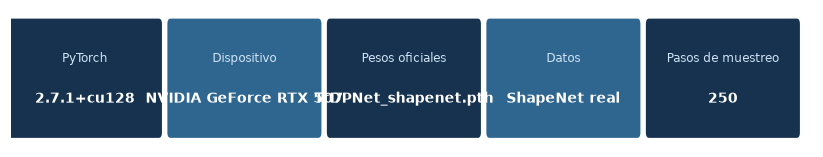

In [1]:
# =============================================================================
# 1 · PREPARACIÓN DEL ENTORNO
# =============================================================================
import os, sys, json, math, time, random, inspect
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.nn.functional as Fnn        # alias usado por los módulos oficiales
import matplotlib.pyplot as plt
from matplotlib import animation
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch, Rectangle, Circle, Polygon
from IPython.display import HTML, display

SMOKE = os.environ.get("TRDPNET_SMOKE", "0") == "1"        # uso interno: prueba rápida
EVALUACION_COMPLETA = True        # False reutiliza las métricas ya registradas
ANIMACIONES = True

# --- parámetros de inferencia --------------------------------------------------
PASOS_MUESTREO = 250              # 1000 = muestreo completo del artículo
N_PUNTOS = 8192                   # número de puntos de la nube generada
N_EVAL_POR_CAT = 1                # objetos por categoría en la evaluación cuantitativa
N_TEST_POR_CAT = 4                # objetos por categoría que se cargan del conjunto
OMEGAS_ABLACION = [1.0, 3.0, 5.0]

BASE = Path.cwd()
FIG = BASE / "latex" / "figuras"
for d in ["outputs", "outputs/animaciones", "latex/figuras", "streamlit_app", "ejemplos"]:
    (BASE / d).mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.grid": True, "grid.alpha": .25,
                     "figure.facecolor": "white", "animation.embed_limit": 100})

DEVICE = torch.device("cuda" if (torch.cuda.is_available() and
                                 os.environ.get("TRDPNET_FORCE_CPU") != "1") else "cpu")
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

# --- rutas: checkpoint oficial y conjunto de datos -----------------------------
RUTAS_CKPT = [Path(os.environ.get("TRDPNET_CKPT", "__sin_definir__")),
              Path(r"C:\Users\PersonalJR\Documents\Python Scripts\TrDPNet_entrega_v4\TrDPNet_shapenet.pth"),
              BASE / "weights" / "TrDPNet_shapenet.pth",
              BASE / "TrDPNet_shapenet.pth"]
RUTAS_SHAPENET = [Path(os.environ.get("TRDPNET_SHAPENET", "__sin_definir__")),
                  Path(r"C:\Users\PersonalJR\Documents\Python Scripts\ISR_ONET_HD_EG3D\data\ShapeNet"),
                  BASE / "data" / "ShapeNet"]
RUTA_CKPT = next((p for p in RUTAS_CKPT if p.exists()), None)
RUTA_SHAPENET = next((p for p in RUTAS_SHAPENET if p.exists()), None)

# --- configuración oficial (config/structured.py del repositorio original) -----
CFG = dict(dim=768, depth=4, mlp_dim=3072, drop_rate=0.1,
           n_centros=512, radio=0.1, vecinos=32, resolucion=32,
           img_size=224, vit="vit_base_patch16_224_mae", vit_dim=768, vit_depth=12, vit_heads=12,
           T=1000, beta_0=0.00085, beta_T=0.012, escala=7.0, omega=3.0,
           n_puntos=N_PUNTOS, pasos_muestreo=PASOS_MUESTREO, tau=0.05,
           n_test_por_cat=N_TEST_POR_CAT, n_eval_por_cat=N_EVAL_POR_CAT,
           omegas_ablacion=OMEGAS_ABLACION, datos="ShapeNet-R2N2 real")
if SMOKE:
    CFG.update(dim=192, depth=2, mlp_dim=384, n_centros=32, resolucion=8, img_size=64,
               vit_dim=192, vit_depth=2, vit_heads=3, T=50, n_puntos=512, pasos_muestreo=4,
               n_test_por_cat=2, n_eval_por_cat=1, omegas_ablacion=[1.0, 3.0])
    PASOS_MUESTREO, N_PUNTOS = 4, 512

# --- herramienta 1: tarjeta de resultados --------------------------------------
def tarjeta(titulo, muestra, analisis, interpretacion, sintesis=None):
    '''Presenta un resultado en tres bloques: qué muestra, análisis e interpretación.'''
    li = lambda xs: "".join(f"<li style='margin:3px 0'>{x}</li>" for x in xs)
    pie = (f"<div style='padding:8px 14px;background:#1f3b57;color:#fff'>📌 <b>Síntesis:</b> "
           f"{sintesis}</div>") if sintesis else ""
    html = f'''
<div style="border:1px solid #c9d3dd;border-radius:10px;margin:10px 0;overflow:hidden;
            font-family:Segoe UI,Arial,sans-serif;font-size:13px;line-height:1.4">
  <div style="background:#16324f;color:#fff;padding:8px 14px;font-weight:600;font-size:14px">{titulo}</div>
  <div style="display:grid;grid-template-columns:1fr 1.2fr 1.2fr">
    <div style="padding:10px 14px;background:#eaf2fb"><b>📊 Qué muestra</b><p style="margin:6px 0">{muestra}</p></div>
    <div style="padding:10px 14px;background:#fff7e3"><b>🔎 Análisis</b><ul style="padding-left:18px;margin:6px 0">{li(analisis)}</ul></div>
    <div style="padding:10px 14px;background:#e9f6ec"><b>💡 Interpretación</b><ul style="padding-left:18px;margin:6px 0">{li(interpretacion)}</ul></div>
  </div>{pie}
</div>'''
    display(HTML(html))

def anima(fig, actualiza, n_frames, nombre, fps=8):
    '''Genera la animación, la guarda como GIF y la incrusta con controles de reproducción.'''
    if not ANIMACIONES:
        plt.close(fig); print(f"[animación '{nombre}' desactivada]"); return
    ani = animation.FuncAnimation(fig, actualiza, frames=n_frames, interval=int(1000 / fps))
    try:
        ani.save(BASE / "outputs/animaciones" / f"{nombre}.gif", writer=animation.PillowWriter(fps=fps), dpi=80)
    except Exception as e:
        print("GIF no guardado (instale pillow):", type(e).__name__)
    display(HTML(ani.to_jshtml(fps=fps))); plt.close(fig)

def guarda(nombre):
    plt.savefig(FIG / f"{nombre}.png", bbox_inches="tight", dpi=130)

# --- resumen visual del entorno ------------------------------------------------
fig, ax = plt.subplots(figsize=(9.4, 1.6)); ax.axis("off")
items = [("PyTorch", torch.__version__),
         ("Dispositivo", torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "CPU"),
         ("Pesos oficiales", RUTA_CKPT.name if RUTA_CKPT else "no encontrados"),
         ("Datos", "ShapeNet real" if RUTA_SHAPENET else "no encontrados"),
         ("Pasos de muestreo", str(CFG["pasos_muestreo"]))]
for i, (k, v) in enumerate(items):
    ax.add_patch(FancyBboxPatch((i * 2.05, .1), 1.9, .8, boxstyle="round,pad=.04",
                                fc="#16324f" if i % 2 == 0 else "#2f6690", ec="none"))
    ax.text(i * 2.05 + .95, .62, k, ha="center", color="#cfe3f5", fontsize=8)
    ax.text(i * 2.05 + .95, .32, str(v)[:22], ha="center", color="white", fontsize=9, weight="bold")
ax.set_xlim(0, 10.3); ax.set_ylim(0, 1); plt.show()

if RUTA_CKPT is None:
    print("No se encontró el checkpoint oficial. Añada su ruta al principio de RUTAS_CKPT.")
tarjeta("1 · Entorno listo",
        "Versiones, dispositivo de cálculo y localización del checkpoint oficial y del conjunto de datos. "
        "La configuración no se inventa: es la del archivo <code>config/structured.py</code> del repositorio original.",
        [f"Dispositivo de cálculo: <b>{DEVICE}</b>.",
         f"Arquitectura declarada: dimensión {CFG['dim']}, {CFG['depth']} bloques, MLP de {CFG['mlp_dim']}, "
         f"{CFG['n_centros']} centros.",
         f"Difusión: {CFG['T']} pasos de entrenamiento, se recorren {CFG['pasos_muestreo']} en la inferencia.",
         f"Checkpoint: <code>{RUTA_CKPT if RUTA_CKPT else 'pendiente'}</code>."],
        ["Los pesos publicados imponen la arquitectura: cualquier diferencia de dimensión impide cargarlos, "
         "así que la configuración correcta se verifica sola en la sección 3.",
         "Recorrer el programa de difusión a saltos no cambia los pesos ni el modelo: solo salta pasos "
         "intermedios, igual que hace DDIM.",
         "Reducir el número de puntos o de pasos disminuye el coste de cómputo sin alterar la arquitectura."],
        "Ningún parámetro se entrena en este notebook: la totalidad del conocimiento del modelo procede de los pesos publicados por los autores.")

# 2 · El checkpoint oficial bajo la lupa

**Qué hace:** abre el archivo de pesos y lo describe antes de intentar cargarlo: cuántos tensores contiene, cómo se reparten entre los dos submodelos (la red de predicción de ruido y el ViT que codifica la imagen) y qué hiperparámetros se deducen de las formas de los tensores.

**Por qué este paso primero:** un `state_dict` es una lista de tensores con nombre. Sus **formas revelan la arquitectura**: si la matriz `qkv` de un bloque es de 2304×768, entonces la dimensión del modelo es 768 y hay tres proyecciones de 768. Deducirlo del archivo evita suposiciones y detecta de inmediato si el checkpoint no corresponde a esta arquitectura.

Contenido del archivo: model (OrderedDict), optimizer (dict), scheduler (dict), epoch (int), step (int), best_val (int), model_ema (dict), cfg (DictConfig)
Clases del repositorio original sustituidas (no afectan a los pesos): config.structured.AugmentationConfig, config.structured.CheckpointConfig, config.structured.DataloaderConfig, config.structured.ExponentialMovingAverageConfig, config.structured.LoggingConfig, config.structured.LossConfig, config.structured.MultiViewConfig, config.structured.OptimizerConfig, config.


,tensores,parametros,% del total
red de ruido (TrDPNet),144,38386307,30.9
codificador de imagen (ViT),150,85798656,69.1


hiperparámetro,deducido del archivo,de dónde sale,configuración oficial
Dimensión del modelo,768,de la matriz qkv: 3·768 × 768,768
Bloques Transformer,4,número de índices en encoder.blocks,4
Dimensión del MLP,3072,primera capa del avance directo,3072
Salida de la capa SA,768,último conv del MLP compartido,768
Bloques del ViT,12,índices en blocks.*,12
Parche del ViT,16,tamaño del conv de parches,16


Tensores: 294 · parámetros: 124 184 963
ViT incluido en el checkpoint: sí


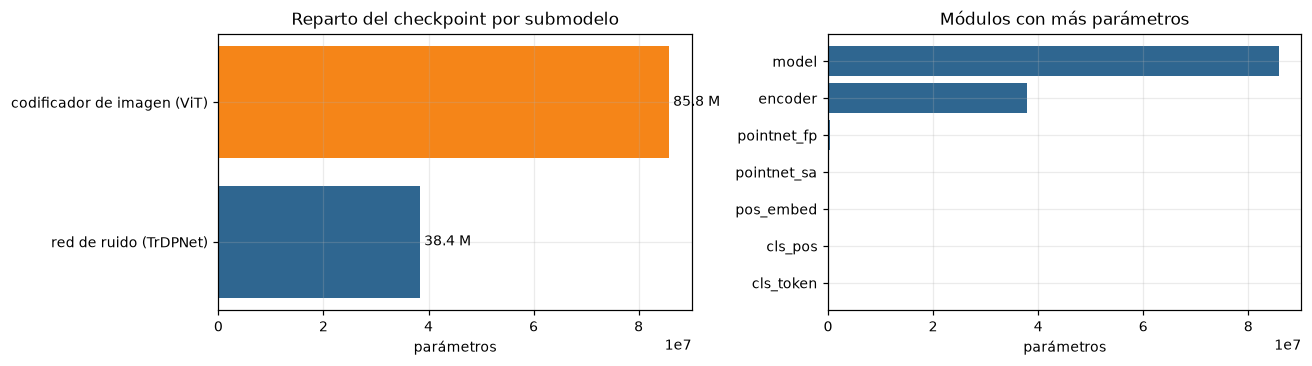

In [2]:
# =============================================================================
# 2 · INSPECCIÓN DEL CHECKPOINT OFICIAL
# =============================================================================
# Un checkpoint de entrenamiento no contiene solo tensores: suele guardar también objetos de
# configuración del proyecto original (aquí, clases del paquete `config` de los autores). Al abrirlo,
# Python intentaría importarlas y fallaría. El desempaquetador siguiente las sustituye por un objeto
# vacío: los tensores se leen igual y la configuración sobrante se ignora.
import pickle

class _Fantasma:
    '''Sustituto de cualquier clase del repositorio original que no esté instalada aquí.'''
    def __init__(self, *a, **k): pass
    def __setstate__(self, estado):
        self.__dict__.update(estado if isinstance(estado, dict) else {})

class _Desempaquetador(pickle.Unpickler):
    ausentes = set()
    def find_class(self, modulo, nombre):
        try:
            return super().find_class(modulo, nombre)
        except Exception:
            _Desempaquetador.ausentes.add(f"{modulo}.{nombre}")
            return _Fantasma

class _pickle_tolerante:
    Unpickler = _Desempaquetador
    @staticmethod
    def load(f, **kw):
        return _Desempaquetador(f, **kw).load()

def _es_tensor(v):
    return hasattr(v, "shape") and hasattr(v, "numel")

def busca_state_dict(obj, prof=0):
    '''Busca dentro del objeto cargado el diccionario con más tensores.'''
    if prof > 4 or _es_tensor(obj):
        return None
    mejor = None
    candidatos = [obj] if isinstance(obj, dict) else []
    if hasattr(obj, "__dict__") and not isinstance(obj, dict):
        candidatos.append(vars(obj))
    for d in candidatos:
        propios = {k: v for k, v in d.items() if isinstance(k, str) and _es_tensor(v)}
        if len(propios) >= 8 and (mejor is None or len(propios) > len(mejor)):
            mejor = propios
        for v in d.values():
            if _es_tensor(v):
                continue
            sub = busca_state_dict(v, prof + 1)
            if sub and (mejor is None or len(sub) > len(mejor)):
                mejor = sub
    return mejor

def abre_checkpoint(ruta):
    '''Abre el archivo y devuelve sus tensores, sea cual sea el envoltorio con que se guardó.'''
    ck = torch.load(ruta, map_location="cpu", weights_only=False, pickle_module=_pickle_tolerante)
    if isinstance(ck, dict):
        print("Contenido del archivo:", ", ".join(f"{k} ({type(v).__name__})" for k, v in ck.items())[:300])
    if _Desempaquetador.ausentes:
        print("Clases del repositorio original sustituidas (no afectan a los pesos):",
              ", ".join(sorted(_Desempaquetador.ausentes))[:300])
    sd = busca_state_dict(ck)
    if not sd:
        raise ValueError("No se encontró ningún conjunto de tensores dentro del archivo.")
    return sd, ck

def limpia_prefijos(sd):
    '''Quita los prefijos que añaden DataParallel o los envoltorios de entrenamiento.'''
    for pre in ["module.", "model.", "ema_model.", "_orig_mod."]:
        if all(k.startswith(pre) for k in sd):
            sd = {k[len(pre):]: v for k, v in sd.items()}
    return sd

SD, CK_CRUDO = abre_checkpoint(RUTA_CKPT)
SD = limpia_prefijos(SD)
n_total = sum(v.numel() for v in SD.values())

# --- reparto por submodelo -----------------------------------------------------
def familia(k):
    if k.startswith("point_cloud_model."): return "red de ruido (TrDPNet)"
    if k.startswith("feature_model."):     return "codificador de imagen (ViT)"
    if k.startswith(("pointnet_sa.", "encoder.", "pointnet_fp.", "pos_embed", "cls_")):
        return "red de ruido (TrDPNet)"
    if k.startswith(("blocks.", "patch_embed.", "norm.")): return "codificador de imagen (ViT)"
    return "otros"

resumen = {}
for k, v in SD.items():
    f = familia(k)
    d = resumen.setdefault(f, {"tensores": 0, "parametros": 0})
    d["tensores"] += 1; d["parametros"] += v.numel()
tab_ckpt = pd.DataFrame(resumen).T.astype(int)
tab_ckpt["% del total"] = (100 * tab_ckpt["parametros"] / n_total).round(1)
display(tab_ckpt)

# --- hiperparámetros deducidos de las formas -----------------------------------
def busca(sufijo):
    for k, v in SD.items():
        if k.endswith(sufijo):
            return k, tuple(v.shape)
    return None, None

k_qkv, f_qkv = busca("encoder.blocks.0.attn.qkv.weight")
k_mlp, f_mlp = busca("encoder.blocks.0.mlp.0.weight")
bloques = len({k.split("encoder.blocks.")[1].split(".")[0] for k in SD if "encoder.blocks." in k})
k_vit, f_vit = busca("patch_embed.proj.weight")
vit_bloques = len({k.split("blocks.")[1].split(".")[0] for k in SD
                   if "blocks." in k and "encoder.blocks." not in k})
DIM_CK = f_qkv[1] if f_qkv else CFG["dim"]
MLP_CK = f_mlp[0] if f_mlp else CFG["mlp_dim"]
k_sa, f_sa = busca("sa_layers.0.2.mlps.0.layers.3.weight")

ded = pd.DataFrame([
    ("Dimensión del modelo", DIM_CK, "de la matriz qkv: 3·768 × 768", CFG["dim"]),
    ("Bloques Transformer", bloques or CFG["depth"], "número de índices en encoder.blocks", CFG["depth"]),
    ("Dimensión del MLP", MLP_CK, "primera capa del avance directo", CFG["mlp_dim"]),
    ("Salida de la capa SA", f_sa[0] if f_sa else "--", "último conv del MLP compartido", CFG["dim"]),
    ("Bloques del ViT", vit_bloques or "no incluido", "índices en blocks.*", CFG["vit_depth"]),
    ("Parche del ViT", f_vit[-1] if f_vit else "no incluido", "tamaño del conv de parches", 16),
], columns=["hiperparámetro", "deducido del archivo", "de dónde sale", "configuración oficial"])
display(ded.style.hide(axis="index"))

VIT_EN_CHECKPOINT = any(k.startswith("feature_model.") or k.startswith("patch_embed.") for k in SD)
if not SMOKE:                      # la arquitectura la manda el archivo, no la configuración escrita
    if f_qkv:
        CFG.update(dim=int(DIM_CK), depth=int(bloques), mlp_dim=int(MLP_CK))
    if f_vit:
        CFG.update(vit_dim=int(f_vit[0]), vit_depth=int(vit_bloques or CFG["vit_depth"]),
                   vit_heads=max(1, int(f_vit[0]) // 64), img_size=CFG["img_size"])
print(f"Tensores: {len(SD)} · parámetros: {n_total:,}".replace(",", " "))
print(f"ViT incluido en el checkpoint: {'sí' if VIT_EN_CHECKPOINT else 'no (se descargará el ViT-B/16 MAE)'}")

# --- figura: reparto de parámetros ---------------------------------------------
fig, ax = plt.subplots(1, 2, figsize=(12, 3.4))
ax[0].barh(list(tab_ckpt.index), tab_ckpt["parametros"], color=["#2f6690", "#f58518", "#8c8c8c"][:len(tab_ckpt)])
ax[0].set_xlabel("parámetros"); ax[0].set_title("Reparto del checkpoint por submodelo")
for i, v in enumerate(tab_ckpt["parametros"]):
    ax[0].text(v, i, f" {v/1e6:.1f} M", va="center", fontsize=9)
grupos = {}
for k, v in SD.items():
    g = k.split(".")[0] if not k.startswith(("point_cloud_model.", "feature_model.")) else k.split(".")[1]
    grupos[g] = grupos.get(g, 0) + v.numel()
g = pd.Series(grupos).sort_values(ascending=True).tail(8)
ax[1].barh(g.index, g.values, color="#2f6690")
ax[1].set_xlabel("parámetros"); ax[1].set_title("Módulos con más parámetros")
plt.tight_layout(); guarda("checkpoint_oficial"); plt.show()

tarjeta("2 · Qué contiene el archivo de pesos",
        f"Contenido del checkpoint <code>{RUTA_CKPT.name}</code>: {len(SD)} tensores y "
        f"{n_total/1e6:.1f} millones de parámetros, repartidos entre la red que predice el ruido y el "
        "codificador de imagen.",
        [f"Dimensión del modelo deducida del propio archivo: <b>{DIM_CK}</b>, con <b>{bloques}</b> bloques Transformer.",
         f"El codificador de imagen {'viene incluido' if VIT_EN_CHECKPOINT else 'no viene incluido y se descarga aparte'}.",
         "La capa SA lleva los tokens geométricos a la misma dimensión del Transformer, que es lo que permite "
         "mezclarlos con los rasgos de la imagen."],
        ["Las formas de los tensores son una especificación de la arquitectura: describen el modelo sin "
         "necesidad de leer el código.",
         "Que la deducción coincida con la configuración publicada confirma que el archivo corresponde a esta "
         "arquitectura y no a otra versión.",
         "El grueso de los parámetros está en los bloques Transformer y en el ViT; la parte geométrica es "
         "comparativamente pequeña."],
        "La inspección previa del archivo determina la arquitectura esperada antes de instanciar módulo alguno.")

# 3 · La arquitectura original, reconstruida

**Qué hace:** define la arquitectura publicada por los autores y carga los pesos **en modo estricto**: si sobrara o faltara un solo tensor, o si una forma no coincidiera, la carga fallaría. Que no falle es la prueba de que la reconstrucción es fiel.

**Las tres piezas**, tal como las describe la Figura 1 del artículo:

| Pieza | Qué hace | Clase |
|---|---|---|
| Capa SA | agrupa los puntos en 512 tokens de 768 dimensiones | `PVCNN2SA` |
| Bloques Transformer | fusionan tokens de nube, paso temporal e imagen | `TransformerEncoder` |
| Capa FP | devuelve los tokens a los 8192 puntos y predice el ruido | `PVCNN2FP` |

**El detalle que hace posible esta versión:** el repositorio original resuelve cuatro operaciones geométricas con extensiones CUDA compiladas. Aquí se reescriben con operaciones estándar de PyTorch:

| Operación | Equivalente usado aquí |
|---|---|
| muestreo por punto más lejano | bucle vectorizado sobre distancias |
| consulta por esfera | matriz de distancias con orden estable |
| voxelización por promedio | `scatter_add` sobre índices de vóxel |
| devoxelización trilineal | `grid_sample` en 3D |
| interpolación por tres vecinos | `topk` sobre la matriz de distancias |

Los nombres de los parámetros se conservan uno a uno, que es lo que permite cargar los pesos sin renombrar nada.

In [3]:
# =============================================================================
# 3 · ARQUITECTURA OFICIAL EN PYTORCH PURO
# =============================================================================
# ---- operaciones geométricas (equivalentes a las extensiones CUDA) ------------
def muestreo_mas_lejano(coords, m):
    '''Muestreo por punto más lejano. coords (B,3,N) -> centros (B,3,M).'''
    B, _, N = coords.shape
    p = coords.transpose(1, 2)                                  # (B,N,3)
    idx = torch.zeros(B, m, dtype=torch.long, device=coords.device)
    dist = torch.full((B, N), 1e10, device=coords.device)
    lejano = torch.zeros(B, dtype=torch.long, device=coords.device)
    lote = torch.arange(B, device=coords.device)
    for i in range(m):
        idx[:, i] = lejano
        centro = p[lote, lejano].unsqueeze(1)                    # (B,1,3)
        d = ((p - centro) ** 2).sum(-1)
        dist = torch.minimum(dist, d)
        lejano = dist.argmax(-1)
    return torch.gather(p, 1, idx.unsqueeze(-1).expand(-1, -1, 3)).transpose(1, 2).contiguous()

def consulta_esfera(centros, puntos, radio, k):
    '''Consulta por esfera. Devuelve (B,M,k) índices: los k primeros puntos dentro del radio.

    Reproduce la semántica de la extensión CUDA: se recorren los puntos en orden y se toman
    los primeros k que caen dentro del radio; si hay menos, se repite el primero encontrado.'''
    B, _, M = centros.shape
    N = puntos.shape[2]
    d2 = torch.cdist(centros.transpose(1, 2), puntos.transpose(1, 2)) ** 2      # (B,M,N)
    dentro = d2 <= radio ** 2
    orden = torch.arange(N, device=puntos.device).view(1, 1, N).expand(B, M, N)
    clave = torch.where(dentro, orden, orden + N)               # los de fuera van al final
    idx = clave.argsort(dim=-1)[:, :, :k]
    hay = dentro.any(-1, keepdim=True)
    primero = idx[:, :, :1]
    valido = torch.gather(dentro, 2, idx)
    idx = torch.where(valido, idx, primero.expand_as(idx))      # relleno con el primero
    return torch.where(hay, idx, torch.zeros_like(idx))

def agrupa(features, idx):
    '''Agrupa rasgos por índices. features (B,C,N), idx (B,M,k) -> (B,C,M,k).'''
    B, C, N = features.shape
    M, k = idx.shape[1], idx.shape[2]
    plano = idx.reshape(B, 1, M * k).expand(B, C, M * k)
    return torch.gather(features, 2, plano).reshape(B, C, M, k)

def voxeliza(features, coords, r, normalizar=True, eps=0.0):
    '''Voxelización por promedio. Devuelve (rejilla (B,C,r,r,r), coordenadas normalizadas).'''
    coords = coords.detach()
    nc = coords - coords.mean(2, keepdim=True)
    if normalizar:
        nc = nc / (nc.norm(dim=1, keepdim=True).max(dim=2, keepdim=True).values * 2.0 + eps) + 0.5
    else:
        nc = (nc + 1) / 2.0
    nc = torch.clamp(nc * r, 0, r - 1)
    vox = torch.round(nc).long()
    B, C, N = features.shape
    ind = vox[:, 0] * r * r + vox[:, 1] * r + vox[:, 2]          # misma fórmula que el CUDA
    salida = torch.zeros(B, C, r ** 3, device=features.device, dtype=features.dtype)
    cuenta = torch.zeros(B, 1, r ** 3, device=features.device, dtype=features.dtype)
    salida.scatter_add_(2, ind.unsqueeze(1).expand(B, C, N), features)
    cuenta.scatter_add_(2, ind.unsqueeze(1), torch.ones(B, 1, N, device=features.device, dtype=features.dtype))
    salida = salida / cuenta.clamp(min=1.0)
    return salida.view(B, C, r, r, r), nc

def desvoxeliza(rejilla, coords, r):
    '''Devoxelización trilineal: muestrea la rejilla en las coordenadas continuas (B,3,N).'''
    B, C = rejilla.shape[:2]
    c = coords.clamp(0, r - 1)
    g = 2.0 * c / max(r - 1, 1) - 1.0                            # a [-1,1]
    # grid_sample espera el triple (x_w, y_h, z_d) = (z, y, x) para una rejilla (B,C,X,Y,Z)
    malla = torch.stack([g[:, 2], g[:, 1], g[:, 0]], dim=-1).view(B, 1, 1, -1, 3)
    out = Fnn.grid_sample(rejilla, malla, mode="bilinear", align_corners=True, padding_mode="border")
    return out.view(B, C, -1)

def interpola_vecinos(coords_puntos, coords_centros, rasgos_centros):
    '''Interpolación por los tres vecinos más cercanos, ponderada por el inverso de la distancia.'''
    d = torch.cdist(coords_puntos.transpose(1, 2), coords_centros.transpose(1, 2))   # (B,N,M)
    dist, idx = torch.topk(d, k=min(3, d.shape[-1]), dim=-1, largest=False)
    w = 1.0 / dist.clamp(min=1e-10)
    w = w / w.sum(-1, keepdim=True)                                                  # (B,N,3)
    B, C, M = rasgos_centros.shape
    N = idx.shape[1]
    vec = torch.gather(rasgos_centros.unsqueeze(2).expand(B, C, N, M), 3,
                       idx.unsqueeze(1).expand(B, C, N, idx.shape[-1]))
    return (vec * w.unsqueeze(1)).sum(-1)

# ---- módulos con los nombres de parámetros del repositorio oficial -----------
class Swish(nn.Module):
    def forward(self, x):
        return x * torch.sigmoid(x)

class SharedMLP(nn.Module):
    '''MLP compartido: Conv1d/Conv2d + GroupNorm + Swish por cada salida.'''
    def __init__(self, in_channels, out_channels, dim=1):
        super().__init__()
        if not isinstance(out_channels, (list, tuple)):
            out_channels = [out_channels]
        conv = nn.Conv1d if dim == 1 else nn.Conv2d
        capas = []
        for oc in out_channels:
            capas += [conv(in_channels, oc, 1), nn.GroupNorm(8, oc), Swish()]
            in_channels = oc
        self.layers = nn.Sequential(*capas)

    def forward(self, x):
        return self.layers(x)

class SE3d(nn.Module):
    '''Recalibración de canales (squeeze and excitation) en 3D.'''
    def __init__(self, channel, reduction=8, use_relu=True):
        super().__init__()
        self.fc = nn.Sequential(nn.Linear(channel, channel // reduction, bias=False),
                                nn.ReLU(True) if use_relu else Swish(),
                                nn.Linear(channel // reduction, channel, bias=False),
                                nn.Sigmoid())

    def forward(self, x):
        return x * self.fc(x.mean(-1).mean(-1).mean(-1)).view(x.shape[0], x.shape[1], 1, 1, 1)

class PVConv(nn.Module):
    '''Convolución punto-vóxel: rama volumétrica (3D) más rama por punto, sumadas.'''
    def __init__(self, in_channels, out_channels, kernel_size=3, resolution=32,
                 dropout=0.1, with_se=True, with_se_relu=True, normalize=True, eps=0):
        super().__init__()
        self.resolution, self.normalize, self.eps = int(resolution), normalize, eps
        capas = [nn.Conv3d(in_channels, out_channels, kernel_size, 1, kernel_size // 2),
                 nn.GroupNorm(8, out_channels), Swish()]
        if dropout is not None:
            capas += [nn.Dropout(dropout)]
        capas += [nn.Conv3d(out_channels, out_channels, kernel_size, 1, kernel_size // 2),
                  nn.GroupNorm(8, out_channels), Swish()]
        if with_se:
            capas.append(SE3d(out_channels, use_relu=with_se_relu))
        self.voxel_layers = nn.Sequential(*capas)
        self.point_features = SharedMLP(in_channels, out_channels, dim=1)

    def forward(self, entrada):
        features, coords = entrada
        rejilla, nc = voxeliza(features, coords, self.resolution, self.normalize, self.eps)
        rejilla = self.voxel_layers(rejilla)
        vox = desvoxeliza(rejilla, nc, self.resolution)
        return vox + self.point_features(features), coords

class PointNetSAModule(nn.Module):
    '''Capa de abstracción: centros por punto más lejano, vecinos por esfera y max-pool.'''
    def __init__(self, num_centers, radius, num_neighbors, in_channels, out_channels,
                 include_coordinates=True):
        super().__init__()
        self.num_centers, self.radius, self.num_neighbors = num_centers, radius, num_neighbors
        self.include_coordinates = include_coordinates
        self.groupers = nn.ModuleList([nn.Identity()])          # marcador de posición sin parámetros
        self.mlps = nn.ModuleList([SharedMLP(in_channels + (3 if include_coordinates else 0),
                                             out_channels, dim=2)])

    def forward(self, entrada):
        features, coords = entrada
        centros = muestreo_mas_lejano(coords, self.num_centers)
        idx = consulta_esfera(centros, coords, self.radius, self.num_neighbors)
        vecinos = agrupa(coords, idx) - centros.unsqueeze(-1)
        rasgos = torch.cat([vecinos, agrupa(features, idx)], 1) if self.include_coordinates \
            else agrupa(features, idx)
        return self.mlps[0](rasgos).max(dim=-1).values, centros

class PointNetFPModule(nn.Module):
    '''Capa de propagación: devuelve los rasgos de los centros a todos los puntos.'''
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.mlp = SharedMLP(in_channels, out_channels, dim=1)

    def forward(self, entrada):
        coords_puntos, coords_centros, rasgos_centros, rasgos_puntos = entrada
        x = interpola_vecinos(coords_puntos, coords_centros, rasgos_centros.float())
        if rasgos_puntos is not None and rasgos_puntos.shape[1] > 0:
            x = torch.cat([x, rasgos_puntos], 1)
        return self.mlp(x), coords_puntos

class PVCNN2SA(nn.Module):
    '''Codificador geométrico: dos PVConv y una capa de abstracción con 512 centros.'''
    def __init__(self, dim=768, dropout=0.1, resolucion=32, centros=512, radio=0.1, vecinos=32):
        super().__init__()
        self.sa_layers = nn.ModuleList([nn.Sequential(
            PVConv(3, 32, 3, resolucion, dropout=dropout),
            PVConv(32, 32, 3, resolucion, dropout=dropout),
            PointNetSAModule(centros, radio, vecinos, 32, [128, dim]))])
        self.sa_in_channels = [3]
        self.channels_sa_features = dim

    def forward(self, pts):
        entradas = pts.transpose(-1, -2)                        # (B,3,N)
        coords = entradas[:, :3, :].contiguous()
        features = entradas
        lista_rasgos, lista_coords = [], []
        for capa in self.sa_layers:
            lista_rasgos.append(features)
            lista_coords.append(coords)
            features, coords = capa((features, coords))
        lista_rasgos[0] = entradas[:, 3:, :].contiguous()       # vacío: no hay rasgos extra
        return lista_rasgos, lista_coords, features, coords

class PVCNN2FP(nn.Module):
    '''Decodificador geométrico: interpolación, dos PVConv y MLP de salida a 3 canales.'''
    def __init__(self, num_classes=3, channels_sa_features=768, dropout=0.1, resolucion=32):
        super().__init__()
        self.fp_layers = nn.ModuleList([nn.Sequential(
            PointNetFPModule(channels_sa_features, [128]),
            PVConv(128, 32, 3, resolucion, dropout=dropout),
            PVConv(32, 32, 3, resolucion, dropout=dropout))])
        self.classifier = nn.Sequential(SharedMLP(32, 128, dim=1), nn.Dropout(dropout),
                                        nn.Conv1d(128, num_classes, 1))

    def forward(self, lista_rasgos, lista_coords, features, coords):
        for i, bloques in enumerate(self.fp_layers):
            features, coords_pts = bloques[0]((lista_coords[-1 - i], coords, features,
                                               lista_rasgos[-1 - i]))
            for pv in bloques[1:]:
                features, coords_pts = pv((features, coords_pts))
            coords = coords_pts
        return self.classifier(features).transpose(1, 2)

# ---- Transformer del artículo -------------------------------------------------
def codifica_paso(embed_dim, timesteps, device):
    '''Codificación sinusoidal del paso de difusión, idéntica a la del repositorio original.'''
    half = embed_dim // 2
    emb = np.log(10000) / (half - 1)
    emb = torch.from_numpy(np.exp(np.arange(0, half) * -emb)).float().to(device)
    emb = timesteps[:, None].float() * emb[None, :]
    emb = torch.cat([torch.sin(emb), torch.cos(emb)], dim=1)
    if embed_dim % 2 == 1:
        emb = Fnn.pad(emb, (0, 1), "constant", 0)
    return emb

class Attention(nn.Module):
    '''Atención multi-cabeza con una sola matriz qkv, como en el original.'''
    def __init__(self, dim, num_heads=8, qkv_bias=False):
        super().__init__()
        self.num_heads = num_heads
        self.scale = (dim // num_heads) ** -0.5
        self.qkv = nn.Linear(dim, dim * 3, bias=qkv_bias)
        self.proj = nn.Linear(dim, dim)
        self.ultimo_mapa = None                                  # para el análisis de atención

    def forward(self, x, guardar=False):
        B, N, C = x.shape
        qkv = self.qkv(x).reshape(B, N, 3, self.num_heads, C // self.num_heads).permute(2, 0, 3, 1, 4)
        q, k, v = qkv[0], qkv[1], qkv[2]
        if guardar:
            a = (q @ k.transpose(-2, -1)) * self.scale
            a = a.softmax(-1)
            self.ultimo_mapa = a.detach()
            x = (a @ v).transpose(1, 2).reshape(B, N, C)
        else:
            x = Fnn.scaled_dot_product_attention(q, k, v).transpose(1, 2).reshape(B, N, C)
        return self.proj(x)

class TransformerBlock(nn.Module):
    '''Bloque del artículo: auto-atención sobre [c, x], atención cruzada sobre [x, c] y MLP.'''
    def __init__(self, dim=768, mlp_dim=3072, drop_rate=0.0):
        super().__init__()
        self.norm1 = nn.LayerNorm(dim)
        self.attn = Attention(dim)
        self.norm2 = nn.LayerNorm(dim)
        self.cross_attention = Attention(dim)
        self.norm3 = nn.LayerNorm(dim)
        self.mlp = nn.Sequential(nn.Linear(dim, mlp_dim), nn.GELU(), nn.Dropout(drop_rate),
                                 nn.Linear(mlp_dim, dim), nn.Dropout(drop_rate))

    def forward(self, x, c, guardar=False):
        x = x + self.attn(self.norm1(torch.cat((c, x), dim=1)))[:, c.shape[1]:, :]
        x = x + self.cross_attention(self.norm2(torch.cat((x, c), dim=1)), guardar)[:, :x.shape[1], :]
        return x + self.mlp(self.norm3(x))

class TransformerEncoder(nn.Module):
    def __init__(self, dim=768, mlp_dim=3072, drop_rate=0.0, depth=4):
        super().__init__()
        self.blocks = nn.Sequential(*[TransformerBlock(dim, mlp_dim, drop_rate) for _ in range(depth)])

    def forward(self, x, c, guardar=False):
        todos = []
        for b in self.blocks:
            x = b(x, c, guardar)
            todos.append(x)
        return x, todos

class TrDPNetOficial(nn.Module):
    '''Red de predicción de ruido del artículo, con los nombres de parámetros originales.'''
    def __init__(self, dim=768, depth=4, mlp_dim=3072, drop_rate=0.1, n_centros=512,
                 radio=0.1, vecinos=32, resolucion=32):
        super().__init__()
        self.dim, self.depth = dim, depth
        self.pointnet_sa = PVCNN2SA(dim=dim, dropout=drop_rate, resolucion=resolucion,
                                    centros=n_centros, radio=radio, vecinos=vecinos)
        self.pointnet_fp = PVCNN2FP(3, dim, dropout=drop_rate, resolucion=resolucion)
        self.pos_embed = nn.Sequential(nn.Linear(3, 128), nn.GELU(), nn.Linear(128, dim))
        self.cls_token = nn.Parameter(torch.zeros(1, 1, dim))
        self.cls_pos = nn.Parameter(torch.randn(1, 1, dim))
        self.encoder = TransformerEncoder(dim=dim, depth=depth, mlp_dim=mlp_dim, drop_rate=drop_rate)

    def forward(self, pts, image_feature, time_step, guardar_atencion=False):
        lista_rasgos, lista_coords, tokens, centros = self.pointnet_sa(pts)
        tokens = tokens.transpose(-1, -2)                        # (B,M,D)
        centros = centros.transpose(-1, -2)                      # (B,M,3)
        t_emb = codifica_paso(self.dim, time_step, pts.device).unsqueeze(1)
        cls = self.cls_token.expand(tokens.size(0), -1, -1)
        cls_pos = self.cls_pos.expand(tokens.size(0), -1, -1)
        x = torch.cat((cls, tokens), dim=1)
        pos = torch.cat((cls_pos, self.pos_embed(centros)), dim=1)
        condicion = torch.cat((t_emb, image_feature), dim=1)
        x, _ = self.encoder(x + pos, condicion, guardar_atencion)
        return self.pointnet_fp(lista_rasgos, lista_coords,
                                x[:, x.shape[1] - tokens.size(1):, :].transpose(-1, -2),
                                centros.transpose(-1, -2))

# ---- codificador de imagen (ViT-B/16 congelado) -------------------------------
class BloqueViT(nn.Module):
    def __init__(self, dim, heads, mlp_ratio=4.0):
        super().__init__()
        self.norm1 = nn.LayerNorm(dim, eps=1e-6)      # timm usa eps=1e-6, no el 1e-5 por defecto
        self.attn = Attention(dim, num_heads=heads, qkv_bias=True)
        self.norm2 = nn.LayerNorm(dim, eps=1e-6)
        oculto = int(dim * mlp_ratio)
        self.mlp = nn.Sequential()
        self.mlp.fc1 = nn.Linear(dim, oculto)
        self.mlp.act = nn.GELU()
        self.mlp.fc2 = nn.Linear(oculto, dim)

    def forward(self, x):
        x = x + self.attn(self.norm1(x))
        return x + self.mlp.fc2(self.mlp.act(self.mlp.fc1(self.norm2(x))))

class ViT(nn.Module):
    '''Vision Transformer con los nombres de parámetros de timm, para cargar los pesos MAE.'''
    def __init__(self, img_size=224, patch_size=16, embed_dim=768, depth=12, num_heads=12):
        super().__init__()
        self.patch_embed = nn.Module()
        self.patch_embed.proj = nn.Conv2d(3, embed_dim, patch_size, patch_size)
        n = (img_size // patch_size) ** 2
        self.cls_token = nn.Parameter(torch.zeros(1, 1, embed_dim))
        self.pos_embed = nn.Parameter(torch.zeros(1, n + 1, embed_dim))
        self.blocks = nn.ModuleList([BloqueViT(embed_dim, num_heads) for _ in range(depth)])
        self.norm = nn.LayerNorm(embed_dim, eps=1e-6)
        self.embed_dim = embed_dim

    def forward(self, x):
        x = self.patch_embed.proj(x).flatten(2).transpose(1, 2)
        x = torch.cat([self.cls_token.expand(x.shape[0], -1, -1), x], 1) + self.pos_embed
        for b in self.blocks:
            x = b(x)
        return self.norm(x)

class ModeloRasgos(nn.Module):
    '''Envoltorio del ViT congelado, con la normalización de ImageNet del original.'''
    MEDIA = (0.485, 0.456, 0.406)
    DESV = (0.229, 0.224, 0.225)

    def __init__(self, **kw):
        super().__init__()
        self.model = ViT(**kw)

    def forward(self, img):
        media = torch.tensor(self.MEDIA, device=img.device).view(1, 3, 1, 1)
        desv = torch.tensor(self.DESV, device=img.device).view(1, 3, 1, 1)
        return self.model((img - media) / desv)

# ---- difusión y muestreo ------------------------------------------------------
class DifusionOficial:
    '''Programa DDPM del artículo (1000 pasos, betas lineales de 8.5e-4 a 1.2e-2).'''
    def __init__(self, T=1000, beta_start=0.00085, beta_end=0.012, device="cpu"):
        self.T = T
        betas = torch.linspace(beta_start, beta_end, T, dtype=torch.float64)
        self.betas = betas.float().to(device)
        self.alphas = (1.0 - self.betas)
        self.ab = torch.cumprod(self.alphas, 0)

    def q_sample(self, x0, t, ruido):
        ab = self.ab[t].view(-1, 1, 1)
        return ab.sqrt() * x0 + (1 - ab).sqrt() * ruido

@torch.no_grad()
def muestrea_oficial(modelo, rasgos_img, n_puntos, dif, w=3.0, pasos=None, escala=7.0,
                     semilla=None, callback=None, device="cpu", traza=None, cada=None):
    '''Algoritmo 2 del artículo: muestreo inverso con guía sin clasificador.

    rasgos_img: tokens de la imagen (B, I, D). Si pasos < T se recorre el programa a saltos
    con la actualización determinista de DDIM, que es la forma estándar de acelerar.'''
    if semilla is not None:
        torch.manual_seed(semilla)
    B = rasgos_img.shape[0]
    x = torch.randn(B, n_puntos, 3, device=device)
    tiempos = list(range(dif.T))
    if pasos is not None and pasos < dif.T:
        tiempos = sorted(set(np.linspace(0, dif.T - 1, pasos).round().astype(int).tolist()))
    c = torch.cat([rasgos_img, torch.zeros_like(rasgos_img)], 0)
    for j, i in enumerate(reversed(tiempos)):
        t = torch.full((B * 2,), i, device=device, dtype=torch.long)
        e = modelo(x.repeat(2, 1, 1), c, t)
        e_c, e_u = e.chunk(2)
        eps = e_u + w * (e_c - e_u)
        ab_t = dif.ab[i]
        prev = tiempos[len(tiempos) - 2 - j] if j + 2 <= len(tiempos) else None
        ab_prev = dif.ab[prev] if prev is not None else torch.tensor(1.0, device=device)
        x0 = (x - (1 - ab_t).sqrt() * eps) / ab_t.sqrt()
        x = ab_prev.sqrt() * x0 + (1 - ab_prev).sqrt() * eps      # actualización determinista
        if traza is not None and (j % (cada or max(1, len(tiempos) // 12)) == 0 or j == len(tiempos) - 1):
            traza.append((i, (x / escala).detach().cpu().clone()))
        if callback is not None and j % 10 == 0:
            callback(j / len(tiempos))
    return x / escala

# El propio código de esta celda se guarda para reutilizarlo en la aplicación web y
# para poder mostrarlo más adelante sin depender de un archivo en disco.
try:
    CODIGO_ARQUITECTURA = In[-1]
except Exception:
    CODIGO_ARQUITECTURA = ""

def fuente_de(nombre):
    '''Extrae el código de una clase o función definida en la celda anterior.'''
    import re
    m = re.search(rf"^(class|def) {nombre}\b.*?(?=\n(?:class |def |# =)|\Z)",
                  CODIGO_ARQUITECTURA, re.S | re.M)
    return m.group(0).rstrip() if m else f"[código de {nombre} no disponible]"

## 3.1 · Carga de los pesos en modo estricto

**Qué hace:** separa el `state_dict` en las dos mitades (red de ruido y ViT), las carga en sus respectivos modelos y comprueba que no falta ni sobra nada. Después informa del tamaño real del modelo cargado.

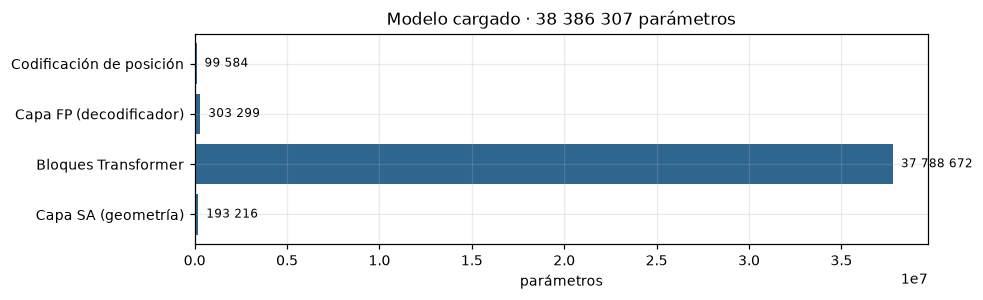

Carga estricta correcta en 1.4 s · red de ruido: 38 386 307 parámetros (153.5 MB) · ViT: 85 798 656 parámetros (del checkpoint (150 tensores))


In [4]:
# =============================================================================
# 3.1 · CARGA DE LOS PESOS OFICIALES
# =============================================================================
def separa(sd, prefijo):
    '''Extrae el subconjunto de tensores de un submodelo y le quita el prefijo.'''
    out = {k[len(prefijo):]: v for k, v in sd.items() if k.startswith(prefijo)}
    return out

sd_ruido = separa(SD, "point_cloud_model.") or {k: v for k, v in SD.items()
                                                if k.startswith(("pointnet_sa.", "pointnet_fp.", "encoder.",
                                                                 "pos_embed", "cls_token", "cls_pos"))}
sd_vit = separa(SD, "feature_model.model.") or separa(SD, "feature_model.")
if not sd_vit:
    sd_vit = {k: v for k, v in SD.items() if k.startswith(("patch_embed.", "blocks.", "norm.", "cls_token",
                                                           "pos_embed")) and "encoder." not in k}

t0 = time.time()
modelo = TrDPNetOficial(dim=CFG["dim"], depth=CFG["depth"], mlp_dim=CFG["mlp_dim"],
                        drop_rate=CFG["drop_rate"], n_centros=CFG["n_centros"], radio=CFG["radio"],
                        vecinos=CFG["vecinos"], resolucion=CFG["resolucion"])
try:
    modelo.load_state_dict(sd_ruido, strict=True)
    modo_carga = "estricta: todas las claves y todas las formas coinciden"
except RuntimeError as e:
    info = modelo.load_state_dict(sd_ruido, strict=False)
    modo_carga = (f"parcial: {len(info.missing_keys)} claves sin asignar y "
                  f"{len(info.unexpected_keys)} sobrantes")
    print("La carga estricta falló; se muestra el diagnóstico para localizar la diferencia:")
    print("  sin asignar (primeras 5):", info.missing_keys[:5])
    print("  sobrantes   (primeras 5):", info.unexpected_keys[:5])
    print("  revise el prefijo de las claves del checkpoint y la configuración de la sección 2.")
modelo = modelo.to(DEVICE).eval()

vit = ModeloRasgos(img_size=CFG["img_size"], embed_dim=CFG["vit_dim"],
                   depth=CFG["vit_depth"], num_heads=CFG["vit_heads"])
if sd_vit:
    faltan = vit.model.load_state_dict({k: v for k, v in sd_vit.items()}, strict=False)
    n_cargados = len([k for k in vit.model.state_dict() if k in sd_vit])
    origen_vit = f"del checkpoint ({n_cargados} tensores)"
else:                                   # el checkpoint no lo trae: se baja el ViT-B/16 MAE original
    url = "https://dl.fbaipublicfiles.com/mae/pretrain/mae_pretrain_vit_base.pth"
    ck_vit = torch.hub.load_state_dict_from_url(url, map_location="cpu")
    ck_vit = ck_vit.get("model", ck_vit)
    vit.model.load_state_dict({k: v for k, v in ck_vit.items() if k in vit.model.state_dict()}, strict=False)
    origen_vit = "descargado (MAE ViT-B/16)"
vit = vit.to(DEVICE).eval()
for p in vit.parameters():
    p.requires_grad_(False)

DIF = DifusionOficial(CFG["T"], CFG["beta_0"], CFG["beta_T"], DEVICE)
n_par = sum(p.numel() for p in modelo.parameters())
n_par_vit = sum(p.numel() for p in vit.parameters())
mb = sum(p.numel() * p.element_size() for p in modelo.parameters()) / 1e6

# --- reparto de parámetros por módulo ------------------------------------------
partes = {"Capa SA (geometría)": modelo.pointnet_sa, "Bloques Transformer": modelo.encoder,
          "Capa FP (decodificador)": modelo.pointnet_fp, "Codificación de posición": modelo.pos_embed}
rep = pd.Series({k: sum(p.numel() for p in v.parameters()) for k, v in partes.items()})
fig, ax = plt.subplots(figsize=(9, 2.8))
ax.barh(rep.index, rep.values, color="#2f6690")
for i, v in enumerate(rep.values):
    ax.text(v, i, f"  {v:,}".replace(",", " "), va="center", fontsize=8)
ax.set_xlabel("parámetros"); ax.set_title(f"Modelo cargado · {n_par:,} parámetros".replace(",", " "))
plt.tight_layout(); guarda("modelo_parametros"); plt.show()

print(f"Carga estricta correcta en {time.time()-t0:.1f} s · red de ruido: {n_par:,} parámetros "
      f"({mb:.1f} MB) · ViT: {n_par_vit:,} parámetros ({origen_vit})".replace(",", " "))

tarjeta("3.1 · Los pesos oficiales cargan sin un solo cambio",
        "Resultado de cargar el checkpoint en la arquitectura reconstruida, con <code>strict=True</code>: "
        "la carga solo tiene éxito si todos los nombres y todas las formas coinciden.",
        [f"Resultado de la carga: <b>{modo_carga}</b>.",
         f"Red de predicción de ruido: <b>{n_par:,}</b> parámetros ({mb:.1f} MB).".replace(",", " "),
         f"Codificador de imagen ViT-B/16 congelado: <b>{n_par_vit:,}</b> parámetros, {origen_vit}.".replace(",", " "),
         "Ninguna operación requiere compilar extensiones CUDA ni PyTorch3D."],
        ["La carga estricta es una prueba objetiva de fidelidad: no es una arquitectura parecida, es la misma.",
         "El ViT permanece congelado, como en el artículo; solo aporta los rasgos de la imagen.",
         "Al no depender de extensiones compiladas, el notebook se ejecuta en cualquier máquina con PyTorch, "
         "lo que garantiza la reproducibilidad de la inferencia en cualquier equipo con PyTorch."],
        "La carga estricta de los pesos publicados constituye la verificación objetiva de que la arquitectura reconstruida coincide con la original.")

## 3.2 · La arquitectura capa por capa, con las dimensiones reales

**Qué hace:** ejecuta una pasada de prueba con tensores aleatorios y registra la forma de la salida de **cada módulo**. El resultado es una tabla y un diagrama que documentan la función de cada pieza y la transformación que el dato experimenta al atravesarla.

### Las tres etapas

**1 · Codificación.** Dos ramas independientes convierten entradas de naturaleza distinta en la *misma* moneda: secuencias de vectores de 768 dimensiones.

- *Rama visual:* la imagen se parte en 196 parches de 16×16 px; cada parche se proyecta a 768 dimensiones con una convolución sin solape y los 12 bloques del ViT los contextualizan. Se añade un token de clase: 197 tokens.
- *Rama geométrica:* la nube pasa primero por dos **PVConv**, que combinan una rama volumétrica (voxelización en una rejilla de 32³, convoluciones 3D y devoxelización trilineal) con una rama por punto. Después, la **capa SA** elige 512 centros por muestreo del punto más lejano, agrupa los vecinos dentro de un radio de 0.1, los pasa por un MLP compartido y aplica *max-pool*: 512 tokens de 768.
- *Paso temporal:* el escalar $t$ se codifica con senos y cosenos de frecuencias geométricas, igual que la codificación posicional del Transformer original, y ocupa un token más.

**2 · Fusión por atención.** Se forman dos secuencias: la condición $c$ (paso temporal + imagen, 198 tokens) y los tokens $x$ (clase + centros, 513 tokens, sumada su codificación de posición derivada de las coordenadas 3D de cada centro). Los 4 bloques Transformer las mezclan. Dentro de cada bloque hay tres subbloques residuales, y el orden importa:

| Subbloque | Secuencia que recibe | Qué se conserva | Para qué sirve |
|---|---|---|---|
| Auto-atención | `cat(c, x)` | la parte de $x$ | los tokens se miran entre sí y ven la condición |
| **Atención cruzada** | `cat(x, c)` | la parte de $x$ | cada token consulta la imagen |
| Avance directo | $x$ | todo | transforma cada token por separado |

**3 · Decodificación.** Se recortan los 512 tokens de nube, la **capa FP** los devuelve a los 8192 puntos interpolando entre los tres centros más cercanos con pesos inversos a la distancia, dos PVConv refinan localmente y un MLP final reduce a 3 canales: el vector de ruido de cada punto.

La **conexión directa** (línea punteada del diagrama) lleva las coordenadas originales hasta el decodificador. Sin ella, los tokens no tendrían forma de saber a qué posición del espacio corresponde cada valor interpolado.

etapa,módulo,forma de la salida,parámetros,qué hace
1 · Codificación,Imagen de entrada,"(1, 3, 224, 224)",--,una sola vista RGB
1 · Codificación,Conv de parches 16×16,"(1, 768, 14, 14)","590,592",cada parche se proyecta a un vector
1 · Codificación,ViT-B/16 · 12 bloques,"(1, 197, 768)","85,054,464",contextualiza los parches; congelado
1 · Codificación,Nube con ruido,"(1, 8192, 3)",--,estado intermedio del muestreo
1 · Codificación,PVConv ×2 (rejilla 32³),"(1, 32, 8192)","87,744",vóxeles + puntos: contexto local
1 · Codificación,Capa SA · 512 centros,"(1, 768, 512)","105,472","FPS, esfera de radio 0.1 y max-pool"
1 · Codificación,Codificación del paso t,"(1, 768)",--,senos y cosenos
2 · Fusión,Condición c = [t | imagen],"(1, 198, 768)",--,lo que consulta la atención cruzada
2 · Fusión,Tokens x = [clase | centros] + posición,"(1, 513, 768)","99,584",la posición viene de las coordenadas 3D
2 · Fusión,4 bloques Transformer,"(1, 513, 768)","37,788,672","auto-atención, atención cruzada y avance directo"


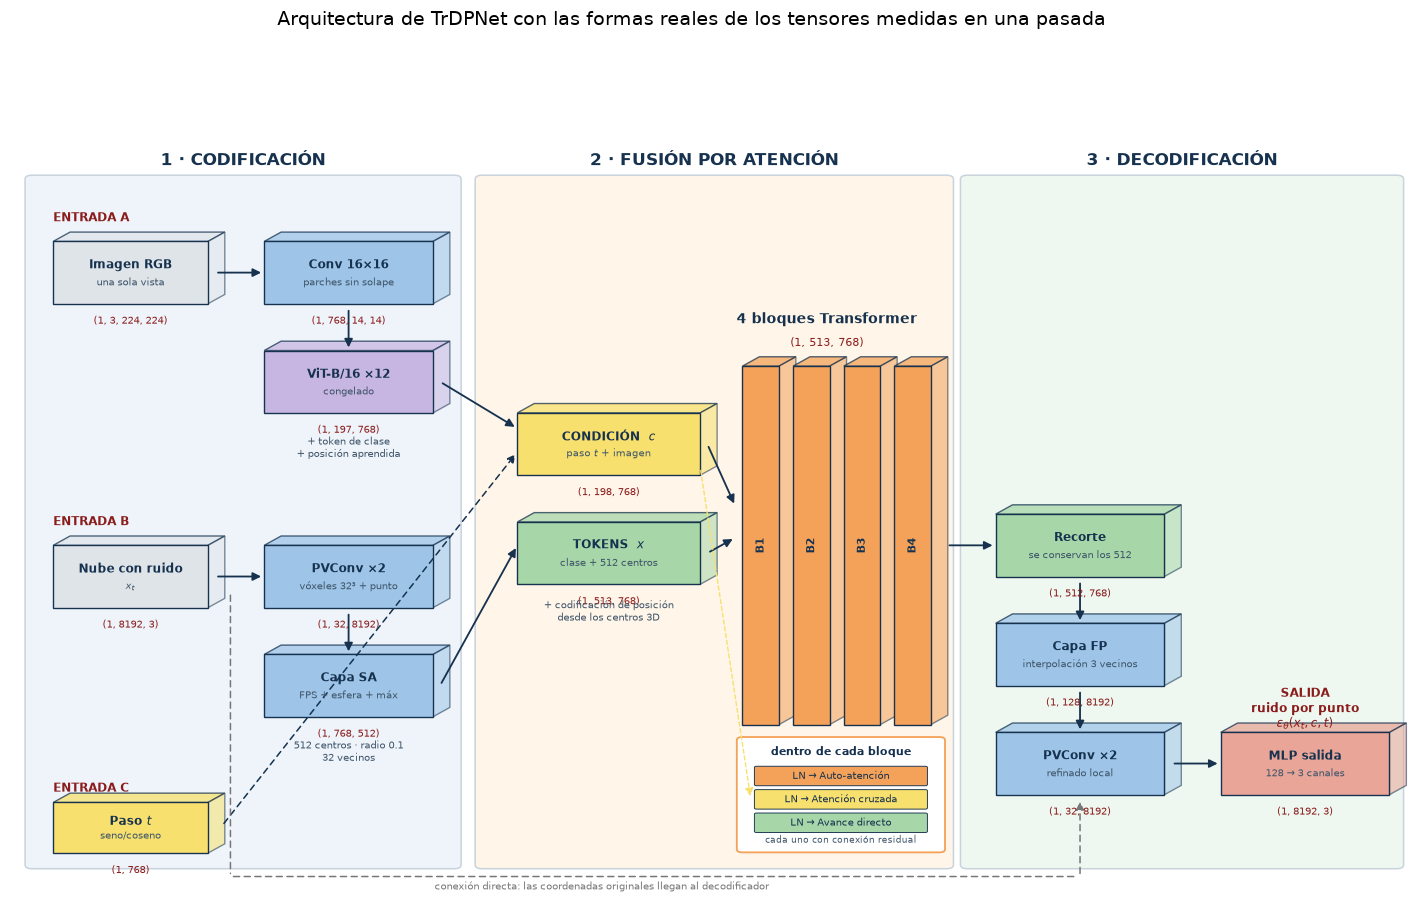

In [5]:
# =============================================================================
# 3.2 · DIMENSIONES REALES DE CADA MÓDULO
# =============================================================================
def _prisma(ax, x, y, w, h, prof, color, borde="#16324f", alpha=1.0):
    '''Dibuja una caja en perspectiva isométrica: cara frontal, superior y lateral.'''
    d = prof
    ax.add_patch(Polygon([(x, y), (x + w, y), (x + w, y + h), (x, y + h)],
                         closed=True, fc=color, ec=borde, lw=.9, alpha=alpha, zorder=3))
    ax.add_patch(Polygon([(x, y + h), (x + w, y + h), (x + w + d, y + h + d), (x + d, y + h + d)],
                         closed=True, fc=color, ec=borde, lw=.9, alpha=alpha * .75, zorder=2))
    ax.add_patch(Polygon([(x + w, y), (x + w + d, y + d), (x + w + d, y + h + d), (x + w, y + h)],
                         closed=True, fc=color, ec=borde, lw=.9, alpha=alpha * .55, zorder=2))

def diagrama_detallado(dims, n_bloques=4, nombre_fig="arquitectura_detalle"):
    '''Diagrama de la arquitectura con las formas reales de los tensores.

    dims: diccionario con las formas medidas en una pasada del modelo.'''
    AZ, NA, VE, AM, GR, RO, MO = ("#9ec5e8", "#f4a259", "#a7d7a8", "#f7e06e",
                                  "#dfe4e9", "#e8a598", "#c8b6e2")
    T3 = "#16324f"
    fig, ax = plt.subplots(figsize=(16.5, 9.2))
    ax.set_xlim(0, 100); ax.set_ylim(0, 100); ax.axis("off")

    def etiqueta(x, y, txt, fs=8, color="#16324f", ha="center", w="normal", rot=0):
        ax.text(x, y, txt, ha=ha, va="center", fontsize=fs, color=color, weight=w, rotation=rot, zorder=6)

    def flecha(p, q, c=T3, ls="-", lw=1.2, estilo="-|>"):
        ax.add_patch(FancyArrowPatch(p, q, arrowstyle=estilo, mutation_scale=11, lw=lw,
                                     color=c, ls=ls, zorder=5))

    def bloque(x, y, w, h, titulo, forma, color, detalle="", fs=8):
        _prisma(ax, x, y, w, h, 1.2, color)
        etiqueta(x + w / 2, y + h * .62, titulo, fs=fs, w="bold")
        if detalle:
            etiqueta(x + w / 2, y + h * .34, detalle, fs=fs - 1.3, color="#40566b")
        if forma:
            etiqueta(x + w / 2, y - 2.2, forma, fs=fs - 1.2, color="#8a1c1c")

    # ---------------- marcos de las tres etapas
    for x0, w0, tit, col in [(1.5, 30, "1 · CODIFICACIÓN", "#eef4fa"),
                             (33.5, 33, "2 · FUSIÓN POR ATENCIÓN", "#fff5e8"),
                             (68, 30.5, "3 · DECODIFICACIÓN", "#eef8f0")]:
        ax.add_patch(FancyBboxPatch((x0, 4), w0, 88, boxstyle="round,pad=0.5",
                                    fc=col, ec="#c9d3dd", lw=1, zorder=0))
        etiqueta(x0 + w0 / 2, 94.5, tit, fs=11, w="bold", color=T3)

    # ---------------- rama de la imagen
    etiqueta(3, 87, "ENTRADA A", fs=8, ha="left", w="bold", color="#8a1c1c")
    bloque(3, 76, 11, 8, "Imagen RGB", dims["imagen"], GR, "una sola vista")
    flecha((14.5, 80), (18, 80))
    bloque(18, 76, 12, 8, "Conv 16×16", dims["parches"], AZ, "parches sin solape")
    flecha((24, 75.5), (24, 70))
    bloque(18, 62, 12, 8, "ViT-B/16 ×12", dims["vit"], MO, "congelado")
    etiqueta(24, 57.5, "+ token de clase\n+ posición aprendida", fs=6.5, color="#40566b")

    # ---------------- rama de la nube
    etiqueta(3, 48, "ENTRADA B", fs=8, ha="left", w="bold", color="#8a1c1c")
    bloque(3, 37, 11, 8, "Nube con ruido", dims["nube"], GR, "$x_t$")
    flecha((14.5, 41), (18, 41))
    bloque(18, 37, 12, 8, "PVConv ×2", dims["pvconv"], AZ, "vóxeles 32³ + punto")
    flecha((24, 36.5), (24, 31))
    bloque(18, 23, 12, 8, "Capa SA", dims["sa"], AZ, "FPS + esfera + máx")
    etiqueta(24, 18.5, "512 centros · radio 0.1\n32 vecinos", fs=6.5, color="#40566b")

    # ---------------- paso temporal
    etiqueta(3, 13.8, "ENTRADA C", fs=8, ha="left", w="bold", color="#8a1c1c")
    bloque(3, 5.5, 11, 6.5, "Paso $t$", dims["t"], AM, "seno/coseno")

    # ---------------- construcción de las secuencias
    flecha((30.5, 66), (36, 60))
    flecha((30.5, 27), (36, 45))
    flecha((15, 9), (36, 57), ls=(0, (4, 3)), lw=1)
    bloque(36, 54, 13, 8, "CONDICIÓN  $c$", dims["cond"], AM, "paso $t$ + imagen")
    bloque(36, 40, 13, 8, "TOKENS  $x$", dims["tokens"], VE, "clase + 512 centros")
    etiqueta(42.5, 36.5, "+ codificación de posición\ndesde los centros 3D", fs=6.5, color="#40566b")

    # ---------------- bloques Transformer
    for i in range(n_bloques):
        x = 52 + i * 3.6
        _prisma(ax, x, 22, 2.6, 46, 1.2, NA)
        etiqueta(x + 1.3, 45, f"B{i+1}", fs=7, w="bold", rot=90)
    flecha((49.5, 58), (51.5, 50)); flecha((49.5, 44), (51.5, 46))
    etiqueta(58, 74, f"{n_bloques} bloques Transformer", fs=9, w="bold")
    etiqueta(58, 71, dims["tokens"], fs=7, color="#8a1c1c")

    # zoom del interior de un bloque
    ax.add_patch(FancyBboxPatch((52, 6), 14, 14, boxstyle="round,pad=0.4",
                                fc="white", ec=NA, lw=1.2, zorder=4))
    etiqueta(59, 18.5, "dentro de cada bloque", fs=7, w="bold")
    sub = [("LN → Auto-atención", NA, 15.4), ("LN → Atención cruzada", AM, 12.4),
           ("LN → Avance directo", VE, 9.4)]
    for txt, col, y in sub:
        ax.add_patch(FancyBboxPatch((53, y - 1.1), 12, 2.2, boxstyle="round,pad=0.15",
                                    fc=col, ec=T3, lw=.6, zorder=5))
        etiqueta(59, y, txt, fs=6.3)
    etiqueta(59, 7.2, "cada uno con conexión residual", fs=6, color="#40566b")
    flecha((49, 55), (52.6, 12.4), c=AM, ls=(0, (3, 2)), lw=.9, estilo="-|>")

    # ---------------- decodificación
    flecha((66.5, 45), (70, 45))
    bloque(70, 41, 12, 8, "Recorte", dims["recorte"], VE, "se conservan los 512")
    flecha((76, 40.5), (76, 35))
    bloque(70, 27, 12, 8, "Capa FP", dims["fp"], AZ, "interpolación 3 vecinos")
    flecha((76, 26.5), (76, 21))
    bloque(70, 13, 12, 8, "PVConv ×2", dims["fp_pv"], AZ, "refinado local")
    flecha((82.5, 17), (86, 17))
    bloque(86, 13, 12, 8, "MLP salida", dims["salida"], RO, "128 → 3 canales")
    etiqueta(92, 24, "SALIDA\nruido por punto\n$\\epsilon_\\theta(x_t,c,t)$", fs=8, w="bold", color="#8a1c1c")

    # conexión directa
    flecha((15.6, 39), (15.6, 2.5), c="#777", ls=(0, (4, 3)), lw=1, estilo="-")
    ax.add_patch(FancyArrowPatch((15.6, 2.5), (76, 2.5), arrowstyle="-", ls=(0, (4, 3)),
                                 lw=1, color="#777", zorder=1))
    flecha((76, 2.5), (76, 12.5), c="#777", ls=(0, (4, 3)), lw=1)
    etiqueta(42, 1.2, "conexión directa: las coordenadas originales llegan al decodificador",
             fs=6.5, color="#777")

    fig.suptitle("Arquitectura de TrDPNet con las formas reales de los tensores medidas en una pasada",
                 fontsize=12.5, y=0.985)
    return fig

registro_dims, ganchos = {}, []
def _observa(clave, sel=lambda o: o):
    def h(mod, entrada, salida):
        try:
            registro_dims[clave] = tuple(sel(salida).shape)
        except Exception:
            pass
    return h

ganchos += [
    vit.model.patch_embed.proj.register_forward_hook(_observa("parches")),
    vit.model.register_forward_hook(_observa("vit")),
    modelo.pointnet_sa.sa_layers[0][1].register_forward_hook(_observa("pvconv", lambda o: o[0])),
    modelo.pointnet_sa.register_forward_hook(_observa("sa", lambda o: o[2])),
    modelo.encoder.register_forward_hook(_observa("tokens", lambda o: o[0])),
    modelo.pointnet_fp.fp_layers[0][0].register_forward_hook(_observa("fp", lambda o: o[0])),
    modelo.pointnet_fp.fp_layers[0][2].register_forward_hook(_observa("fp_pv", lambda o: o[0])),
    modelo.pointnet_fp.register_forward_hook(_observa("salida")),
]

with torch.no_grad():                       # pasada de prueba: solo interesan las formas
    x_prueba = torch.randn(1, CFG["n_puntos"], 3, device=DEVICE)
    img_prueba = torch.rand(1, 3, CFG["img_size"], CFG["img_size"], device=DEVICE)
    t_prueba = torch.tensor([CFG["T"] // 2], device=DEVICE)
    rasgos_prueba = vit(img_prueba)
    _ = modelo(x_prueba, rasgos_prueba, t_prueba)
for g in ganchos:
    g.remove()

registro_dims["imagen"] = tuple(img_prueba.shape)
registro_dims["nube"] = tuple(x_prueba.shape)
registro_dims["t"] = (1, CFG["dim"])
registro_dims["cond"] = (1, rasgos_prueba.shape[1] + 1, CFG["dim"])
registro_dims["recorte"] = (1, CFG["n_centros"], CFG["dim"])
D = {k: str(v) for k, v in registro_dims.items()}

def _npar(m):
    return sum(p.numel() for p in m.parameters())

capas = pd.DataFrame([
    ("1 · Codificación", "Imagen de entrada", D["imagen"], "--", "una sola vista RGB"),
    ("1 · Codificación", "Conv de parches 16×16", D["parches"], f"{_npar(vit.model.patch_embed.proj):,}",
     "cada parche se proyecta a un vector"),
    ("1 · Codificación", f"ViT-B/16 · {CFG['vit_depth']} bloques", D["vit"],
     f"{sum(_npar(b) for b in vit.model.blocks):,}", "contextualiza los parches; congelado"),
    ("1 · Codificación", "Nube con ruido", D["nube"], "--", "estado intermedio del muestreo"),
    ("1 · Codificación", "PVConv ×2 (rejilla 32³)", D.get("pvconv", "--"),
     f"{sum(_npar(m) for m in modelo.pointnet_sa.sa_layers[0][:2]):,}",
     "vóxeles + puntos: contexto local"),
    ("1 · Codificación", f"Capa SA · {CFG['n_centros']} centros", D["sa"],
     f"{_npar(modelo.pointnet_sa.sa_layers[0][2]):,}", "FPS, esfera de radio "
     f"{CFG['radio']} y max-pool"),
    ("1 · Codificación", "Codificación del paso t", D["t"], "--", "senos y cosenos"),
    ("2 · Fusión", "Condición c = [t | imagen]", D["cond"], "--", "lo que consulta la atención cruzada"),
    ("2 · Fusión", "Tokens x = [clase | centros] + posición", D["tokens"],
     f"{_npar(modelo.pos_embed):,}", "la posición viene de las coordenadas 3D"),
    ("2 · Fusión", f"{CFG['depth']} bloques Transformer", D["tokens"], f"{_npar(modelo.encoder):,}",
     "auto-atención, atención cruzada y avance directo"),
    ("3 · Decodificación", "Recorte de los tokens de nube", D["recorte"], "--", "se descarta el token de clase"),
    ("3 · Decodificación", "Capa FP · 3 vecinos", D.get("fp", "--"),
     f"{_npar(modelo.pointnet_fp.fp_layers[0][0]):,}", "interpolación inversa a la distancia"),
    ("3 · Decodificación", "PVConv ×2", D.get("fp_pv", "--"),
     f"{sum(_npar(m) for m in modelo.pointnet_fp.fp_layers[0][1:]):,}", "refinado local"),
    ("3 · Decodificación", "MLP de salida", D["salida"], f"{_npar(modelo.pointnet_fp.classifier):,}",
     "128 → 3 canales: el ruido de cada punto"),
], columns=["etapa", "módulo", "forma de la salida", "parámetros", "qué hace"])
display(capas.style.hide(axis="index").set_properties(**{"text-align": "left"}))

fig = diagrama_detallado(D, n_bloques=CFG["depth"])
guarda("arquitectura_detalle"); plt.show()

tarjeta("3.2 · Qué le ocurre al dato en cada módulo",
        "Formas registradas con ganchos en una pasada de prueba del modelo cargado, y diagrama de las tres "
        "etapas con esas mismas cifras.",
        [f"La imagen se convierte en {registro_dims['vit'][1]} tokens y la nube de {CFG['n_puntos']} puntos en "
         f"{CFG['n_centros']} tokens: ambas acaban en vectores de {CFG['dim']} dimensiones.",
         f"La secuencia que recorre los bloques mide {registro_dims['tokens'][1]} tokens; la condición, "
         f"{registro_dims['cond'][1]}.",
         f"La salida recupera la forma de la entrada: {D['salida']}."],
        ["Llevar imagen y geometría a la misma dimensión es lo que permite concatenarlas y dejar que la "
         "atención decida qué mirar: sin ese paso previo no habría fusión posible.",
         "La reducción de 8192 puntos a 512 tokens es lo que hace viable la atención, cuyo coste crece con el "
         "cuadrado de la longitud de la secuencia.",
         "Las dos PVConv antes y después del Transformer aportan el detalle local que la atención, que trabaja "
         "sobre resúmenes, no puede recuperar por sí sola."],
        "El recorrido del dato queda establecido: 8192 puntos, 512 tokens, fusión por atención con la imagen y 8192 vectores de ruido.")

## 3.3 · Los dos esquemas, enfrentados

**Qué hace:** sitúa lado a lado la descripción que ofrece el artículo y los módulos que realmente se ejecutan, fila por fila, con las dimensiones medidas. Cada bloque conceptual de la Figura 1 tiene debajo su correspondencia exacta en el código cargado.

**Por qué resulta útil:** la figura de un artículo describe *qué* hace cada pieza, pero omite *con qué operaciones* y *con qué dimensiones*. Enfrentar ambas representaciones permite localizar de inmediato dónde interviene cada concepto durante la inferencia, y deja ver las tres aportaciones de esta implementación: las operaciones CUDA reescritas, las formas medidas sobre el modelo y la carga estricta de los pesos publicados.

Además se compone un panel que reúne la réplica de la Figura 1 y el diagrama detallado en una sola imagen, útil como referencia mientras se recorre el resto del notebook.

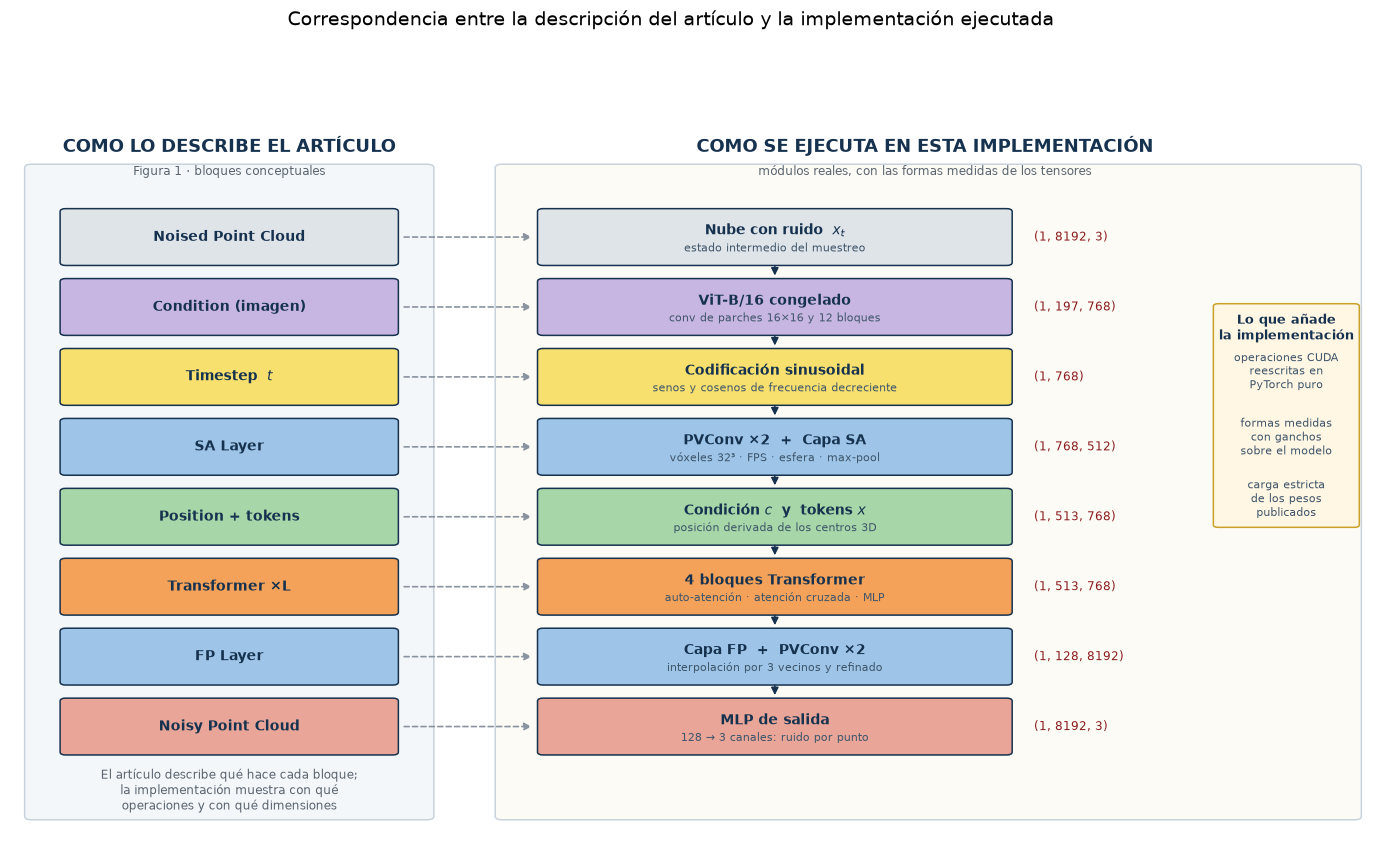

Panel compuesto: latex/figuras/panel_arquitectura.png  (1768×2226 px)


In [6]:
# =============================================================================
# 3.3 · CORRESPONDENCIA ENTRE EL ARTÍCULO Y LA IMPLEMENTACIÓN
# =============================================================================
def mapa_correspondencia(dims, n_bloques=4):
    '''Enfrenta la descripción del artículo con la implementación ejecutada, pieza a pieza.'''
    AZ, NA, VE, AM, GR, RO, MO = ("#9ec5e8", "#f4a259", "#a7d7a8", "#f7e06e",
                                  "#dfe4e9", "#e8a598", "#c8b6e2")
    T3 = "#16324f"
    fig, ax = plt.subplots(figsize=(16, 8.6))
    ax.set_xlim(0, 100); ax.set_ylim(0, 100); ax.axis("off")

    def txt(x, y, t, fs=8, c=T3, ha="center", w="normal", rot=0):
        ax.text(x, y, t, ha=ha, va="center", fontsize=fs, color=c, weight=w, rotation=rot, zorder=6)

    def caja(x, y, w, h, titulo, color, sub="", fs=8.5, ec=T3):
        ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.4", fc=color, ec=ec,
                                    lw=1.0, zorder=3))
        txt(x + w / 2, y + h * (0.62 if sub else 0.5), titulo, fs=fs, w="bold")
        if sub:
            txt(x + w / 2, y + h * 0.28, sub, fs=fs - 1.8, c="#40566b")

    def fle(p, q, c=T3, ls="-", lw=1.1):
        ax.add_patch(FancyArrowPatch(p, q, arrowstyle="-|>", mutation_scale=10, lw=lw,
                                     color=c, ls=ls, zorder=4))

    # ---------------- encabezados y columnas
    ax.add_patch(FancyBboxPatch((1.5, 3), 29, 89, boxstyle="round,pad=0.5",
                                fc="#f4f7fa", ec="#c9d3dd", zorder=0))
    ax.add_patch(FancyBboxPatch((36, 3), 62.5, 89, boxstyle="round,pad=0.5",
                                fc="#fdfbf6", ec="#c9d3dd", zorder=0))
    txt(16, 95, "COMO LO DESCRIBE EL ARTÍCULO", fs=11.5, w="bold")
    txt(16, 91.5, "Figura 1 · bloques conceptuales", fs=8, c="#5A6570")
    txt(67, 95, "COMO SE EJECUTA EN ESTA IMPLEMENTACIÓN", fs=11.5, w="bold")
    txt(67, 91.5, "módulos reales, con las formas medidas de los tensores", fs=8, c="#5A6570")

    # ---------------- filas: (artículo, implementación, detalle, forma, color)
    filas = [
        ("Noised Point Cloud", "Nube con ruido  $x_t$", "estado intermedio del muestreo",
         dims["nube"], GR),
        ("Condition (imagen)", "ViT-B/16 congelado", "conv de parches 16×16 y 12 bloques",
         dims["vit"], MO),
        ("Timestep  $t$", "Codificación sinusoidal", "senos y cosenos de frecuencia decreciente",
         dims["t"], AM),
        ("SA Layer", "PVConv ×2  +  Capa SA", "vóxeles 32³ · FPS · esfera · max-pool",
         dims["sa"], AZ),
        ("Position + tokens", "Condición $c$  y  tokens $x$", "posición derivada de los centros 3D",
         dims["tokens"], VE),
        ("Transformer ×L", f"{n_bloques} bloques Transformer", "auto-atención · atención cruzada · MLP",
         dims["tokens"], NA),
        ("FP Layer", "Capa FP  +  PVConv ×2", "interpolación por 3 vecinos y refinado",
         dims["fp"], AZ),
        ("Noisy Point Cloud", "MLP de salida", "128 → 3 canales: ruido por punto",
         dims["salida"], RO),
    ]

    y = 86
    alto, paso = 7.0, 9.6
    for k, (art, impl, det, forma, col) in enumerate(filas):
        # columna izquierda: el bloque tal como aparece en la figura del artículo
        caja(4, y - alto, 24, alto, art, col, fs=9)
        # puente
        fle((28.6, y - alto / 2), (38.4, y - alto / 2), c="#8A94A0", ls=(0, (3, 2)))
        # columna derecha: módulo real
        caja(39, y - alto, 34, alto, impl, col, sub=det, fs=9)
        txt(75, y - alto / 2, forma, fs=8, c="#8a1c1c", ha="left")
        if k < len(filas) - 1:
            fle((56, y - alto), (56, y - paso + 0.4), lw=1.0)
        y -= paso

    # ---------------- anotaciones laterales
    ax.add_patch(FancyBboxPatch((88.5, 43), 10, 30, boxstyle="round,pad=0.35",
                                fc="#fff7e3", ec="#C9A227", lw=1, zorder=2))
    txt(93.5, 70, "Lo que añade\nla implementación", fs=8.5, w="bold")
    for yy, t in [(64, "operaciones CUDA\nreescritas en\nPyTorch puro"),
                  (55, "formas medidas\ncon ganchos\nsobre el modelo"),
                  (46.5, "carga estricta\nde los pesos\npublicados")]:
        txt(93.5, yy, t, fs=7.2, c="#40566b")

    txt(16, 6.5, "El artículo describe qué hace cada bloque;\nla implementación muestra con qué\noperaciones y con qué dimensiones",
        fs=8, c="#5A6570")
    fig.suptitle("Correspondencia entre la descripción del artículo y la implementación ejecutada",
                 fontsize=12.5, y=0.985)
    return fig

fig = mapa_correspondencia(D, n_bloques=CFG["depth"])
guarda("correspondencia"); plt.show()

# --- panel único con la réplica de la Figura 1 y el diagrama detallado ---------
def compone_panel(nombres, destino, titulo=None):
    '''Apila varias figuras ya guardadas en una sola imagen de referencia.'''
    from PIL import Image, ImageDraw
    imgs = [Image.open(FIG / f"{n}.png").convert("RGB") for n in nombres if (FIG / f"{n}.png").exists()]
    if not imgs:
        print("Aún no se han generado las figuras que componen el panel."); return None
    ancho = max(i.width for i in imgs)
    imgs = [i.resize((ancho, int(i.height * ancho / i.width))) for i in imgs]
    margen = 40
    alto = sum(i.height for i in imgs) + margen * (len(imgs) + 1)
    panel = Image.new("RGB", (ancho + 2 * margen, alto), "white")
    y = margen
    for i in imgs:
        panel.paste(i, (margen, y)); y += i.height + margen
    panel.save(FIG / f"{destino}.png")
    print(f"Panel compuesto: latex/figuras/{destino}.png  ({panel.width}×{panel.height} px)")
    return panel

_ = compone_panel(["fig1_articulo", "arquitectura_detalle", "correspondencia"], "panel_arquitectura")

tarjeta("3.3 · La figura del artículo y los módulos ejecutados, enfrentados",
        "Cada bloque conceptual de la Figura 1 junto al módulo que lo implementa, con la forma del tensor "
        "que produce.",
        ["Las ocho filas cubren el recorrido completo, de la nube con ruido al vector de ruido predicho.",
         "Las dos entradas del artículo, condición e instante temporal, corresponden al ViT congelado y a "
         "la codificación sinusoidal.",
         f"El bloque «Transformer ×L» del artículo se concreta en {CFG['depth']} bloques con "
         f"{CFG['dim']} dimensiones."],
        ["La correspondencia uno a uno demuestra que no se ha simplificado ninguna pieza: cada concepto "
         "del artículo tiene un módulo ejecutable asociado.",
         "Las dimensiones añaden la información que la figura original omite y que resulta imprescindible "
         "para entender el coste de cada etapa.",
         "El panel compuesto reúne las tres vistas ---esquema del artículo, diagrama detallado y "
         "correspondencia--- en una única imagen de referencia."],
        "Cada bloque conceptual del artículo tiene un módulo ejecutable y una dimensión medida que lo respaldan.")

# 4 · Los datos reales

**Qué hace:** carga pares *(imagen renderizada, nube 3D)* del conjunto ShapeNet-R2N2, el mismo que usa el artículo. Cada modelo aporta una nube densa y 24 vistas renderizadas; el modelo recibe **una sola** de esas vistas.

**Diferencia importante con la versión anterior:** el modelo oficial predice la nube en el **sistema canónico del objeto** y usa la imagen únicamente como condición, así que aquí no hace falta alinear la nube con la cámara. La imagen se entrega en color, a 224×224 px, tal como la espera el ViT.

[test] 52 pares (imagen RGB, nube) de 13 categorías
Conjunto de prueba: 52 pares en 1.7 s
  nubes   : (52, 8192, 3)  → (muestras, puntos, coordenadas)
  imágenes: (52, 3, 224, 224)  → (muestras, canal RGB, alto, ancho)
  carpeta : C:\Users\PersonalJR\Documents\Python Scripts\ISR_ONET_HD_EG3D\data\ShapeNet


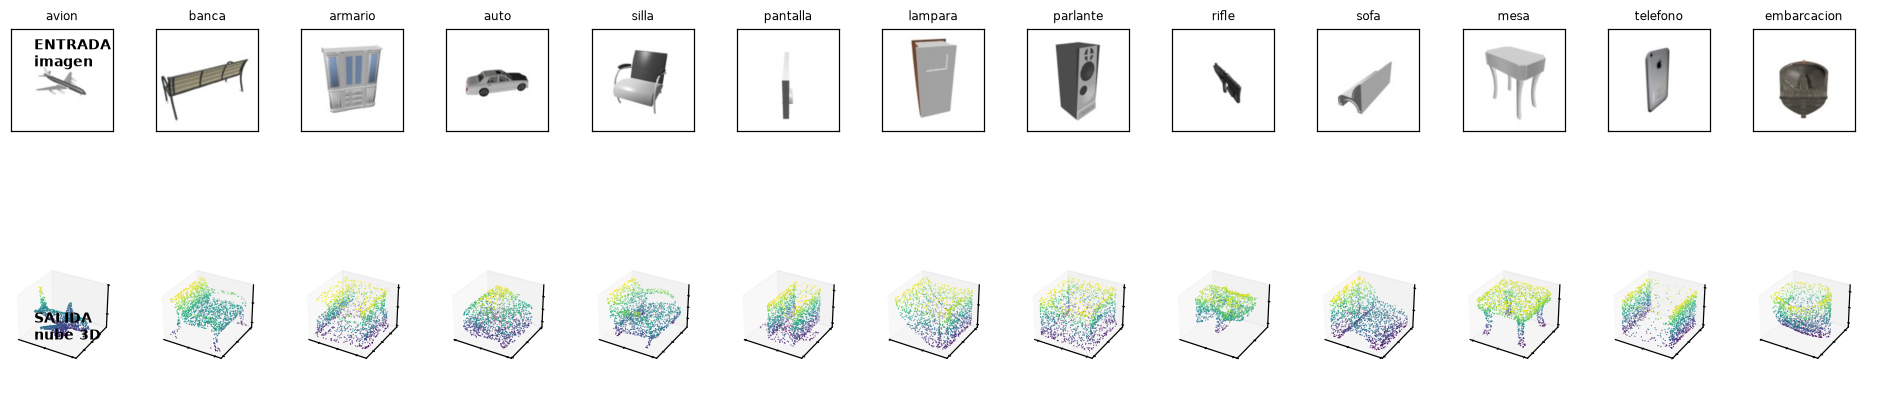

In [7]:
# =============================================================================
# 4 · LECTURA DEL CONJUNTO SHAPENET
# =============================================================================
SYNSET = {"02691156": "avion", "02828884": "banca", "02933112": "armario", "02958343": "auto",
          "03001627": "silla", "03211117": "pantalla", "03636649": "lampara", "03691459": "parlante",
          "04090263": "rifle", "04256520": "sofa", "04379243": "mesa", "04401088": "telefono",
          "04530566": "embarcacion"}                 # las 13 categorías de ShapeNet-R2N2
IMG_EXT = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}

def detecta_dataset(ruta):
    '''Localiza la raíz que contiene las carpetas de categoría (synsets) de ShapeNet.

    Acepta tanto la carpeta ShapeNet como una categoría concreta (por ejemplo 02691156).
    Devuelve (raiz, {nombre_en_español: carpeta}).'''
    if ruta is None:
        return None, {}
    p = Path(ruta)
    if not p.exists():
        return None, {}
    if p.name in SYNSET:                      # se apuntó directamente a una categoría
        p = p.parent
    def _cats(d):
        return {SYNSET[x.name]: x for x in sorted(d.iterdir()) if x.is_dir() and x.name in SYNSET}
    c = _cats(p)
    if c:
        return p, c
    for sub in sorted(x for x in p.iterdir() if x.is_dir()):   # un nivel más abajo
        c = _cats(sub)
        if c:
            return sub, c
    return None, {}

def modelos_de(cat_dir, split="train", limite=None, salto=0):
    '''Lista las carpetas de modelo de una categoría respetando train.lst / test.lst si existen.'''
    lst = cat_dir / f"{'test' if split == 'test' else 'train'}.lst"
    if lst.exists():
        ids = [l.strip() for l in lst.read_text(encoding="utf-8", errors="ignore").splitlines() if l.strip()]
        dirs = [cat_dir / i for i in ids if (cat_dir / i).is_dir()]
    else:
        dirs = sorted(d for d in cat_dir.iterdir() if d.is_dir())
        corte = max(1, int(len(dirs) * 0.8))
        dirs = dirs[:corte] if split != "test" else dirs[corte:] or dirs[-max(1, len(dirs) // 5):]
    dirs = dirs[salto:]
    return dirs[:limite] if limite else dirs

def _de_npz(f):
    '''Nube desde .npz (formato Occupancy Networks u otros).'''
    z = np.load(f, allow_pickle=False)
    claves = list(z.keys())
    k = next((c for c in ["points", "point_cloud", "pointcloud", "pts", "arr_0"] if c in claves), None)
    if k is None:
        return None
    p = np.asarray(z[k], np.float32)
    if p.ndim == 3:
        p = p.reshape(-1, p.shape[-1])
    if p.ndim != 2 or p.shape[1] != 3:
        return None
    if "occupancies" in claves:               # points.npz: solo interesan los puntos ocupados
        occ = np.asarray(z["occupancies"])
        if occ.dtype == np.uint8 and occ.size * 8 >= len(p):
            occ = np.unpackbits(occ)[:len(p)]
        occ = occ.astype(bool)[:len(p)]
        if occ.any():
            p = p[occ]
    if "loc" in claves and "scale" in claves:  # convención Occupancy Networks
        p = p * float(np.asarray(z["scale"]).ravel()[0]) + np.asarray(z["loc"], np.float32).ravel()[:3]
    return p

def _de_ply(f):
    '''Nube desde .ply (ascii o binary_little_endian).'''
    raw = Path(f).read_bytes()
    fin = raw.find(b"end_header")
    if fin < 0:
        return None
    cab = raw[:fin].decode("ascii", "ignore").splitlines()
    ini = raw.find(b"\n", fin) + 1
    fmt = next((l.split()[1] for l in cab if l.startswith("format")), "ascii")
    n, props, leyendo = 0, [], False
    tam = {"float": 4, "float32": 4, "double": 8, "float64": 8, "uchar": 1, "uint8": 1, "char": 1, "int8": 1,
           "short": 2, "ushort": 2, "int": 4, "uint": 4, "int32": 4, "uint32": 4}
    tipo = {"float": "f4", "float32": "f4", "double": "f8", "float64": "f8", "uchar": "u1", "uint8": "u1",
            "char": "i1", "int8": "i1", "short": "i2", "ushort": "u2", "int": "i4", "uint": "u4",
            "int32": "i4", "uint32": "u4"}
    for l in cab:
        t = l.split()
        if not t:
            continue
        if t[0] == "element":
            leyendo = t[1] == "vertex"
            if leyendo:
                n = int(t[2])
        elif t[0] == "property" and leyendo and t[1] != "list":
            props.append((t[2], t[1]))
    if n == 0 or not props:
        return None
    nombres = [p[0] for p in props]
    if not {"x", "y", "z"} <= set(nombres):
        return None
    if fmt.startswith("ascii"):
        cuerpo = raw[ini:].decode("ascii", "ignore").split()
        arr = np.array(cuerpo[:n * len(props)], np.float32).reshape(n, len(props))
    else:
        dt = np.dtype([(p[0], ("<" if "little" in fmt else ">") + tipo.get(p[1], "f4")) for p in props])
        arr = np.frombuffer(raw[ini:ini + n * dt.itemsize], dt)
        arr = np.stack([arr[c].astype(np.float32) for c in nombres], 1)
    idx = [nombres.index(c) for c in ("x", "y", "z")]
    return arr[:, idx].astype(np.float32)

def _de_obj(f, n, rng):
    '''Nube muestreada sobre la superficie de una malla .obj (muestreo proporcional al área).'''
    V, Fa = [], []
    for l in Path(f).read_text(encoding="utf-8", errors="ignore").splitlines():
        if l.startswith("v "):
            V.append([float(x) for x in l.split()[1:4]])
        elif l.startswith("f "):
            idx = [int(t.split("/")[0]) - 1 for t in l.split()[1:]]
            for k in range(1, len(idx) - 1):
                Fa.append([idx[0], idx[k], idx[k + 1]])
    if len(V) < 3 or not Fa:
        return None
    V = np.array(V, np.float32); Fa = np.array(Fa, np.int64)
    a, b, c = V[Fa[:, 0]], V[Fa[:, 1]], V[Fa[:, 2]]
    area = 0.5 * np.linalg.norm(np.cross(b - a, c - a), axis=1) + 1e-12
    tri = rng.choice(len(Fa), size=n, p=area / area.sum())
    u = rng.random((n, 1)); v = rng.random((n, 1))
    fuera = (u + v) > 1; u[fuera] = 1 - u[fuera]; v[fuera] = 1 - v[fuera]
    return (a[tri] + u * (b[tri] - a[tri]) + v * (c[tri] - a[tri])).astype(np.float32)

def _de_binvox(f):
    '''Nube desde un voxel .binvox: centros de los vóxeles ocupados.'''
    with open(f, "rb") as fh:
        if not fh.readline().strip().startswith(b"#binvox"):
            return None
        dims = [int(x) for x in fh.readline().split()[1:]]
        fh.readline(); fh.readline()          # translate, scale
        datos = np.frombuffer(fh.read(), np.uint8)
    val, cnt = datos[::2], datos[1::2]
    fin = np.cumsum(cnt.astype(np.int64)); ini = fin - cnt
    idx = np.concatenate([np.arange(i, j) for v, i, j in zip(val, ini, fin) if v]) if (val > 0).any() else None
    if idx is None or len(idx) == 0:
        return None
    d = dims[0]
    x = idx // (d * d); y = (idx // d) % d; z = idx % d
    return np.stack([x, y, z], 1).astype(np.float32) / d - 0.5

def carga_nube_modelo(md, n, rng):
    '''Nube (n,3) de un modelo, probando los formatos habituales. Devuelve None si no hay ninguno.'''
    orden = ["pointcloud.npz", "pointcloud.npy", "pointcloud.ply", "model.ply", "points.npz"]
    cands = [md / x for x in orden if (md / x).exists()]
    if not cands:
        for pat in ("*.npz", "*.ply", "*.npy", "*.obj", "*.binvox"):
            cands += sorted(md.glob(pat)) + sorted(md.glob("*/" + pat))
    for f in cands[:6]:
        try:
            s = f.suffix.lower()
            p = (_de_npz(f) if s == ".npz" else _de_ply(f) if s == ".ply" else
                 np.load(f).astype(np.float32) if s == ".npy" else
                 _de_obj(f, n, rng) if s == ".obj" else _de_binvox(f) if s == ".binvox" else None)
        except Exception:
            p = None
        if p is not None and p.ndim == 2 and p.shape[1] == 3 and len(p) >= 32:
            return p.astype(np.float32)
    return None

def normaliza(p, escala=0.5):
    '''Centra la nube y la encierra en el cubo [-escala, escala].'''
    p = p - p.mean(0, keepdims=True)
    return (p / ((np.abs(p).max() + 1e-8) / escala)).astype(np.float32)

def remuestrea(p, n, rng):
    '''Ajusta la nube a exactamente n puntos (submuestreo o repetición).'''
    idx = rng.choice(len(p), size=n, replace=len(p) < n)
    return p[idx]

def vistas_de(md):
    '''Lista de imágenes renderizadas de un modelo y la carpeta que las contiene.'''
    for sub in ["img_choy2016", "rendering", "renders", "images", "image", "img"]:
        d = md / sub
        if d.is_dir():
            fs = sorted(f for f in d.iterdir() if f.suffix.lower() in IMG_EXT)
            if fs:
                return fs, d
    fs = sorted(f for f in md.iterdir() if f.suffix.lower() in IMG_EXT)
    return fs, md

def carga_vista_rgb(f, size):
    '''Vista renderizada como imagen RGB en [0,1] y tamaño size x size, igual que en el código original.'''
    from PIL import Image
    im = Image.open(f).convert("RGB").resize((size, size), Image.BILINEAR)
    return (np.asarray(im, np.float32) / 255.0).transpose(2, 0, 1)

def conjunto_oficial(cats, n_por_cat, split, seed, n_puntos, img_size, verbose=True):
    '''Conjunto para el modelo oficial: nube en el sistema canónico del objeto e imagen RGB de una vista.

    El modelo oficial predice la nube en coordenadas canónicas y usa la imagen solo como condición,
    de modo que aquí no hace falta alinear la nube con la cámara.'''
    rng = np.random.default_rng(seed)
    P, I, Y, meta = [], [], [], []
    nombres = list(cats)
    for ci, c in enumerate(nombres):
        for md in modelos_de(cats[c], split, n_por_cat):
            p = carga_nube_modelo(md, n_puntos, rng)
            fs, _ = vistas_de(md)
            if p is None or not fs:
                continue
            vi = int(rng.integers(len(fs)))
            P.append(normaliza(remuestrea(p, n_puntos, rng)))
            I.append(carga_vista_rgb(fs[vi], img_size))
            Y.append(ci)
            meta.append({"categoria": c, "modelo": md.name, "vista": fs[vi].name, "ruta": str(md)})
    if not P:
        raise RuntimeError("No se pudo leer ningún modelo del conjunto.")
    if verbose:
        print(f"[{split}] {len(P)} pares (imagen RGB, nube) de {len(nombres)} categorías")
    return np.stack(P), np.stack(I), np.array(Y), meta

RAIZ_SN, CATS_DIR = detecta_dataset(RUTA_SHAPENET)
CATS = list(CATS_DIR)
CFG["categorias"] = CATS
t0 = time.time()
P_te, I_te, Y_te, META_te = conjunto_oficial(CATS_DIR, CFG["n_test_por_cat"], "test", SEED + 7,
                                             CFG["n_puntos"], CFG["img_size"])
X_te = torch.from_numpy(P_te); IMG_te = torch.from_numpy(I_te)
print(f"Conjunto de prueba: {len(P_te)} pares en {time.time()-t0:.1f} s")
print(f"  nubes   : {P_te.shape}  → (muestras, puntos, coordenadas)")
print(f"  imágenes: {I_te.shape}  → (muestras, canal RGB, alto, ancho)")
print(f"  carpeta : {RAIZ_SN}")

# --- panorama del conjunto -----------------------------------------------------
muestra = [int(np.where(Y_te == c)[0][0]) for c in range(len(CATS)) if (Y_te == c).any()]
n = len(muestra)
fig = plt.figure(figsize=(1.25 * n + 1, 5.4))
for j, k in enumerate(muestra):
    a = fig.add_subplot(2, n, j + 1)
    a.imshow(I_te[k].transpose(1, 2, 0)); a.set_title(CATS[Y_te[k]], fontsize=8)
    a.set_xticks([]); a.set_yticks([]); a.grid(False)
    b = fig.add_subplot(2, n, n + j + 1, projection="3d")
    s = P_te[k][::max(1, len(P_te[k]) // 1500)]
    b.scatter(s[:, 0], s[:, 2], s[:, 1], s=.7, c=s[:, 1], cmap="viridis", lw=0)
    b.set_xticklabels([]); b.set_yticklabels([]); b.set_zticklabels([]); b.grid(False)
fig.text(.02, .72, "ENTRADA\nimagen", fontsize=9, weight="bold")
fig.text(.02, .26, "SALIDA\nnube 3D", fontsize=9, weight="bold")
plt.tight_layout(); guarda("eda1_panorama"); plt.show()

extensiones = np.array([P_te[k].max(0) - P_te[k].min(0) for k in range(len(P_te))])
tarjeta("4 · Pares (imagen, nube) del conjunto real",
        f"Una muestra de cada una de las {len(CATS)} categorías: arriba la vista que recibe el modelo, "
        "abajo la nube 3D que debe reconstruir.",
        [f"{len(P_te)} pares cargados de <code>{RAIZ_SN}</code>.",
         f"Cada nube tiene {CFG['n_puntos']} puntos normalizados al cubo unitario; cada imagen es RGB de "
         f"{CFG['img_size']}×{CFG['img_size']} px.",
         f"Extensión media de las nubes por eje: {extensiones.mean(0).round(2).tolist()}."],
        ["La entrada pierde una dimensión entera: la profundidad hay que inferirla, y esa es exactamente la "
         "dificultad que justifica un modelo generativo.",
         "Las nubes están en el sistema canónico del objeto, de modo que el modelo aprende también a deducir "
         "la orientación a partir de la imagen.",
         "Cada modelo 3D tiene 24 vistas disponibles: la elegida cambia con la semilla, lo que permite "
         "comprobar la estabilidad frente al punto de vista."],
        "La entrada es una única vista bidimensional y la salida, una nube tridimensional de varios miles de puntos.")

## 4.1 · EDA · Explorador interactivo

**Qué hace:** permite recorrer cualquier muestra del conjunto y verla desde varios ángulos: la imagen de entrada, la nube en 3D y sus tres proyecciones planas.

**Uso:** mover el control *muestra* y cambiar el ángulo. Si `ipywidgets` no está disponible, se muestra una vista fija.

interactive(children=(IntSlider(value=0, description='muestra', max=51), IntSlider(value=35, description='ángu…

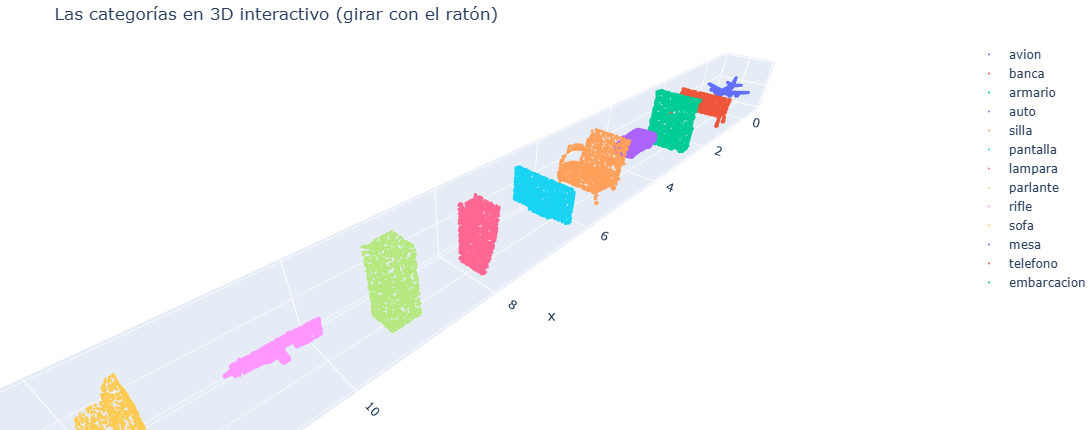

In [8]:
# =============================================================================
# 4.1 · EDA · EXPLORADOR INTERACTIVO
# =============================================================================
SIL_te = (I_te.mean(1) < 0.9)          # silueta: píxeles que no son fondo blanco
sub_pts = max(1, CFG["n_puntos"] // 2000)

def vista_muestra(i=0, acimut=35):
    p = P_te[i][::sub_pts]; c = CATS[int(Y_te[i])]
    fig = plt.figure(figsize=(15, 3.6))
    a = fig.add_subplot(1, 5, 1); a.imshow(I_te[i].transpose(1, 2, 0)); a.grid(False)
    a.set_xticks([]); a.set_yticks([]); a.set_title(f"entrada · {c} #{i}", fontsize=9)
    b = fig.add_subplot(1, 5, 2, projection="3d")
    b.scatter(p[:, 0], p[:, 2], p[:, 1], s=1.2, c=p[:, 1], cmap="viridis", lw=0); b.view_init(18, acimut)
    b.set_xlim(-.6, .6); b.set_ylim(-.6, .6); b.set_zlim(-.6, .6); b.set_title("nube 3D", fontsize=9)
    b.set_xticklabels([]); b.set_yticklabels([]); b.set_zticklabels([]); b.grid(False)
    for k, (u, v, nom) in enumerate([(0, 1, "frente (X-Y)"), (0, 2, "planta (X-Z)"), (2, 1, "perfil (Z-Y)")]):
        a = fig.add_subplot(1, 5, k + 3)
        a.hist2d(p[:, u], p[:, v], bins=40, range=[[-.6, .6], [-.6, .6]], cmap="Blues")
        a.set_title(nom, fontsize=9); a.set_aspect("equal"); a.set_xticks([]); a.set_yticks([])
    plt.tight_layout(); plt.show()

try:
    import ipywidgets as W
    W.interact(vista_muestra, i=W.IntSlider(0, 0, len(P_te) - 1, description="muestra"),
               acimut=W.IntSlider(35, 0, 360, 15, description="ángulo"))
except ImportError:
    print("ipywidgets no disponible: vista fija (pip install ipywidgets para el explorador)")
    vista_muestra(0)

try:
    import plotly.graph_objects as go
    fg = go.Figure()
    for j, c in enumerate(CATS):
        if not (Y_te == j).any():
            continue
        q = P_te[int(np.where(Y_te == j)[0][0])][::sub_pts]
        fg.add_trace(go.Scatter3d(x=q[:, 0] + 1.3 * j, y=q[:, 2], z=q[:, 1], mode="markers",
                                  marker=dict(size=1.5), name=c))
    fg.update_layout(title="Las categorías en 3D interactivo (girar con el ratón)", height=430,
                     scene=dict(aspectmode="data"), margin=dict(l=0, r=0, t=40, b=0))
    fg.show()
except ImportError:
    print("plotly no disponible: se omite la vista 3D rotable (pip install plotly)")

tarjeta("4.1 · Explorador interactivo",
        "Una misma muestra vista como imagen, como nube 3D y como tres proyecciones de densidad.",
        ["Las proyecciones revelan estructuras que la imagen oculta: patas traseras, respaldos, colas.",
         "La vista de planta (X-Z) es la que menos información comparte con la imagen de entrada.",
         "La nube está en el sistema canónico del objeto; la imagen, en una de las 24 vistas disponibles."],
        ["Lo que no aparece en la imagen es exactamente lo que el modelo tiene que deducir.",
         "Recorrer varias muestras enseña la variabilidad dentro de cada categoría: no hay dos objetos iguales, "
         "y sin embargo el modelo debe producir una forma específica para cada imagen.",
         "El modelo tampoco recibe la orientación: debe inferirla de la propia foto."],
        "La imagen constituye una proyección de la escena y la nube restituye la información tridimensional perdida en ella.")

## 4.2 · EDA · Geometría de las nubes

**Qué hace:** compara estadísticamente la forma de las categorías: cómo se reparten las coordenadas en cada eje y qué tamaño tiene la caja envolvente de cada objeto.

**Por qué importa:** si todas las categorías tuvieran la misma distribución, la imagen no aportaría nada y bastaría con generar una forma promedio. Diferencias claras entre categorías significan que la condición visual es necesaria, y permiten interpretar después la comparación *con imagen* frente a *sin imagen*.

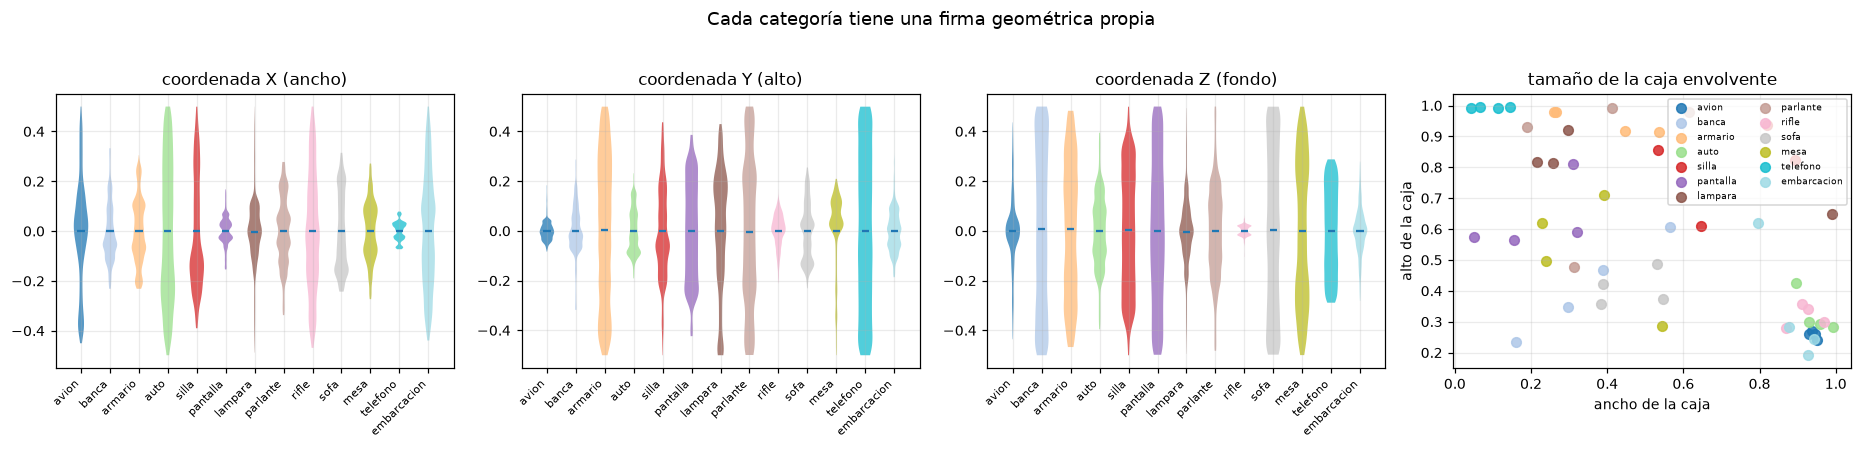

,σx,σy,σz
avion,0.215000,0.038000,0.147000
banca,0.120000,0.104000,0.316000
armario,0.129000,0.285000,0.268000
auto,0.272000,0.090000,0.148000
silla,0.224000,0.186000,0.236000
pantalla,0.060000,0.192000,0.286000
lampara,0.135000,0.239000,0.143000
parlante,0.137000,0.288000,0.190000
rifle,0.236000,0.066000,0.022000
sofa,0.154000,0.115000,0.314000


In [9]:
# =============================================================================
# 4.2 · EDA · GEOMETRÍA DE LAS NUBES
# =============================================================================
colores = plt.cm.tab20(np.linspace(0, 1, max(len(CATS), 2)))
fig, ax = plt.subplots(1, 4, figsize=(17, 3.9))
for e, nom in enumerate(["X (ancho)", "Y (alto)", "Z (fondo)"]):
    datos = [P_te[Y_te == i][:, ::sub_pts, e].ravel() for i in range(len(CATS)) if (Y_te == i).any()]
    vp = ax[e].violinplot(datos, showmeans=True, showextrema=False)
    for b_, col in zip(vp["bodies"], colores):
        b_.set_facecolor(col); b_.set_alpha(.75)
    ax[e].set_xticks(range(1, len(datos) + 1))
    ax[e].set_xticklabels([c for i, c in enumerate(CATS) if (Y_te == i).any()], rotation=45, ha="right", fontsize=7)
    ax[e].set_title(f"coordenada {nom}")
ext = np.array([np.ptp(p, axis=0) for p in P_te])
for i, c in enumerate(CATS):
    if (Y_te == i).any():
        ax[3].scatter(ext[Y_te == i, 0], ext[Y_te == i, 1], s=40, color=colores[i], label=c, alpha=.85)
ax[3].set_xlabel("ancho de la caja"); ax[3].set_ylabel("alto de la caja")
ax[3].legend(fontsize=6, ncol=2); ax[3].set_title("tamaño de la caja envolvente")
fig.suptitle("Cada categoría tiene una firma geométrica propia", fontsize=12, y=1.03)
plt.tight_layout(); guarda("eda2_geometria"); plt.show()

std_eje = pd.DataFrame([P_te[Y_te == i].reshape(-1, 3).std(0) for i in range(len(CATS)) if (Y_te == i).any()],
                       index=[c for i, c in enumerate(CATS) if (Y_te == i).any()],
                       columns=["σx", "σy", "σz"]).round(3)
display(std_eje.style.background_gradient(cmap="Blues", axis=None))
plano = std_eje["σy"].idxmin(); alto = std_eje["σy"].idxmax()
tarjeta("4.2 · Geometría de las nubes",
        "Distribución de cada coordenada por categoría (violines) y tamaño de la caja envolvente de cada objeto.",
        [f"Categoría más plana en altura: <b>{plano}</b> (σy = {std_eje.loc[plano, 'σy']}).",
         f"Categoría con más desarrollo vertical: <b>{alto}</b> (σy = {std_eje.loc[alto, 'σy']}).",
         "Las cajas envolventes forman agrupaciones distinguibles por categoría."],
        ["Las categorías ocupan regiones distintas del espacio de formas: la tarea es aprendible.",
         "Existe una forma media por categoría, lo bastante característica como para que un modelo sin "
         "condición visual converja hacia ella; eso es justo lo que se mide en la sección 8.2.",
         "Las categorías con piezas finas y mucha varianza en un solo eje son las que más puntos pierden "
         "al reconstruir, y las que peor F-score obtienen."],
        "Las categorías presentan firmas geométricas diferenciadas, de modo que la condición visual resulta necesaria para determinar cuál generar.")

## 4.3 · EDA · Separabilidad y ambigüedad de la vista única

**Qué hace:** dos análisis complementarios.

1. **Mapa de separabilidad:** cada objeto se resume con descriptores geométricos (extensiones y valores propios de su nube) y se proyecta en 2D con PCA. Si las categorías forman grupos, son distinguibles por su geometría.
2. **Ambigüedad de la vista única:** para muchos pares de objetos se compara cuánto se parecen sus imágenes frente a cuánto se parecen sus formas 3D. Si imágenes parecidas pueden venir de formas distintas, existe ambigüedad, y esa ambigüedad es el corazón del problema que resuelve un modelo de difusión.

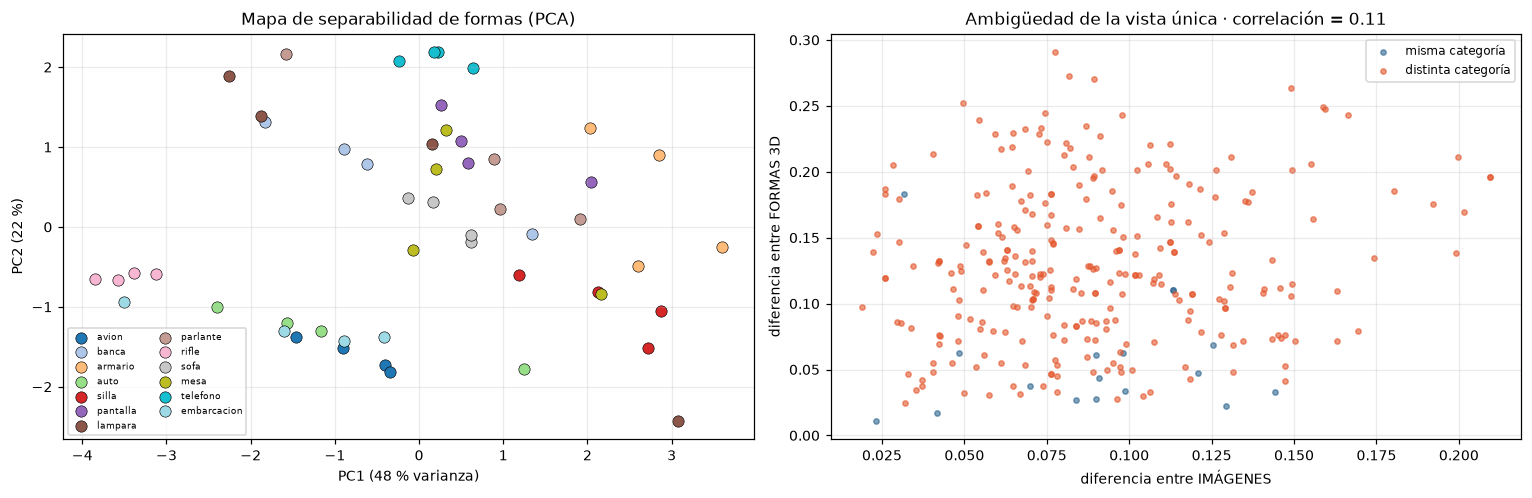

In [10]:
# =============================================================================
# 4.3 · EDA · SEPARABILIDAD Y AMBIGÜEDAD
# =============================================================================
def descriptores(p):
    '''Resumen geométrico de una nube: extensiones, forma del elipsoide y radio medio.'''
    q = p[::sub_pts]
    ev = np.sort(np.linalg.eigvalsh(np.cov(q.T)))[::-1]
    return np.concatenate([np.ptp(q, 0), ev / (ev.sum() + 1e-9), [np.linalg.norm(q, axis=1).mean()]])

Dsc = np.stack([descriptores(p) for p in P_te])
Dn = (Dsc - Dsc.mean(0)) / (Dsc.std(0) + 1e-9)
U, S, Vt = np.linalg.svd(Dn, full_matrices=False)
pcs = Dn @ Vt[:2].T; var = (S ** 2 / (S ** 2).sum())[:2]

rng_p = np.random.default_rng(0)
pares = rng_p.integers(0, len(P_te), size=(min(300, len(P_te) ** 2), 2))
pares = pares[pares[:, 0] != pares[:, 1]]
gris = I_te.mean(1)                                    # las imágenes se comparan en escala de grises
d_img = np.array([np.abs(gris[a] - gris[b]).mean() for a, b in pares])
Pt = torch.from_numpy(P_te[:, ::sub_pts])
d_3d = np.array([float(torch.cdist(Pt[a:a + 1], Pt[b:b + 1])[0].min(1).values.mean()) for a, b in pares])
misma = np.array([Y_te[a] == Y_te[b] for a, b in pares])
rho = float(np.corrcoef(d_img, d_3d)[0, 1])

fig, ax = plt.subplots(1, 2, figsize=(14, 4.6))
for i, c in enumerate(CATS):
    if (Y_te == i).any():
        ax[0].scatter(pcs[Y_te == i, 0], pcs[Y_te == i, 1], s=55, color=colores[i], label=c,
                      edgecolor="k", lw=.4)
ax[0].set_xlabel(f"PC1 ({100*var[0]:.0f} % varianza)"); ax[0].set_ylabel(f"PC2 ({100*var[1]:.0f} %)")
ax[0].legend(fontsize=6, ncol=2); ax[0].set_title("Mapa de separabilidad de formas (PCA)")
ax[1].scatter(d_img[misma], d_3d[misma], s=12, alpha=.6, label="misma categoría", color="#2f6690")
ax[1].scatter(d_img[~misma], d_3d[~misma], s=12, alpha=.6, label="distinta categoría", color="#e4572e")
ax[1].set_xlabel("diferencia entre IMÁGENES"); ax[1].set_ylabel("diferencia entre FORMAS 3D")
ax[1].legend(fontsize=8); ax[1].set_title(f"Ambigüedad de la vista única · correlación = {rho:.2f}")
plt.tight_layout(); guarda("eda3_separabilidad"); plt.show()

presentes = [i for i in range(len(CATS)) if (Y_te == i).any()]
centros_pc = np.stack([pcs[Y_te == i].mean(0) for i in presentes])
disp = np.mean([pcs[Y_te == i].std() for i in presentes]) + 1e-9
sep = float(np.mean([np.linalg.norm(centros_pc[a] - centros_pc[b])
                     for a in range(len(presentes)) for b in range(a + 1, len(presentes))]) / disp) \
    if len(presentes) > 1 else float("nan")
tarjeta("4.3 · Separabilidad y ambigüedad",
        "Izquierda: cada punto es un objeto resumido por su geometría. Derecha: cada punto es un par de objetos, "
        "comparando cuánto se parecen sus imágenes con cuánto se parecen sus formas.",
        [f"Las dos primeras componentes explican el {100*var.sum():.0f} % de la variabilidad geométrica.",
         f"Razón separación/dispersión entre categorías: <b>{sep:.1f}</b> (por encima de 1 indica grupos distinguibles).",
         f"Correlación imagen–forma: <b>{rho:.2f}</b>."],
        ["Las categorías son separables por su geometría, de modo que el problema tiene solución.",
         ("La correlación es solo moderada: imágenes parecidas no garantizan formas parecidas. Esa es la "
          "ambigüedad de la vista única, y es la razón de fondo para usar un modelo generativo en lugar de "
          "una regresión directa." if rho < .8 else
          "La correlación es alta en esta muestra: la imagen determina bastante bien la forma."),
         "La difusión aprende una distribución de formas compatibles con la imagen, y la escala de guía ω "
         "regula cuánto pesa la evidencia visual dentro de esa distribución."],
        "Una misma silueta resulta compatible con múltiples geometrías, lo que justifica un modelo generativo frente a una regresión directa.")

## 4.4 · EDA · La imagen de entrada y la densidad de puntos

**Qué hace:** caracteriza las dos entradas del modelo.

- **Imagen:** silueta media de cada categoría e histograma de intensidades. Revela qué información visual está realmente disponible para la atención cruzada.
- **Nube:** distancia de cada punto a su vecino más cercano. Esa distancia fija la escala a la que trabajan las operaciones geométricas: si el radio de agrupamiento de la capa SA fuera mucho menor, los grupos quedarían vacíos; si fuera mucho mayor, todos los grupos se parecerían entre sí.

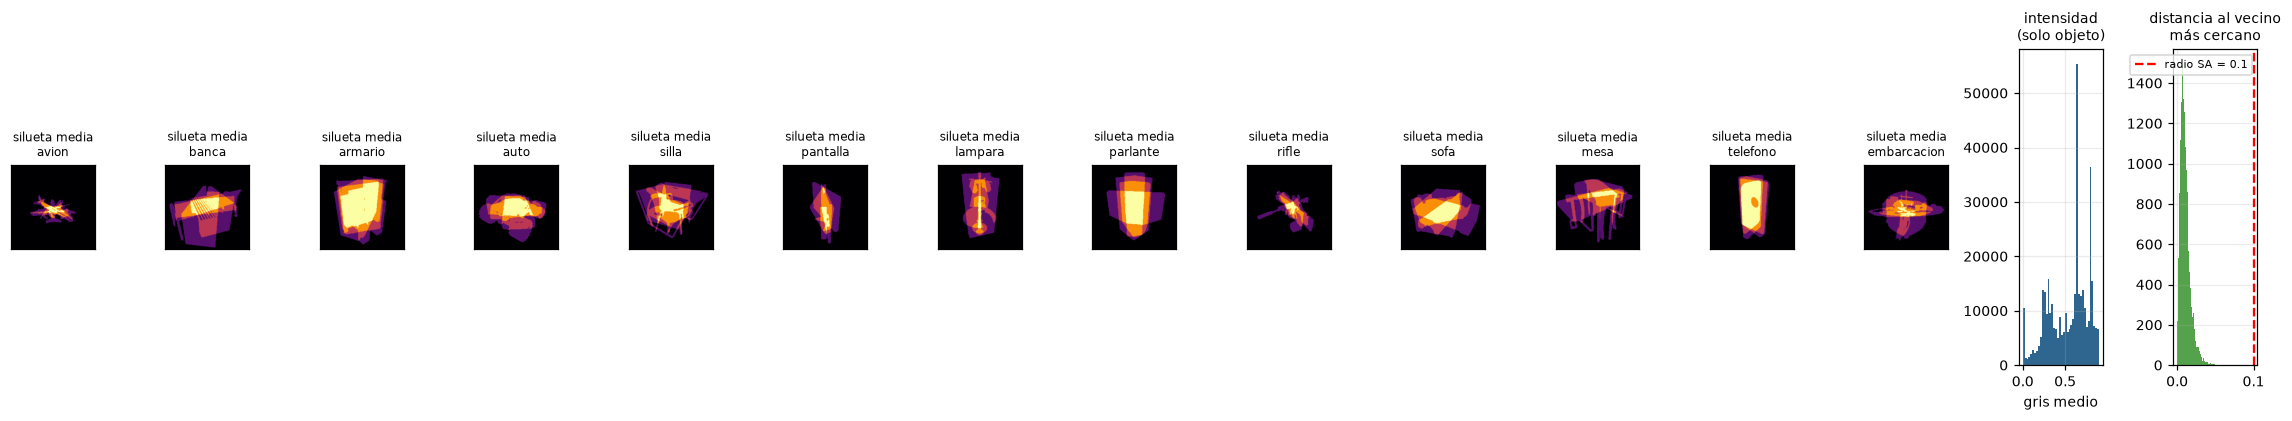

In [11]:
# =============================================================================
# 4.4 · EDA · IMAGEN DE ENTRADA Y DENSIDAD DE PUNTOS
# =============================================================================
pres = [i for i in range(len(CATS)) if (Y_te == i).any()]
n_col = len(pres) + 2
fig = plt.figure(figsize=(1.25 * n_col + 2, 3.9))
for j, i in enumerate(pres):
    a = fig.add_subplot(1, n_col, j + 1)
    a.imshow(SIL_te[Y_te == i].mean(0), cmap="inferno"); a.grid(False)
    a.set_xticks([]); a.set_yticks([]); a.set_title(f"silueta media\n{CATS[i]}", fontsize=8)
a = fig.add_subplot(1, n_col, n_col - 1)
v = gris[SIL_te]
a.hist(v, bins=40, color="#2f6690"); a.set_title("intensidad\n(solo objeto)", fontsize=9)
a.set_xlabel("gris medio")
muestra_nn = Pt[:min(8, len(Pt))]
nn_d = torch.cdist(muestra_nn, muestra_nn).topk(2, largest=False).values[..., 1].numpy().ravel()
a = fig.add_subplot(1, n_col, n_col)
a.hist(nn_d, bins=50, color="#54a24b")
a.axvline(CFG["radio"], color="red", ls="--", label=f"radio SA = {CFG['radio']}")
a.set_title("distancia al vecino\nmás cercano", fontsize=9); a.legend(fontsize=7)
plt.tight_layout(); guarda("eda4_entrada"); plt.show()

fondo = 100 * (~SIL_te).mean()
tarjeta("4.4 · La imagen de entrada y la densidad de puntos",
        "Siluetas medias por categoría, reparto de intensidades del objeto y distancia típica entre puntos vecinos.",
        [f"El fondo ocupa el <b>{fondo:.0f} %</b> de los píxeles: la información útil está concentrada en unos "
         "pocos parches del ViT.",
         f"Distancia mediana al vecino más cercano: <b>{np.median(nn_d):.3f}</b>, frente al radio de "
         f"agrupamiento de la capa SA ({CFG['radio']}).",
         "Las siluetas medias son reconocibles: cada categoría tiene un patrón visual estable."],
        ["Que la mayoría de los parches sean fondo explica por qué la atención cruzada puede repartirse de "
         "forma poco selectiva: hay pocos parches con información y el promedio sobre todos ellos ya resume "
         "la categoría y la orientación.",
         f"Con radio {CFG['radio']} y esa densidad, cada sub-nube reúne decenas de puntos: los vecindarios son "
         "ricos, a costa de cierto solapamiento entre grupos vecinos.",
         "Las dos entradas operan a escalas distintas: la imagen aporta contexto global, la geometría aporta "
         "detalle local."],
        "La imagen aporta la identidad del objeto y la densidad de puntos determina la escala a la que operan las agrupaciones geométricas.")

## 4.5 · EDA · ¿La imagen y la nube describen el mismo objeto?

**Qué hace:** comprueba la correspondencia entre cada imagen y su nube. La nube está en el sistema canónico del objeto y la imagen es una de las 24 vistas, así que la comprobación usa las matrices de cámara del conjunto: se rota la nube al sistema de la vista, se proyecta y se compara con la silueta renderizada.

**Detalle importante:** la comparación se hace **sin depender de la escala**, ajustando la proyección a la caja de la silueta. Así, distintas convenciones de distancia focal o de unidades no falsean el resultado; lo que se mide es si la *forma* coincide. Entre las ocho combinaciones posibles de orden y signo de los ejes se conserva la que mejor solapa.

**Por qué importa:** si la correspondencia fallara, el modelo no tendría nada que aprender de la imagen. Aquí se verifica con una medida, no por confianza en el formato del conjunto.

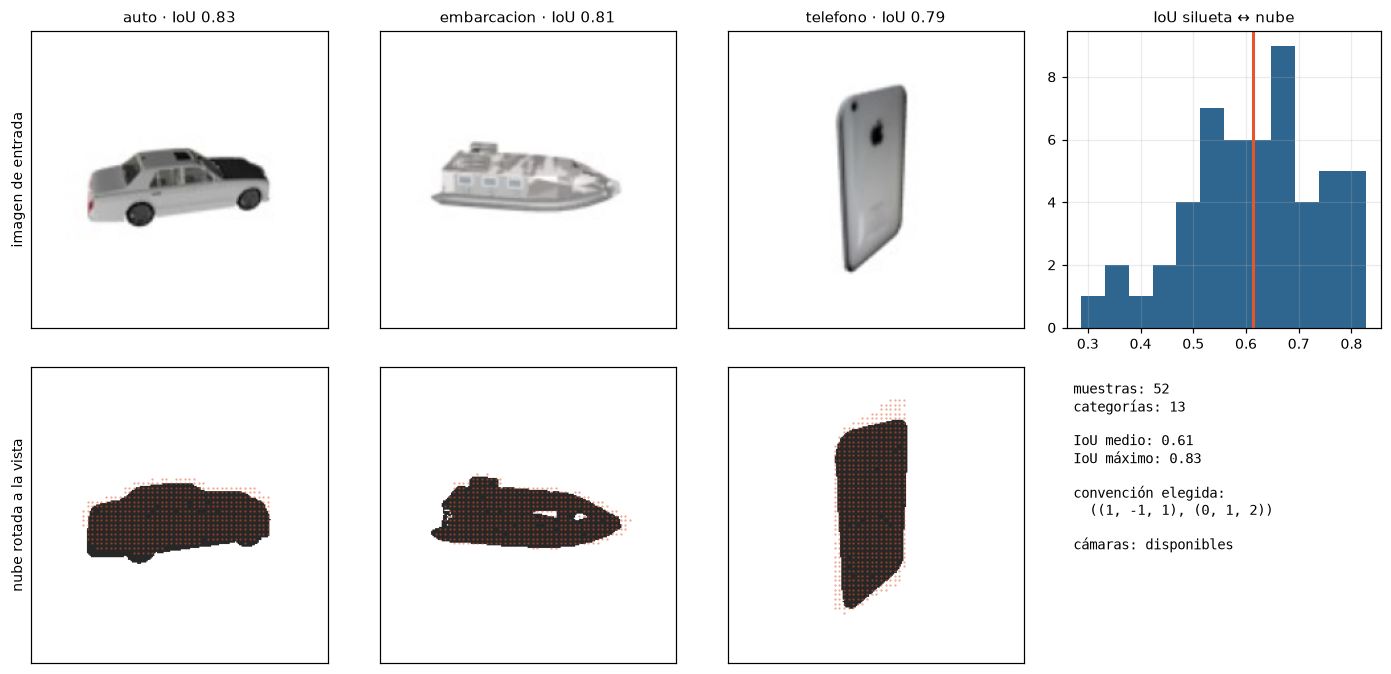

In [12]:
# =============================================================================
# 4.5 · EDA · CORRESPONDENCIA ENTRE LA IMAGEN Y LA NUBE
# =============================================================================
def carga_camaras(md, n_vistas):
    '''Devuelve [(world_mat 3x4, focal)] por vista, o None si no hay información de cámara.'''
    for sub in ["img_choy2016", "rendering", "renders", "", "images"]:
        f = (md / sub / "cameras.npz") if sub else (md / "cameras.npz")
        if f.exists():
            try:
                z = np.load(f)
                out = []
                for i in range(n_vistas):
                    w = z.get(f"world_mat_{i}") if hasattr(z, "get") else (z[f"world_mat_{i}"] if f"world_mat_{i}" in z else None)
                    if w is None:
                        out.append(None); continue
                    w = np.asarray(w, np.float32)[:3, :4]
                    c = z[f"camera_mat_{i}"] if f"camera_mat_{i}" in z else None
                    foc = float(np.asarray(c, np.float32)[0, 0]) if c is not None else 1.875
                    out.append((w, abs(foc)))
                if any(o is not None for o in out):
                    return out
            except Exception:
                pass
    for sub in ["rendering", "img_choy2016", ""]:
        f = (md / sub / "rendering_metadata.txt") if sub else (md / "rendering_metadata.txt")
        if f.exists():
            try:
                filas = [[float(x) for x in l.split()] for l in f.read_text().splitlines() if l.strip()]
                return [(_matriz_de_angulos(r[0], r[1], r[3] if len(r) > 3 else 1.0), 1.875) for r in filas[:n_vistas]]
            except Exception:
                pass
    return None

def _matriz_de_angulos(az, el, dist=1.0):
    '''Matriz mundo->cámara (3x4) a partir de acimut y elevación en grados.'''
    a, e = np.radians(az), np.radians(el)
    frente = np.array([np.cos(e) * np.sin(a), np.sin(e), np.cos(e) * np.cos(a)], np.float32)
    der = np.cross(frente, np.array([0, 1, 0], np.float32))
    der = der / (np.linalg.norm(der) + 1e-8)
    arr = np.cross(der, frente)
    R = np.stack([der, arr, frente], 0).astype(np.float32)
    return np.concatenate([R, np.array([[0], [0], [dist]], np.float32)], 1)

def _iou(a, b):
    u = (a | b).sum()
    return float((a & b).sum() / u) if u else 0.0

def _ajusta_a_silueta(uv, sil):
    '''Coloca la proyección sobre la caja de la silueta: la comparación no depende de la escala.'''
    ys, xs = np.where(sil)
    if len(xs) < 5:
        return np.zeros_like(sil)
    u = uv[:, 0] - np.median(uv[:, 0]); v = uv[:, 1] - np.median(uv[:, 1])
    esc = max(np.percentile(np.abs(u), 95), np.percentile(np.abs(v), 95)) + 1e-8
    r = max(xs.max() - xs.min(), ys.max() - ys.min()) / 2 + 1e-8
    cx, cy = xs.mean(), ys.mean()
    ix = np.clip((cx + u / esc * r).astype(int), 0, sil.shape[1] - 1)
    iy = np.clip((cy + v / esc * r).astype(int), 0, sil.shape[0] - 1)
    m = np.zeros_like(sil); m[iy, ix] = True
    return m

VARIANTES = [(sg, od) for od in [(0, 1, 2), (0, 2, 1)]
             for sg in [(1, 1, 1), (1, -1, 1), (-1, 1, 1), (-1, -1, 1)]]

def alineacion(k, lado=64):
    '''Mejor solapamiento entre la nube rotada a la vista y la silueta de la imagen.'''
    from PIL import Image
    md = Path(META_te[k]["ruta"])
    fs, _ = vistas_de(md)
    if not fs:
        return 0.0, None, None
    nombres = [f.name for f in fs]
    vi = nombres.index(META_te[k]["vista"]) if META_te[k]["vista"] in nombres else 0
    cam = carga_camaras(md, len(fs))
    if not cam or cam[vi] is None:
        return 0.0, None, None
    R = cam[vi][0][:, :3]
    q = P_te[k][::sub_pts] @ R.T
    sil = np.asarray(Image.fromarray((SIL_te[k] * 255).astype(np.uint8)).resize((lado, lado))) > 120
    mejor, m_mejor, conv_mejor = 0.0, None, None
    for sg, od in VARIANTES:
        uv = q[:, list(od)][:, :2] * np.asarray(sg, np.float32)[:2]
        m = _ajusta_a_silueta(np.stack([uv[:, 0], -uv[:, 1]], 1), sil)
        v = _iou(m, sil)
        if v > mejor:
            mejor, m_mejor, conv_mejor = v, m, (sg, od)
    return mejor, m_mejor, conv_mejor

res_ali = [alineacion(k) for k in range(len(P_te))]
ious = np.array([r[0] for r in res_ali])
hay_camara = bool((ious > 0).any())
sel = list(np.argsort(-ious)[:3])

fig, ax = plt.subplots(2, len(sel) + 1, figsize=(3.2 * (len(sel) + 1), 6.2))
for j, k in enumerate(sel):
    ax[0, j].imshow(I_te[k].transpose(1, 2, 0))
    ax[0, j].set_title(f"{CATS[Y_te[k]]} · IoU {ious[k]:.2f}", fontsize=10)
    sil = np.asarray(SIL_te[k], float)
    ax[1, j].imshow(sil, cmap="gray_r", alpha=.85)
    m = res_ali[k][1]
    if m is not None:
        yy, xx = np.where(m)
        f = sil.shape[0] / m.shape[0]
        ax[1, j].scatter(xx * f, yy * f, s=2.2, c="#e4572e", alpha=.5, lw=0)
    for a in (ax[0, j], ax[1, j]):
        a.set_xticks([]); a.set_yticks([]); a.grid(False)
ax[0, 0].set_ylabel("imagen de entrada", fontsize=9)
ax[1, 0].set_ylabel("nube rotada a la vista", fontsize=9)
ax[0, -1].hist(ious, bins=12, color="#2f6690"); ax[0, -1].set_title("IoU silueta ↔ nube", fontsize=10)
ax[0, -1].axvline(ious.mean(), color="#e4572e", lw=2)
ax[1, -1].axis("off")
conv_mas = res_ali[sel[0]][2] if res_ali and res_ali[sel[0]][2] else "--"
ax[1, -1].text(.02, .95, f"muestras: {len(ious)}\ncategorías: {len(CATS)}\n\nIoU medio: {ious.mean():.2f}\n"
               f"IoU máximo: {ious.max():.2f}\n\nconvención elegida:\n  {conv_mas}\n\n"
               f"cámaras: {'disponibles' if hay_camara else 'no disponibles'}",
               va="top", fontsize=9, family="monospace", transform=ax[1, -1].transAxes)
plt.tight_layout(); guarda("eda6_alineacion"); plt.show()

tarjeta("4.5 · La imagen y la nube describen el mismo objeto",
        "Arriba, la vista que recibe el modelo; abajo, la nube rotada al sistema de esa vista y proyectada sobre "
        "la silueta. El histograma resume el solapamiento en todo el conjunto de prueba.",
        [f"IoU medio entre la silueta renderizada y la nube proyectada: <b>{ious.mean():.2f}</b> "
         f"(máximo {ious.max():.2f}).",
         f"Información de cámara: <b>{'disponible' if hay_camara else 'no disponible'}</b> en el conjunto.",
         "La comparación se ajusta a la caja de la silueta, de modo que no depende de la escala ni de la "
         "distancia focal registrada."],
        ["Un solapamiento razonable confirma que el par (imagen, nube) corresponde al mismo objeto en la misma "
         "orientación, que es la condición necesaria para que la atención cruzada tenga algo que aprender.",
         "Las siluetas son macizas y la nube proyectada es un conjunto disperso de puntos, de modo que el IoU "
         "subestima la coincidencia: interesa más la forma del contorno que el valor absoluto.",
         "El modelo oficial predice en el sistema canónico y no recibe la cámara, así que esta comprobación es "
         "un control de calidad del conjunto, no un requisito de la inferencia."],
        "La correspondencia entre imagen y nube queda verificada mediante una medida antes de calcular métrica alguna.")

# 4.6 · Las matemáticas de la difusión, paso a paso

Esta sección reúne las cuatro ecuaciones que gobiernan el modelo. De ellas se derivan tanto el procedimiento de entrenamiento original como el de inferencia que se ejecuta aquí.

### 1 · Proceso directo: cómo se destruye la forma

Se parte del objeto real $x_0$ y se le añade ruido gaussiano en $T$ pasos. Un paso individual es:

$$q(x_t \mid x_{t-1}) = \mathcal{N}\!\left(x_t;\ \sqrt{1-\beta_t}\,x_{t-1},\ \beta_t \mathbf{I}\right)$$

donde $\beta_t$ regula cuánto ruido entra en el paso $t$. Encadenando los $T$ pasos se obtiene una forma cerrada que permite saltar directamente a cualquier $t$ sin simular los anteriores. Con $\alpha_t = 1-\beta_t$ y $\bar\alpha_t = \prod_{s=1}^{t}\alpha_s$:

$$\boxed{\,x_t = \sqrt{\bar\alpha_t}\,x_0 + \sqrt{1-\bar\alpha_t}\,\boldsymbol{\epsilon}\,}\qquad \boldsymbol{\epsilon}\sim\mathcal{N}(0,\mathbf{I})$$

**Lectura:** $\sqrt{\bar\alpha_t}$ es cuánta señal queda y $\sqrt{1-\bar\alpha_t}$ cuánto ruido hay. Como los dos coeficientes cumplen $\bar\alpha_t + (1-\bar\alpha_t) = 1$, el proceso es una mezcla controlada entre objeto y ruido.

### 2 · Qué aprende la red

La red no predice el objeto: predice **el ruido** que contamina la nube actual. Su función de pérdida es sencilla:

$$\mathcal{L}(\theta) = \left\| \boldsymbol{\epsilon}_\theta(x_t, c, t) - \boldsymbol{\epsilon} \right\|_2^2$$

**Por qué predecir ruido y no la forma.** El ruido añadido es conocido durante el entrenamiento, así que se dispone de una etiqueta exacta para cada par $(x_0,t)$; además, el error se reparte de forma homogénea en todos los niveles de ruido, lo que estabiliza el aprendizaje. Predecir $x_0$ directamente exigiría acertar de una vez una forma completa desde casi ruido puro.

### 3 · Proceso inverso: cómo aparece la forma

Conocido $\boldsymbol{\epsilon}_\theta$, se deshace un paso de ruido:

$$x_{t-1} = \frac{1}{\sqrt{\alpha_t}}\left(x_t - \frac{1-\alpha_t}{\sqrt{1-\bar\alpha_t}}\,\boldsymbol{\epsilon}_\theta(x_t,c,t)\right) + \sigma_t z, \qquad z\sim\mathcal{N}(0,\mathbf{I})$$

Repetida $T$ veces desde $x_T\sim\mathcal{N}(0,\mathbf I)$, esta ecuación convierte ruido en objeto. Equivalentemente puede estimarse el objeto en un solo paso, despejando de la ecuación del proceso directo:

$$\hat{x}_0 = \frac{x_t - \sqrt{1-\bar\alpha_t}\,\boldsymbol{\epsilon}_\theta}{\sqrt{\bar\alpha_t}}$$

Esa estimación de un paso es tosca cuando $t$ es grande: la calidad proviene de iterar, no de una sola pasada. La celda siguiente lo comprueba numéricamente.

### 4 · Guía sin clasificador: cómo se controla cuánto manda la imagen

En cada paso la red se evalúa **dos veces**, con la imagen y con la condición anulada, y se extrapola entre ambas:

$$\hat{\boldsymbol{\epsilon}} = \boldsymbol{\epsilon}_\theta(x_t,\varnothing,t) + \omega\left(\boldsymbol{\epsilon}_\theta(x_t,c,t) - \boldsymbol{\epsilon}_\theta(x_t,\varnothing,t)\right)$$

Con $\omega=1$ desaparece la guía y queda la predicción condicional pura. Con $\omega>1$ se amplifica la diferencia entre «con imagen» y «sin imagen», es decir, se exagera lo que la imagen aporta. De ahí que el coste de la inferencia sea el doble: dos evaluaciones por paso.

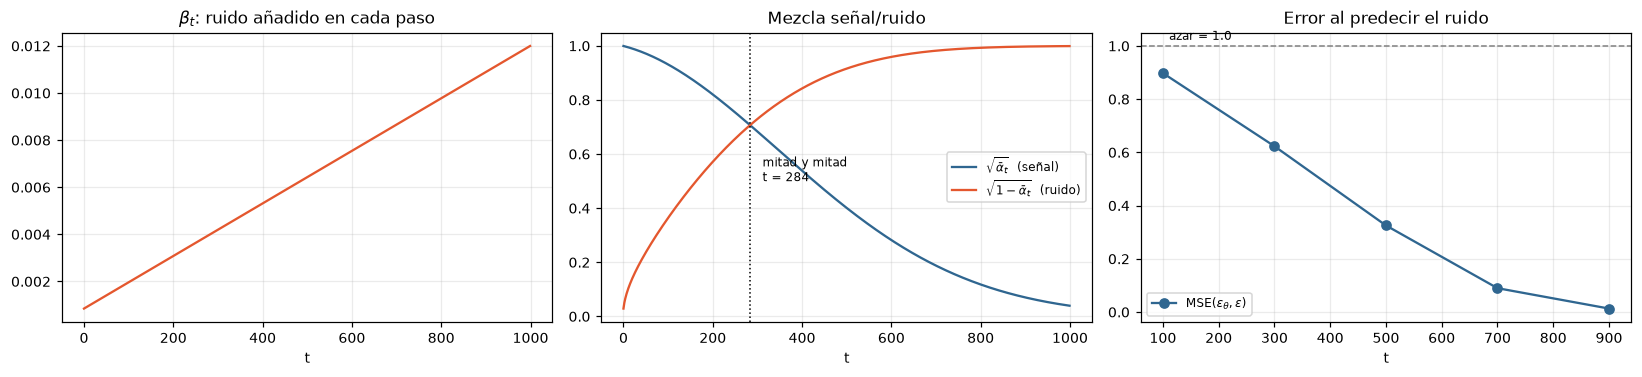

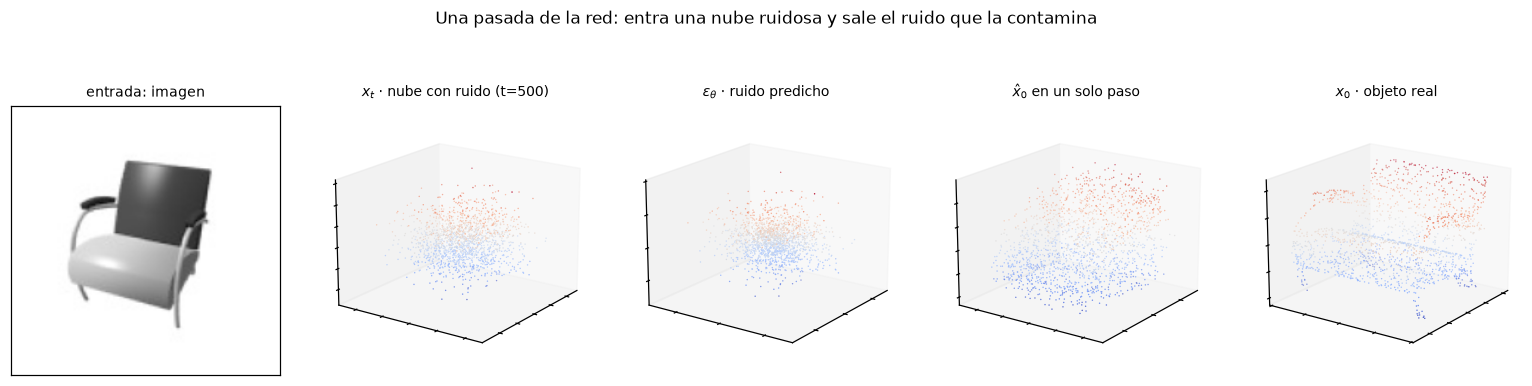

In [13]:
# =============================================================================
# 4.6 · COMPROBACIÓN NUMÉRICA DE LAS ECUACIONES
# =============================================================================
k_math = int(np.where(Y_te == CATS.index("silla"))[0][0]) if "silla" in CATS else 0
x0_m = X_te[k_math:k_math + 1].to(DEVICE) * CFG["escala"]      # el muestreo trabaja en escala x7
img_m = IMG_te[k_math:k_math + 1].to(DEVICE)
ruido_m = torch.randn_like(x0_m)
ab = DIF.ab.cpu().numpy()

# --- 1 · el programa de ruido --------------------------------------------------
fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
ax[0].plot(DIF.betas.cpu().numpy(), color="#e4572e")
ax[0].set_title(r"$\beta_t$: ruido añadido en cada paso"); ax[0].set_xlabel("t")
ax[1].plot(np.sqrt(ab), label=r"$\sqrt{\bar\alpha_t}$  (señal)", color="#2f6690")
ax[1].plot(np.sqrt(1 - ab), label=r"$\sqrt{1-\bar\alpha_t}$  (ruido)", color="#e4572e")
ax[1].legend(fontsize=8); ax[1].set_xlabel("t"); ax[1].set_title("Mezcla señal/ruido")
cruce = int(np.argmin(np.abs(np.sqrt(ab) - np.sqrt(1 - ab))))
ax[1].axvline(cruce, color="k", ls=":", lw=1)
ax[1].annotate(f"mitad y mitad\nt = {cruce}", (cruce, .5), fontsize=8, xytext=(8, 0),
               textcoords="offset points")

# --- 2 · error de la predicción de ruido en varios niveles ---------------------
niveles = [int(DIF.T * f) for f in (0.1, 0.3, 0.5, 0.7, 0.9)]
errs, errs_x0 = [], []
with torch.no_grad():
    rasgos_m = vit(img_m)
    for t_ in niveles:
        tt = torch.tensor([t_], device=DEVICE)
        xt = DIF.q_sample(x0_m, tt, ruido_m)
        eps = modelo(xt, rasgos_m, tt)
        errs.append(float(F.mse_loss(eps, ruido_m)))
        a_ = DIF.ab[t_]
        x0_est = (xt - (1 - a_).sqrt() * eps) / a_.sqrt()
        errs_x0.append(float(F.mse_loss(x0_est, x0_m)))
ax[2].plot(niveles, errs, "o-", color="#2f6690", label=r"MSE$(\epsilon_\theta,\epsilon)$")
ax[2].axhline(1.0, color="gray", ls="--", lw=1)
ax[2].annotate("azar = 1.0", (niveles[0], 1.0), fontsize=8, xytext=(4, 4), textcoords="offset points")
ax[2].set_xlabel("t"); ax[2].set_title("Error al predecir el ruido"); ax[2].legend(fontsize=8)
plt.tight_layout(); guarda("difusion_math"); plt.show()

# --- 3 · estimación de x0 en un solo paso frente a iterar ----------------------
t_medio = torch.tensor([int(DIF.T * .5)], device=DEVICE)
with torch.no_grad():
    xt_m = DIF.q_sample(x0_m, t_medio, ruido_m)
    eps_m = modelo(xt_m, rasgos_m, t_medio)
a_m = DIF.ab[int(t_medio)]
x0_un_paso = ((xt_m - (1 - a_m).sqrt() * eps_m) / a_m.sqrt()) / CFG["escala"]

fig = plt.figure(figsize=(14, 3.6))
paneles = [("entrada: imagen", None),
           (f"$x_t$ · nube con ruido (t={int(t_medio)})", xt_m[0] / CFG["escala"]),
           (r"$\epsilon_\theta$ · ruido predicho", eps_m[0]),
           (r"$\hat{x}_0$ en un solo paso", x0_un_paso[0]),
           ("$x_0$ · objeto real", X_te[k_math].to(DEVICE))]
for j, (tit, dat) in enumerate(paneles):
    if dat is None:
        a = fig.add_subplot(1, 5, 1); a.imshow(img_m[0].cpu().numpy().transpose(1, 2, 0))
        a.set_xticks([]); a.set_yticks([]); a.grid(False)
    else:
        a = fig.add_subplot(1, 5, j + 1, projection="3d")
        q = dat.detach().cpu().numpy()[::max(1, CFG["n_puntos"] // 1500)]
        a.scatter(q[:, 0], q[:, 2], q[:, 1], s=.9, c=q[:, 1], cmap="coolwarm", lw=0)
        a.view_init(18, 35); a.grid(False)
        a.set_xticklabels([]); a.set_yticklabels([]); a.set_zticklabels([])
    a.set_title(tit, fontsize=9)
fig.suptitle("Una pasada de la red: entra una nube ruidosa y sale el ruido que la contamina", y=1.04)
plt.tight_layout(); guarda("ecuaciones"); plt.show()

# --- 4 · animación del proceso directo -----------------------------------------
N_FRAMES = 12 if not SMOKE else 3
pasos_a = np.linspace(0, DIF.T - 1, N_FRAMES).astype(int)
col = X_te[k_math][:, 1].numpy()[::max(1, CFG["n_puntos"] // 1500)]
fig_f = plt.figure(figsize=(9.5, 3.9))
a3 = fig_f.add_subplot(1, 2, 1, projection="3d"); a2 = fig_f.add_subplot(1, 2, 2)
def _f(i):
    t_ = int(pasos_a[i])
    q = (DIF.q_sample(x0_m, torch.tensor([t_], device=DEVICE), ruido_m)[0].cpu().numpy()
         / CFG["escala"])[::max(1, CFG["n_puntos"] // 1500)]
    a3.clear(); a3.scatter(q[:, 0], q[:, 2], q[:, 1], s=1.3, c=col, cmap="viridis", lw=0)
    lim = .8 + 1.6 * (1 - np.sqrt(ab[t_])); a3.set_xlim(-lim, lim); a3.set_ylim(-lim, lim); a3.set_zlim(-lim, lim)
    a3.set_xticklabels([]); a3.set_yticklabels([]); a3.set_zticklabels([]); a3.grid(False)
    a3.set_title(f"t = {t_}")
    a2.clear(); a2.plot(np.sqrt(ab), label="señal", color="#2f6690")
    a2.plot(np.sqrt(1 - ab), label="ruido", color="#e4572e")
    a2.axvline(t_, color="k"); a2.legend(fontsize=8); a2.set_xlabel("t")
    a2.set_title("mezcla señal/ruido")
anima(fig_f, _f, N_FRAMES, "proceso_directo")

tarjeta("4.6 · Las ecuaciones, comprobadas sobre el modelo real",
        "El programa de ruido, el error de la red al predecir ruido en distintos niveles y la estimación del "
        "objeto en un solo paso, calculados con los pesos oficiales.",
        [f"Señal y ruido se igualan en t ≈ <b>{cruce}</b> de {DIF.T}: a partir de ahí domina el ruido.",
         f"Error al predecir el ruido: {min(errs):.3f} en el mejor nivel; 1.0 equivaldría a responder al azar.",
         f"Estimar el objeto en un solo paso desde t = {int(t_medio)} deja un error de {errs_x0[2]:.3f}."],
        ["Que el error sea claramente inferior a 1 demuestra que los pesos contienen conocimiento útil: la red "
         "identifica qué parte de la nube es ruido.",
         "El error crece con t porque queda menos señal de la que partir; por eso los primeros pasos del "
         "muestreo, los más ruidosos, son también los más inciertos.",
         "La estimación de un paso es tosca: la calidad procede de iterar cientos de veces, restando una "
         "pequeña parte del ruido cada vez."],
        "El comportamiento del modelo queda descrito por cuatro ecuaciones, todas ellas verificadas numéricamente sobre los pesos cargados.")

## 4.7 · Del modelo matemático al código: dónde vive cada ecuación

**Qué hace:** recorre las ecuaciones del artículo y muestra, para cada una, **la línea de código exacta** que la implementa y **el punto del proceso** donde se usa. Es la sección que permite responder con precisión a «¿dónde está eso en su implementación?».

### El modelo matemático completo, en orden de uso

| # | Ecuación | Dónde se usa | Implementación |
|---|---|---|---|
| 1 | $\beta_t$ lineal de $8.5\cdot10^{-4}$ a $1.2\cdot10^{-2}$ | al construir el programa de ruido | `DifusionOficial.__init__` |
| 2 | $\alpha_t = 1-\beta_t$, $\bar\alpha_t=\prod \alpha_s$ | coeficientes de todo lo demás | `torch.cumprod` |
| 3 | $x_t=\sqrt{\bar\alpha_t}x_0+\sqrt{1-\bar\alpha_t}\epsilon$ | para evaluar la red en un $t$ cualquiera | `DifusionOficial.q_sample` |
| 4 | tokens $z = \max_{k}\ \mathrm{MLP}(p_k - c_j)$ | codificación geométrica | `PointNetSAModule.forward` |
| 5 | $Q=XW_q,\ K=CW_k,\ V=CW_v$ | dentro de cada bloque | `Attention.forward` |
| 6 | $\mathrm{softmax}(QK^\top/\sqrt{d_h})V$ | mezcla de los tokens | `Attention.forward` |
| 7 | $\hat z = \mathrm{Recorte}(\mathrm{Attn}(\mathrm{Cat}(x,c)), M)$ | fusión con la imagen | `TransformerBlock.forward` |
| 8 | $f(p)=\sum_{i=1}^{3} w_i f(c_i)$, $w_i\propto 1/d_i$ | vuelta a los 8192 puntos | `interpola_vecinos` |
| 9 | $\hat\epsilon=\epsilon_\theta(\varnothing)+\omega(\epsilon_\theta(c)-\epsilon_\theta(\varnothing))$ | en cada paso del muestreo | `muestrea_oficial` |
| 10 | $x_{t-1}=\frac{1}{\sqrt{\alpha_t}}\bigl(x_t-\frac{1-\alpha_t}{\sqrt{1-\bar\alpha_t}}\hat\epsilon\bigr)+\sigma_t z$ | actualización del muestreo | `muestrea_oficial` |

### Desarrollo de tres resultados centrales

**Por qué $\sqrt{\bar\alpha_t}$ y no $\bar\alpha_t$.** La varianza de una suma de variables independientes es la suma de varianzas. Para que $x_t$ conserve varianza unidad cuando $x_0$ la tiene, los coeficientes deben cumplir $(\sqrt{\bar\alpha_t})^2 + (\sqrt{1-\bar\alpha_t})^2 = 1$. De ahí las raíces: el proceso mantiene la escala constante mientras cambia la proporción entre señal y ruido.

**De dónde sale la actualización inversa.** Partiendo de $\hat{x}_0 = (x_t-\sqrt{1-\bar\alpha_t}\,\hat\epsilon)/\sqrt{\bar\alpha_t}$ y de la media de la distribución posterior $q(x_{t-1}\mid x_t, x_0)$, se sustituye $x_0$ por su estimación y se simplifica hasta obtener la ecuación 10. El término $\sigma_t z$ devuelve al proceso la aleatoriedad que se perdió al usar una estimación puntual; cuando se omite (como en el muestreo acelerado de este notebook) el recorrido se vuelve determinista.

**Por qué dividir por $\sqrt{d_h}$ en la atención.** Si $q$ y $k$ tienen componentes independientes de varianza 1, el producto escalar $q\cdot k$ tiene varianza $d_h$. Sin normalizar, al crecer la dimensión el softmax se satura y los gradientes desaparecen. Dividir por $\sqrt{d_h}$ devuelve la varianza a 1 y mantiene la distribución de atención utilizable.

In [14]:
# =============================================================================
# 4.7 · CADA ECUACIÓN, SU CÓDIGO Y SU COMPROBACIÓN
# =============================================================================
def muestra_codigo(nombre, titulo, ecuacion):
    '''Imprime la ecuación y el código que la implementa, uno al lado del otro.'''
    src = fuente_de(nombre)
    print("\n" + "=" * 100)
    print(f"{titulo}\n    {ecuacion}")
    print("-" * 100)
    print(src if len(src) < 1400 else src[:1400] + "\n    ...")

muestra_codigo("DifusionOficial", "ECUACIONES 1 y 2 · programa de ruido",
               "beta_t lineal;  alpha_t = 1 - beta_t;  ab_t = prod(alpha)")
muestra_codigo("Attention", "ECUACIONES 5 y 6 · Q, K, V y la mezcla",
               "softmax(Q K^T / sqrt(d_h)) V")
muestra_codigo("TransformerBlock", "ECUACIÓN 7 · fusión con la condición",
               "z_hat = Recorte(Attn(Cat(x, c)), M)")
muestra_codigo("interpola_vecinos", "ECUACIÓN 8 · vuelta a los puntos originales",
               "f(p) = sum_i w_i f(c_i),  w_i ~ 1/d_i")

# --- comprobaciones numéricas de las identidades --------------------------------
pruebas = []

# 1 · la varianza se conserva a lo largo del proceso directo
x0_v = X_te[:1].to(DEVICE) * CFG["escala"]
var_por_t = []
for t_ in [0, CFG["T"] // 4, CFG["T"] // 2, CFG["T"] - 1]:
    xt_ = DIF.q_sample(x0_v, torch.tensor([t_], device=DEVICE), torch.randn_like(x0_v))
    var_por_t.append(float(xt_.var()))
pruebas.append(("Varianza de $x_t$ estable a lo largo de $t$",
                " · ".join(f"t={t}: {v:.2f}" for t, v in
                           zip([0, CFG["T"] // 4, CFG["T"] // 2, CFG["T"] - 1], var_por_t)),
                "el proceso directo mantiene la escala"))

# 2 · los coeficientes suman uno
suma = float((DIF.ab + (1 - DIF.ab)).mean())
pruebas.append(("$\\bar\\alpha_t + (1-\\bar\\alpha_t) = 1$", f"{suma:.6f}", "identidad exacta"))

# 3 · softmax normalizado: los pesos de atención suman uno por token
suma_att = float(A_cruzada.sum(-1).mean()) if "A_cruzada" in dir() else float("nan")

# 4 · la interpolación de la capa FP conserva una señal constante
c_falsos = torch.randn(1, 3, 16, device=DEVICE)
f_falsos = torch.ones(1, 5, 16, device=DEVICE) * 7.0
p_falsos = torch.randn(1, 3, 40, device=DEVICE)
interp = interpola_vecinos(p_falsos, c_falsos, f_falsos)
pruebas.append(("Interpolación de la capa FP con pesos que suman 1",
                f"señal constante 7.0 → {float(interp.mean()):.4f}",
                "los pesos inversos a la distancia están normalizados"))

# 5 · la guía sin clasificador con omega = 1 devuelve la predicción condicional
with torch.no_grad():
    r_ = vit(IMG_te[:1].to(DEVICE))
    t1 = torch.tensor([CFG["T"] // 2] * 2, device=DEVICE)
    e_ = modelo(x0_v.repeat(2, 1, 1), torch.cat([r_, torch.zeros_like(r_)], 0), t1)
    e_c, e_u = e_.chunk(2)
    guia1 = e_u + 1.0 * (e_c - e_u)
pruebas.append(("Guía con $\\omega=1$ equivale a la predicción condicional",
                f"diferencia máxima {float((guia1 - e_c).abs().max()):.1e}", "identidad algebraica"))

tab_pr = pd.DataFrame(pruebas, columns=["identidad", "valor medido", "qué demuestra"])
display(tab_pr.style.hide(axis="index").set_properties(**{"text-align": "left"}))

tarjeta("4.7 · Las ecuaciones no son decorativas",
        "Cada ecuación del artículo aparece junto al código que la implementa, y cinco identidades se "
        "comprueban numéricamente sobre el modelo cargado.",
        [f"La varianza de $x_t$ se mantiene estable al avanzar el proceso directo.",
         "Los pesos de la interpolación de la capa FP suman uno: una señal constante se recupera intacta.",
         "Con ω = 1 la guía devuelve exactamente la predicción condicional, como exige el álgebra."],
        ["Comprobar las identidades evita el error más común al reimplementar un modelo: una fórmula "
         "correcta con un coeficiente mal colocado, que degrada los resultados sin producir ningún error.",
         "La fidelidad de la implementación queda así documentada con medidas y no con afirmaciones.",
         "El código que se imprime arriba es el que está cargado en memoria, no una copia del artículo."],
        "Cada ecuación del artículo tiene asociada una función concreta de la implementación y una comprobación numérica que la respalda.")


ECUACIONES 1 y 2 · programa de ruido
    beta_t lineal;  alpha_t = 1 - beta_t;  ab_t = prod(alpha)
----------------------------------------------------------------------------------------------------
class DifusionOficial:
    '''Programa DDPM del artículo (1000 pasos, betas lineales de 8.5e-4 a 1.2e-2).'''
    def __init__(self, T=1000, beta_start=0.00085, beta_end=0.012, device="cpu"):
        self.T = T
        betas = torch.linspace(beta_start, beta_end, T, dtype=torch.float64)
        self.betas = betas.float().to(device)
        self.alphas = (1.0 - self.betas)
        self.ab = torch.cumprod(self.alphas, 0)

    def q_sample(self, x0, t, ruido):
        ab = self.ab[t].view(-1, 1, 1)
        return ab.sqrt() * x0 + (1 - ab).sqrt() * ruido

@torch.no_grad()

ECUACIONES 5 y 6 · Q, K, V y la mezcla
    softmax(Q K^T / sqrt(d_h)) V
----------------------------------------------------------------------------------------------------
class Attention(nn.Module):
    '''Atención multi-c

identidad,valor medido,qué demuestra
Varianza de $x_t$ estable a lo largo de $t$,t=0: 1.16 · t=250: 1.09 · t=500: 1.02 · t=999: 1.01,el proceso directo mantiene la escala
$\bar\alpha_t + (1-\bar\alpha_t) = 1$,1.000000,identidad exacta
Interpolación de la capa FP con pesos que suman 1,señal constante 7.0 → 7.0000,los pesos inversos a la distancia están normalizados
Guía con $\omega=1$ equivale a la predicción condicional,diferencia máxima 3.0e-08,identidad algebraica


# 5 · Entradas y salidas del modelo

**Qué hace:** recorre una pasada real del modelo registrando la forma de cada tensor intermedio. Es la respuesta directa a la pregunta «¿qué entra y qué sale?».

**El recorrido completo:**

1. La imagen pasa por el ViT congelado y se convierte en **197 tokens** de 768 dimensiones (196 parches de 16×16 px más el token de clase).
2. La nube con ruido pasa por la capa SA y se convierte en **512 tokens** de 768 dimensiones.
3. El paso de difusión *t* se codifica como **un token** más.
4. La condición que ve la atención cruzada es la concatenación del token temporal y los tokens de imagen: **198 tokens**.
5. Tras los bloques, la capa FP devuelve los tokens a los puntos y predice **un vector de ruido por punto**.

etapa,forma del tensor,comentario
imagen de entrada,"(1, 3, 224, 224)",RGB de una sola vista
tokens de imagen (ViT),"(1, 197, 768)",196 parches + token de clase
nube con ruido,"(1, 8192, 3)",puntos en coordenadas ×7.0
capa SA · tokens geométricos,"(1, 768, 512)",
bloque Transformer 1,"(1, 513, 768)",
bloque Transformer 4,"(1, 513, 768)",
capa FP · ruido predicho,"(1, 8192, 3)",
condición (t + imagen),"(1, 198, 768)",lo que ve la atención cruzada
salida: ruido por punto,"(1, 8192, 3)",mismo tamaño que la nube


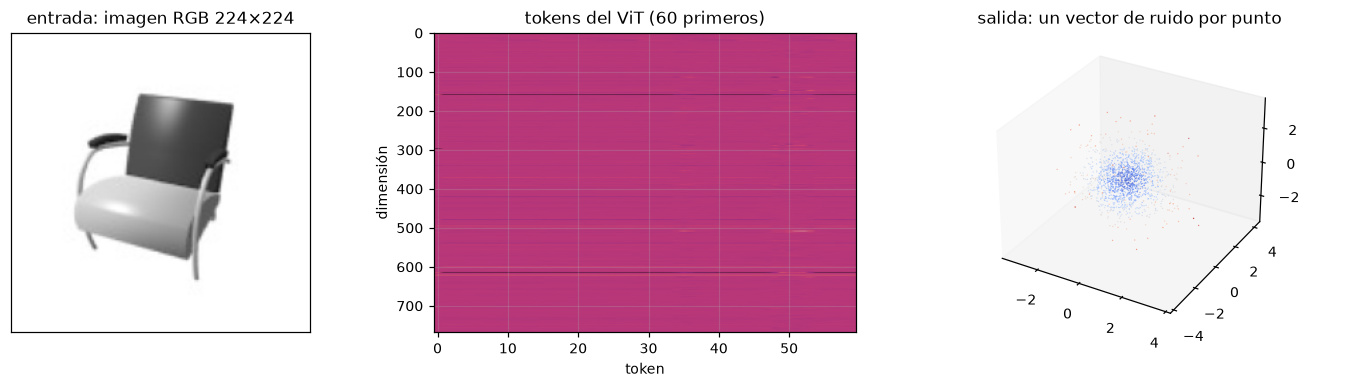

In [15]:
# =============================================================================
# 5 · ENTRADAS, SALIDAS Y VIAJE DE LOS TENSORES
# =============================================================================
registro = []
ganchos = []
def observa(nombre):
    def h(mod, entrada, salida):
        s = salida[0] if isinstance(salida, tuple) else salida
        if hasattr(s, "shape"):
            registro.append((nombre, tuple(s.shape)))
    return h

ganchos.append(modelo.pointnet_sa.register_forward_hook(
    lambda m, i, o: registro.append(("capa SA · tokens geométricos", tuple(o[2].shape)))))
ganchos.append(modelo.encoder.blocks[0].register_forward_hook(observa("bloque Transformer 1")))
ganchos.append(modelo.encoder.blocks[-1].register_forward_hook(observa(f"bloque Transformer {CFG['depth']}")))
ganchos.append(modelo.pointnet_fp.register_forward_hook(observa("capa FP · ruido predicho")))

k_demo = int(np.where(Y_te == CATS.index("silla"))[0][0]) if "silla" in CATS else 0
img_demo = IMG_te[k_demo:k_demo + 1].to(DEVICE)
x_demo = X_te[k_demo:k_demo + 1].to(DEVICE) * CFG["escala"]
with torch.no_grad():
    rasgos_demo = vit(img_demo)
    t_demo = torch.full((1,), CFG["T"] // 2, device=DEVICE, dtype=torch.long)
    ruido_demo = modelo(DIF.q_sample(x_demo, t_demo, torch.randn_like(x_demo)), rasgos_demo, t_demo)
for g in ganchos:
    g.remove()

filas = [("imagen de entrada", tuple(img_demo.shape), "RGB de una sola vista"),
         ("tokens de imagen (ViT)", tuple(rasgos_demo.shape), "196 parches + token de clase"),
         ("nube con ruido", tuple(x_demo.shape), "puntos en coordenadas ×" + str(CFG["escala"]))]
filas += [(n, f, "") for n, f in registro]
filas += [("condición (t + imagen)", (1, rasgos_demo.shape[1] + 1, CFG["dim"]), "lo que ve la atención cruzada"),
          ("salida: ruido por punto", tuple(ruido_demo.shape), "mismo tamaño que la nube")]
tab_io = pd.DataFrame(filas, columns=["etapa", "forma del tensor", "comentario"])
display(tab_io.style.hide(axis="index"))

fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
ax[0].imshow(img_demo[0].cpu().numpy().transpose(1, 2, 0)); ax[0].set_title("entrada: imagen RGB 224×224")
ax[0].set_xticks([]); ax[0].set_yticks([]); ax[0].grid(False)
ax[1].imshow(rasgos_demo[0].cpu().numpy()[:60].T, aspect="auto", cmap="magma")
ax[1].set_title("tokens del ViT (60 primeros)"); ax[1].set_xlabel("token"); ax[1].set_ylabel("dimensión")
b = fig.add_subplot(1, 3, 3, projection="3d"); ax[2].axis("off")
sal = ruido_demo[0].cpu().numpy()[::max(1, CFG["n_puntos"] // 1200)]
b.scatter(sal[:, 0], sal[:, 2], sal[:, 1], s=.8, c=np.linalg.norm(sal, axis=1), cmap="coolwarm", lw=0)
b.set_title("salida: un vector de ruido por punto"); b.grid(False)
plt.tight_layout(); guarda("entradas_salidas"); plt.show()

tarjeta("5 · Qué entra y qué sale",
        "Formas reales de todos los tensores en una pasada del modelo cargado, con la imagen y la nube de un "
        f"objeto de la categoría <b>{CATS[Y_te[k_demo]]}</b>.",
        [f"La imagen se convierte en <b>{rasgos_demo.shape[1]}</b> tokens de {rasgos_demo.shape[2]} dimensiones.",
         f"La nube de {CFG['n_puntos']} puntos se resume en <b>{CFG['n_centros']}</b> tokens de la misma dimensión.",
         f"La salida tiene exactamente la forma de la entrada: {tuple(ruido_demo.shape)}."],
        ["Que imagen y nube compartan dimensión no es casual: es lo que permite concatenarlas y dejar que la "
         "atención decida qué mirar.",
         "El Transformer nunca procesa los 8192 puntos: trabaja sobre 512 tokens, y de ahí que la atención sea "
         "computacionalmente viable.",
         "El modelo no predice el objeto, sino el <b>ruido</b> que contamina la nube actual; el objeto aparece "
         "al restarlo muchas veces seguidas."],
        "El modelo recibe una imagen, una nube contaminada con ruido y el paso de difusión, y devuelve el desplazamiento que aproxima cada punto al objeto.")

# 6 · El mecanismo de atención y los tensores Q, K y V

**Qué hace:** extrae de los pesos oficiales las matrices que generan $Q$, $K$ y $V$, calcula la atención **a mano** y compara el resultado con el que produce PyTorch. Si ambos coinciden hasta la precisión de la máquina, la explicación no es una analogía: es la operación exacta que ejecuta el modelo.

**Cómo se generan los tres tensores en esta arquitectura.** Los autores usan una única matriz $W_{qkv}$ de $768 \times 2304$ que produce los tres a la vez sobre la secuencia concatenada:

$$[Q \mid K \mid V] = \mathrm{LN}(X)\,W_{qkv}, \qquad
\mathrm{Atención}(Q,K,V) = \mathrm{softmax}\!\left(\frac{QK^{\top}}{\sqrt{d_h}}\right)V$$

- En la **auto-atención** la secuencia es $[\,c \mid x\,]$ y después se conserva solo la parte de $x$: los tokens de la nube se miran entre sí y también miran la condición.
- En la **atención cruzada** la secuencia es $[\,x \mid c\,]$ y se conserva la parte de $x$: cada token de la nube consulta los tokens de la imagen.

Con dimensión 768 y 8 cabezas, cada cabeza trabaja en $d_h = 96$ dimensiones.

Q, K, V: (1, 711, 768) · cabezas: 8 · dimensión por cabeza: 96
Error entre el cálculo manual y el del modelo: 2.10e-04


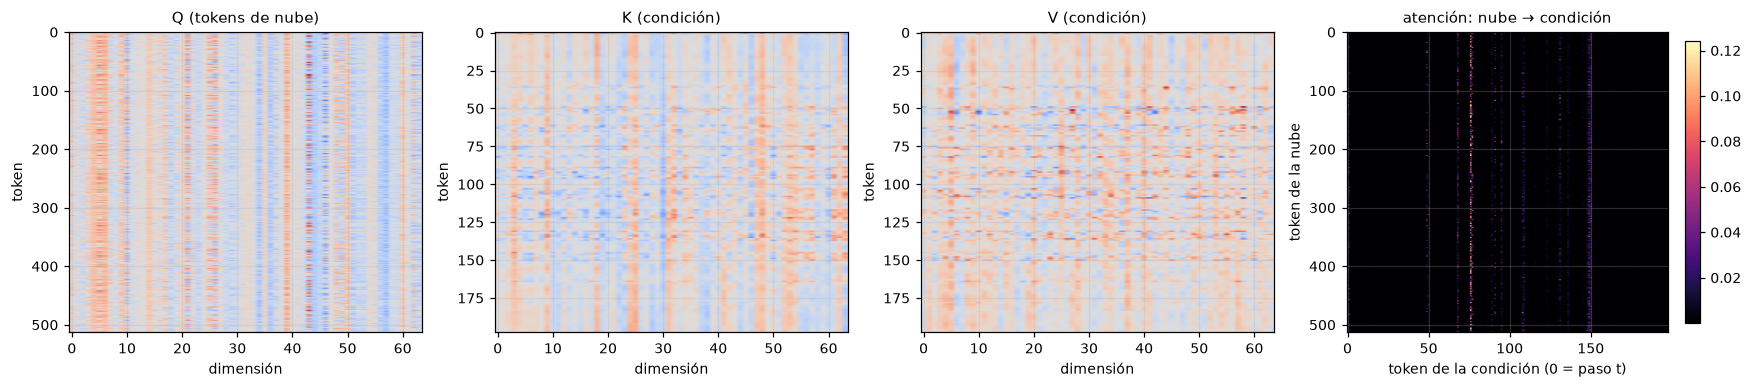

In [16]:
# =============================================================================
# 6 · Q, K y V EXTRAÍDOS DE LOS PESOS OFICIALES
# =============================================================================
bloque = modelo.encoder.blocks[-1]
capa = bloque.cross_attention
H = capa.num_heads; D = CFG["dim"]; DH = D // H

with torch.no_grad():
    # secuencia de la atención cruzada: [tokens de nube | condición]
    lista_r, lista_c, tokens, centros = modelo.pointnet_sa(DIF.q_sample(
        x_demo, t_demo, torch.randn_like(x_demo)))
    tokens = tokens.transpose(-1, -2); centros_t = centros.transpose(-1, -2)
    x0 = torch.cat((modelo.cls_token, tokens), 1) + torch.cat((modelo.cls_pos,
                                                               modelo.pos_embed(centros_t)), 1)
    cond = torch.cat((codifica_paso(D, t_demo, DEVICE).unsqueeze(1), rasgos_demo), 1)
    x1 = x0 + bloque.attn(bloque.norm1(torch.cat((cond, x0), 1)))[:, cond.shape[1]:, :]
    sec = bloque.norm2(torch.cat((x1, cond), 1))                      # entrada de la atención cruzada

    W = capa.qkv.weight                                               # (2304, 768)
    Wq, Wk, Wv = W[:D], W[D:2 * D], W[2 * D:]
    Q = sec @ Wq.T; K = sec @ Wk.T; V = sec @ Wv.T                    # cálculo manual
    qh = Q.view(1, -1, H, DH).transpose(1, 2)
    kh = K.view(1, -1, H, DH).transpose(1, 2)
    vh = V.view(1, -1, H, DH).transpose(1, 2)
    A = (qh @ kh.transpose(-2, -1)) * (DH ** -0.5)
    A = A.softmax(-1)
    manual = capa.proj((A @ vh).transpose(1, 2).reshape(1, -1, D))
    oficial = capa(sec)                                               # implementación del modelo
err_salida = float((manual - oficial).abs().max())

n_x = x1.shape[1]                                                     # tokens de nube (incluye cls)
A_cruzada = A[0, :, :n_x, n_x:]                                       # nube consultando la condición
print(f"Q, K, V: {tuple(Q.shape)} · cabezas: {H} · dimensión por cabeza: {DH}")
print(f"Error entre el cálculo manual y el del modelo: {err_salida:.2e}")

fig, ax = plt.subplots(1, 4, figsize=(16, 3.6))
for a, (t, m) in zip(ax[:3], [("Q (tokens de nube)", Q[0, :n_x, :64]), ("K (condición)", K[0, n_x:, :64]),
                              ("V (condición)", V[0, n_x:, :64])]):
    a.imshow(m.cpu().numpy(), aspect="auto", cmap="coolwarm"); a.set_title(t, fontsize=10)
    a.set_xlabel("dimensión"); a.set_ylabel("token")
im = ax[3].imshow(A_cruzada.mean(0).cpu().numpy(), aspect="auto", cmap="magma")
ax[3].set_title("atención: nube → condición", fontsize=10)
ax[3].set_xlabel("token de la condición (0 = paso t)"); ax[3].set_ylabel("token de la nube")
plt.colorbar(im, ax=ax[3], fraction=.04)
plt.tight_layout(); guarda("qkv"); plt.show()

tarjeta("6 · Q, K y V calculados a mano sobre los pesos oficiales",
        "Los tres tensores salen de una sola matriz de 768×2304 aplicada a la secuencia normalizada. "
        "El último panel muestra cuánto pesa cada token de la condición para cada token de la nube.",
        [f"Formas: Q, K y V de {tuple(Q.shape)}, repartidos en <b>{H} cabezas</b> de {DH} dimensiones.",
         f"El cálculo manual y el del modelo coinciden con un error máximo de <b>{err_salida:.1e}</b>.",
         "En la atención cruzada las claves y los valores provienen de la condición; las consultas, de la nube."],
        ["Un error del orden del límite de la coma flotante demuestra que la explicación reproduce la "
         "operación real, no una versión simplificada.",
         "Las consultas preguntan «¿qué parte de la imagen me corresponde?» y los valores aportan la respuesta "
         "que se suma al token de la nube.",
         "Compartir una sola matriz para los tres tensores es solo una optimización de implementación: "
         "matemáticamente son tres proyecciones independientes."],
        "Las consultas proceden de la nube y las claves y valores de la condición visual; esa asimetría constituye el mecanismo por el que la imagen se incorpora a la geometría.")

## 6.1 · ¿Qué mira el modelo en la imagen?

**Qué hace:** los tokens del ViT corresponden a una rejilla de 14×14 parches sobre la imagen. Reordenando los pesos de atención sobre esa rejilla se obtiene un mapa que indica qué zonas de la foto consulta el modelo, y puede superponerse a la imagen original.

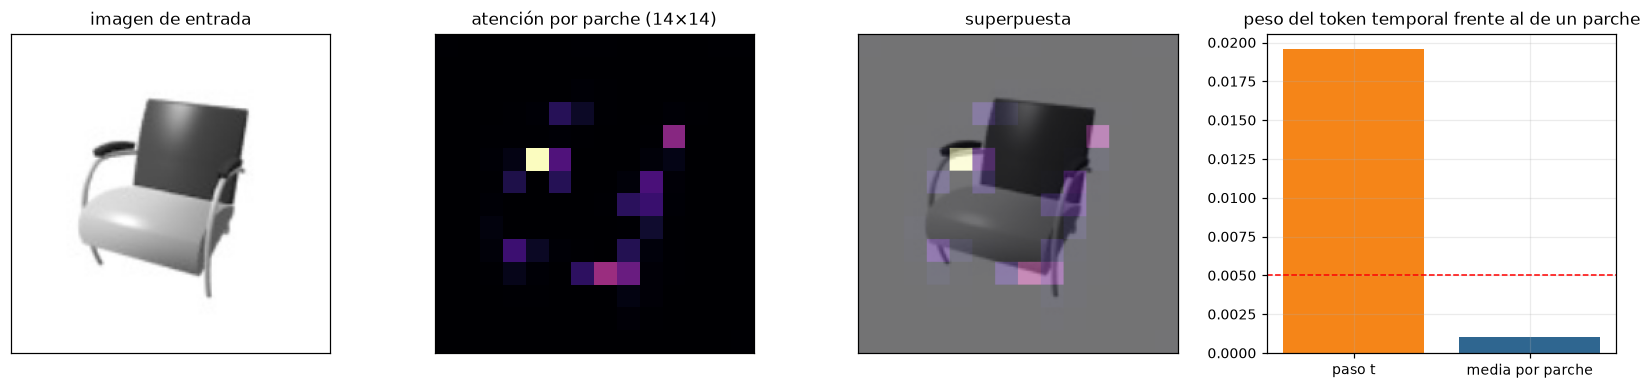

In [17]:
# =============================================================================
# 6.1 · MAPA DE ATENCIÓN SOBRE LOS PARCHES DE LA IMAGEN
# =============================================================================
peso_medio = A_cruzada.mean(0).mean(0)                      # media sobre cabezas y tokens de nube
peso_t = float(peso_medio[0])                               # token del paso temporal
pesos_img = peso_medio[2:].cpu().numpy()                    # se descarta también el token de clase del ViT
lado = int(round(len(pesos_img) ** 0.5))
mapa = pesos_img[:lado * lado].reshape(lado, lado)
uniforme = 1.0 / peso_medio.numel()
ent = float(-(peso_medio * (peso_medio + 1e-12).log()).sum())
ent_max = float(np.log(peso_medio.numel()))

img_np = img_demo[0].cpu().numpy().transpose(1, 2, 0)
fig, ax = plt.subplots(1, 4, figsize=(15, 3.6))
ax[0].imshow(img_np); ax[0].set_title("imagen de entrada"); ax[0].set_xticks([]); ax[0].set_yticks([])
ax[1].imshow(mapa, cmap="magma"); ax[1].set_title(f"atención por parche ({lado}×{lado})")
ax[1].set_xticks([]); ax[1].set_yticks([])
grande = np.kron(mapa, np.ones((img_np.shape[0] // lado, img_np.shape[1] // lado)))
ax[2].imshow(img_np); ax[2].imshow(grande, cmap="magma", alpha=.55,
                                   extent=(0, img_np.shape[1], img_np.shape[0], 0))
ax[2].set_title("superpuesta"); ax[2].set_xticks([]); ax[2].set_yticks([])
ax[3].bar(["paso t", "media por parche"], [peso_t, float(pesos_img.mean())], color=["#f58518", "#2f6690"])
ax[3].axhline(uniforme, color="red", ls="--", lw=1)
ax[3].set_title("peso del token temporal frente al de un parche")
for a in ax[:3]:
    a.grid(False)
plt.tight_layout(); guarda("atencion"); plt.show()

sil = (img_np.mean(-1) < 0.9).astype(np.float32)            # silueta aproximada del objeto
sil_p = sil.reshape(lado, img_np.shape[0] // lado, lado, img_np.shape[1] // lado).mean((1, 3))
corr = float(np.corrcoef(mapa.ravel(), sil_p.ravel())[0, 1])
tarjeta("6.1 · Dónde mira la atención cruzada",
        "Pesos de atención de los tokens de la nube sobre los parches de la imagen, reordenados en la rejilla "
        f"{lado}×{lado} del ViT y superpuestos a la foto.",
        [f"Entropía de la distribución: <b>{100*ent/ent_max:.0f} %</b> de la máxima posible.",
         f"El token del paso temporal recibe <b>{peso_t/uniforme:.1f}×</b> el peso de un reparto uniforme.",
         f"Correlación entre el mapa de atención y la silueta del objeto: <b>{corr:+.2f}</b>."],
        ["Una entropía alta indica una atención repartida: el modelo usa la imagen como un resumen global "
         "—categoría y orientación— más que como un mapa punto a punto.",
         "El peso elevado del token temporal es coherente con la tarea: antes de decidir cuánto corregir, el "
         "modelo necesita saber cuánto ruido queda.",
         "Si la correlación con la silueta es positiva, la atención sigue al objeto; si es negativa, domina el "
         "comportamiento de token-ancla documentado en Transformers."],
        "La atención cruzada es el único punto de entrada de la información visual, y su distribución puede observarse directamente sobre la imagen.")

## 6.2 · Q, K y V en un ejemplo mínimo, calculado a mano

**Qué hace:** repite la atención sobre un caso diminuto —tres tokens y cuatro dimensiones— donde cada número puede leerse. Permite seguir el mecanismo sin recurrir a matrices de 768 columnas.

**La ecuación, término a término:**

$$Q = X W_q,\qquad K = C W_k,\qquad V = C W_v$$
$$\mathrm{Atención}(Q,K,V) = \underbrace{\mathrm{softmax}\!\left(\frac{QK^{\top}}{\sqrt{d_h}}\right)}_{\text{pesos: a quién escuchar}} \underbrace{V}_{\text{qué dice cada uno}}$$

| Símbolo | Quién lo genera | Qué representa |
|---|---|---|
| $Q$ (*query*) | los tokens de la nube | la pregunta: «¿qué parte de la imagen me corresponde?» |
| $K$ (*key*) | los tokens de la condición | la etiqueta de cada parche: «yo contengo esto» |
| $V$ (*value*) | los tokens de la condición | el contenido que se entrega si la pregunta encaja |
| $QK^{\top}$ | — | cuánto encaja cada pregunta con cada etiqueta |
| $\sqrt{d_h}$ | — | evita que el producto crezca con la dimensión y sature el softmax |

**Interpretación de la operación.** El producto $QK^{\top}$ mide la afinidad entre cada consulta y cada clave; la función softmax convierte esas afinidades en una distribución de probabilidad sobre los elementos de la condición, y la salida es la esperanza de los valores bajo esa distribución. Ningún elemento se descarta: todos contribuyen, ponderados por su afinidad.


Q = X·Wq  (2 tokens de nube)
[[1. 0. 0. 0.]
 [0. 1. 0. 0.]]

K = C·Wk  (3 parches)
[[1.  0.  0.2 0. ]
 [0.  1.  0.  0.2]
 [0.5 0.5 1.  1. ]]

V = C·Wv  (3 parches)
[[1.  0.  0.4 0. ]
 [0.  1.  0.  0.4]
 [0.5 0.5 2.  2. ]]

QKᵀ/√dh  (afinidad)
[[0.5  0.   0.25]
 [0.   0.5  0.25]]

softmax(·)  (pesos)
[[0.419 0.254 0.326]
 [0.254 0.419 0.326]]

salida = pesos·V
[[0.582 0.418 0.821 0.755]
 [0.418 0.582 0.755 0.821]]


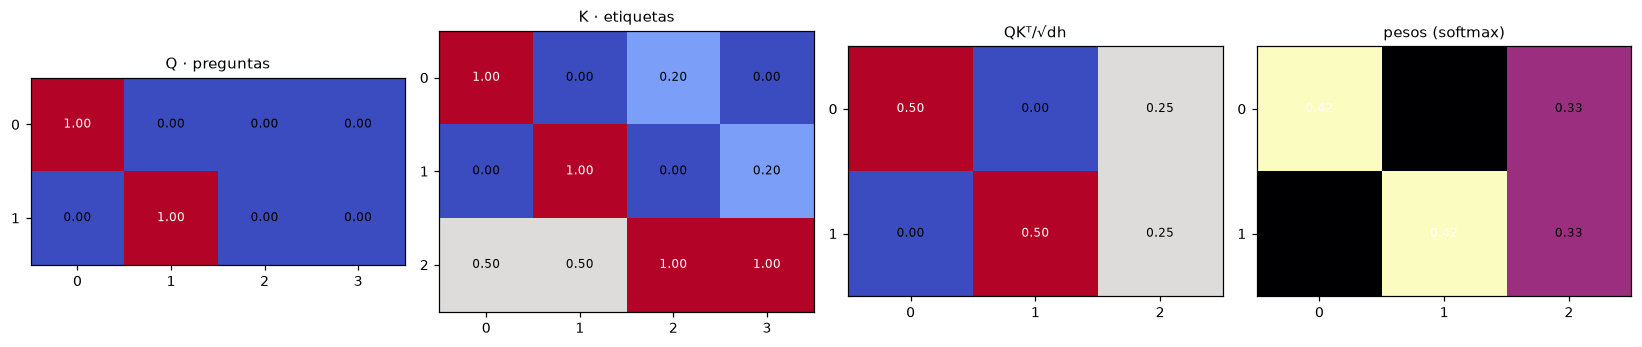

In [18]:
# =============================================================================
# 6.2 · EJEMPLO MÍNIMO: TRES TOKENS, CUATRO DIMENSIONES
# =============================================================================
torch.manual_seed(0)
d_min, dh_min = 4, 4
X_min = torch.tensor([[1., 0., 0., 0.],      # token de nube A
                      [0., 1., 0., 0.]])     # token de nube B
C_min = torch.tensor([[1., 0., .2, 0.],      # parche de imagen 1 (parecido a A)
                      [0., 1., 0., .2],      # parche de imagen 2 (parecido a B)
                      [.5, .5, 1., 1.]])     # parche de imagen 3 (mezcla)
Wq = torch.eye(d_min); Wk = torch.eye(d_min); Wv = torch.tensor(
    [[1., 0., 0., 0.], [0., 1., 0., 0.], [0., 0., 2., 0.], [0., 0., 0., 2.]])

Q_min, K_min, V_min = X_min @ Wq, C_min @ Wk, C_min @ Wv
puntuaciones = Q_min @ K_min.T / np.sqrt(dh_min)
pesos = puntuaciones.softmax(-1)
salida = pesos @ V_min

for nombre, M_ in [("Q = X·Wq  (2 tokens de nube)", Q_min), ("K = C·Wk  (3 parches)", K_min),
                   ("V = C·Wv  (3 parches)", V_min),
                   ("QKᵀ/√dh  (afinidad)", puntuaciones), ("softmax(·)  (pesos)", pesos),
                   ("salida = pesos·V", salida)]:
    print(f"\n{nombre}")
    print(np.array2string(M_.numpy(), precision=3, suppress_small=True))

fig, ax = plt.subplots(1, 4, figsize=(15, 3.1))
for a, (M_, t) in zip(ax, [(Q_min, "Q · preguntas"), (K_min, "K · etiquetas"),
                           (puntuaciones, "QKᵀ/√dh"), (pesos, "pesos (softmax)")]):
    im = a.imshow(M_.numpy(), cmap="coolwarm" if "√" in t or "Q" in t or "K" in t else "magma")
    a.set_title(t, fontsize=10); a.grid(False)
    for (i, j), v in np.ndenumerate(M_.numpy()):
        a.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8,
               color="black" if M_.numpy().max() - v > .3 * (np.ptp(M_.numpy()) + 1e-9) else "white")
    a.set_xticks(range(M_.shape[1])); a.set_yticks(range(M_.shape[0]))
plt.tight_layout(); guarda("qkv_minimo"); plt.show()

tarjeta("6.2 · El mecanismo en seis números",
        "La misma operación de la sección anterior, con dos tokens de nube y tres parches de imagen, donde "
        "cada valor puede seguirse a mano.",
        [f"El token A reparte su atención así: {np.array2string(pesos[0].numpy(), precision=2)}; "
         "su mayor peso va al parche que más se le parece.",
         "La división por √dh mantiene las afinidades en un rango donde el softmax no satura.",
         "La salida de cada token es una mezcla ponderada de los valores, no una selección de uno solo."],
        ["La atención no elige un parche: pondera todos. Por eso una distribución repartida sigue siendo "
         "informativa, y por eso puede resumir la imagen completa.",
         "Cambiar Wq, Wk o Wv cambia qué se considera «parecido»: esas matrices son justamente lo que el "
         "entrenamiento aprende.",
         "El mismo cálculo, con 768 dimensiones y 8 cabezas en paralelo, es el que ejecuta el modelo oficial."],
        "El ejemplo reducido reproduce íntegramente la operación que ejecuta el modelo, con la única diferencia de la dimensión empleada.")

# 7 · La innovación del artículo

**Qué hace:** replica la Figura 1 del artículo con nubes de esta ejecución y señala, sobre el código cargado, dónde está exactamente la aportación.

**La aportación en una frase.** El método anterior, PC², proyectaba los rasgos de la imagen sobre los puntos usando la cámara: solo los puntos visibles recibían información, y el control era inestable. TrDPNet sustituye esa proyección por **atención cruzada**: cada token de la nube consulta *toda* la imagen en *cada* bloque y en *cada* paso de la difusión.

**Dónde está en el código:** en `TransformerBlock.forward`, el subbloque `cross_attention` sobre la secuencia `cat(x, c)`. Es el tercer subbloque residual, el que no existe en el Transformer clásico.

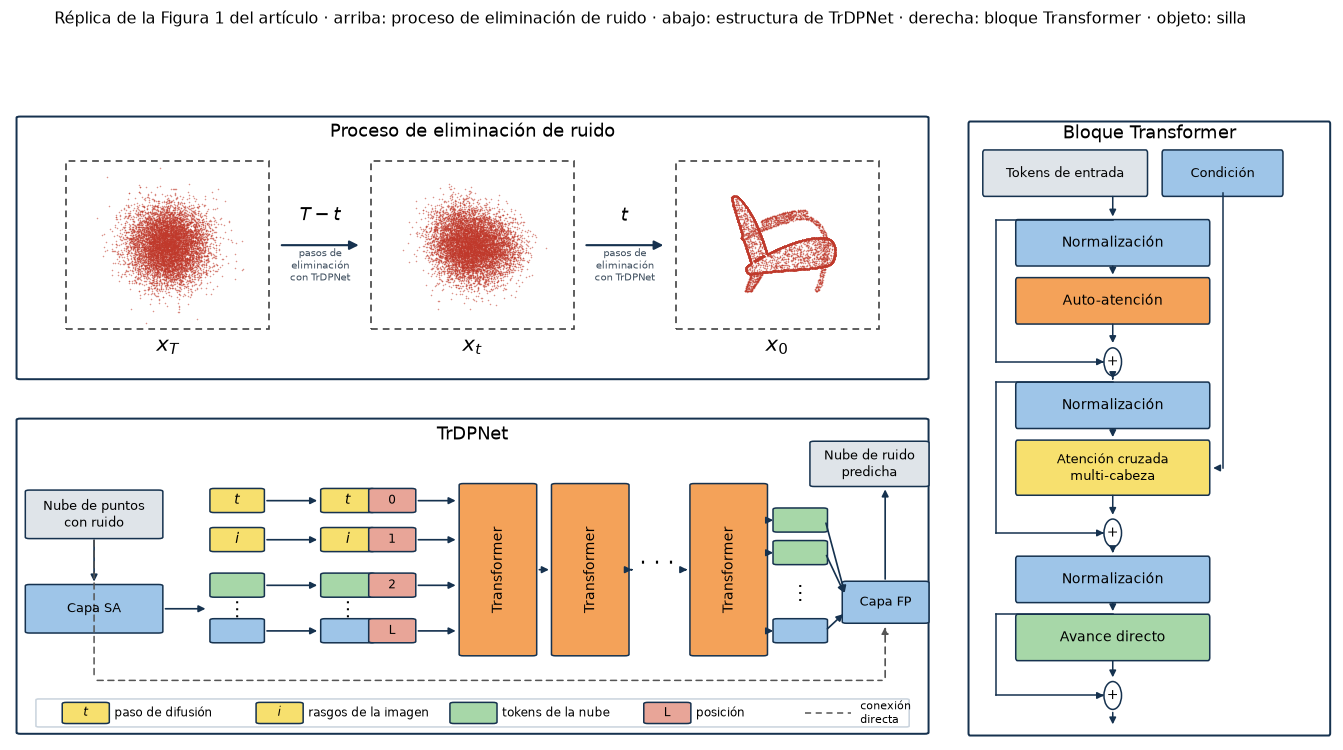

class TransformerBlock(nn.Module):
    '''Bloque del artículo: auto-atención sobre [c, x], atención cruzada sobre [x, c] y MLP.'''
    def __init__(self, dim=768, mlp_dim=3072, drop_rate=0.0):
        super().__init__()
        self.norm1 = nn.LayerNorm(dim)
        self.attn = Attention(dim)
        self.norm2 = nn.LayerNorm(dim)
        self.cross_attention = Attention(dim)
        self.norm3 = nn.LayerNorm(dim)
        self.mlp = nn.Sequential(nn.Linear(dim, mlp_dim), nn.GELU(), nn.Dropout(drop_rate),
                                 nn.Linear(mlp_dim, dim), nn.Dropout(drop_rate))

    def forward(self, x, c, guardar=False):
        x = x + self.attn(self.norm1(torch.cat((c, x), dim=1)))[:, c.shape[1]:, :]
        x = x + self.cross_attention(self.norm2(torch.cat((x, c), dim=1)), guardar)[:, :x.shape[1], :]
        return x + self.mlp(self.norm3(x))


In [19]:
# =============================================================================
# 7 · RÉPLICA DE LA FIGURA 1 Y LOCALIZACIÓN DE LA INNOVACIÓN
# =============================================================================
def figura_uno(x0, xt, xT, titulo_extra=""):
    '''Reproduce la Figura 1 del artículo usando nubes reales de este proyecto.

    x0: objeto limpio · xt: estado intermedio · xT: ruido puro (cada uno (N,3)).'''
    AZ, NA, VE, AM, GR, RO = "#9ec5e8", "#f4a259", "#a7d7a8", "#f7e06e", "#dfe4e9", "#e8a598"
    T3 = "#16324f"
    fig = plt.figure(figsize=(15.5, 7.4))
    gs = fig.add_gridspec(2, 2, width_ratios=[2.9, 1.15], height_ratios=[1, 1.2], wspace=0.05, hspace=0.1)

    # =================== panel superior izquierdo ============================
    ax = fig.add_subplot(gs[0, 0]); ax.set_xlim(0, 100); ax.set_ylim(0, 100); ax.axis("off")
    ax.add_patch(FancyBboxPatch((1, 2), 98, 96, boxstyle="round,pad=0.4", fc="white", ec=T3, lw=1.3))
    ax.text(50, 91, "Proceso de eliminación de ruido", ha="center", fontsize=12)
    for p, cx, etq in [(xT, 17, "$x_T$"), (xt, 50, "$x_t$"), (x0, 83, "$x_0$")]:
        ax.add_patch(Rectangle((cx - 11, 20), 22, 62, fill=False, ec="#444", ls=(0, (4, 3)), lw=1.1))
        sub = ax.inset_axes([(cx - 10.5) / 100, 0.21, 0.21, 0.60])
        sub.scatter(p[:, 0], p[:, 1], s=1.0, c="#c0392b", alpha=.55, lw=0)
        lim = max(0.7, float(np.abs(p[:, :2]).max()) * 1.05)
        sub.set_xlim(-lim, lim); sub.set_ylim(-lim, lim)
        sub.set_aspect("equal"); sub.axis("off"); sub.patch.set_alpha(0)
        ax.text(cx, 12, etq, ha="center", fontsize=14)
    for x1, x2, arriba in [(29, 38, "$T-t$"), (62, 71, "$t$")]:
        ax.add_patch(FancyArrowPatch((x1, 51), (x2, 51), arrowstyle="-|>", mutation_scale=12, lw=1.4, color=T3))
        ax.text((x1 + x2) / 2, 60, arriba, ha="center", fontsize=12)
        ax.text((x1 + x2) / 2, 38, "pasos de\neliminación\ncon TrDPNet",
                ha="center", fontsize=6.5, color="#405060")

    # =================== panel inferior izquierdo ============================
    ax = fig.add_subplot(gs[1, 0]); ax.set_xlim(0, 100); ax.set_ylim(0, 100); ax.axis("off")
    ax.add_patch(FancyBboxPatch((1, 2), 98, 96, boxstyle="round,pad=0.4", fc="white", ec=T3, lw=1.3))
    ax.text(50, 92, "TrDPNet", ha="center", fontsize=12)

    def caja(x, y, w, h, txt, fc, fs=8.5):
        ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.45", fc=fc, ec=T3, lw=1.0))
        ax.text(x + w / 2, y + h / 2, txt, ha="center", va="center", fontsize=fs)

    def fle(p, q, ls="-", c=T3, lw=1.1):
        ax.add_patch(FancyArrowPatch(p, q, arrowstyle="-|>", mutation_scale=9, lw=lw, color=c, ls=ls))

    caja(2, 62, 14, 14, "Nube de puntos\ncon ruido", GR)
    caja(2, 33, 14, 14, "Capa SA", AZ)
    fle((9, 62), (9, 47.4))
    fle((16.4, 40), (21.4, 40))
    filas = [(70, "$t$", AM, "0"), (58, "$i$", AM, "1"), (44, "", VE, "2"), (30, "", AZ, "L")]
    for y, tx, col, pos in filas:
        caja(22, y, 5, 6.5, tx, col, fs=9)
        fle((27.4, y + 3.2), (33.5, y + 3.2))
        caja(34, y, 5, 6.5, tx, col, fs=9)
        caja(39.2, y, 4.2, 6.5, pos, RO, fs=8)
        fle((43.8, y + 3.2), (48.5, y + 3.2))
    ax.text(24.5, 38, "⋮", ha="center", fontsize=13)
    ax.text(36.5, 38, "⋮", ha="center", fontsize=13)
    for x in (49, 59, 74):
        ax.add_patch(FancyBboxPatch((x, 26), 7.5, 52, boxstyle="round,pad=0.45", fc=NA, ec=T3, lw=1.0))
        ax.text(x + 3.75, 52, "Transformer", ha="center", va="center", fontsize=9, rotation=90)
    ax.text(70, 52, "· · ·", ha="center", fontsize=14)
    fle((56.9, 52), (58.6, 52)); fle((66.9, 52), (67.6, 52)); fle((72.6, 52), (73.6, 52))
    for y, col in [(64, VE), (54, VE), (30, AZ)]:
        caja(83, y, 5, 6.5, "", col)
        fle((81.6, y + 3.2), (82.9, y + 3.2))
    ax.text(85.5, 43, "⋮", ha="center", fontsize=13)
    caja(90.5, 36, 8.5, 12, "Capa FP", AZ)
    caja(87, 78, 12, 13, "Nube de ruido\npredicha", GR)
    for y in (64, 54, 30):
        fle((88.2, y + 3.2), (90.4, 44 if y > 40 else 39))
    fle((94.7, 48.2), (94.7, 77.6))
    ax.add_patch(FancyArrowPatch((9, 62), (9, 18), arrowstyle="-", ls=(0, (4, 3)), lw=1, color="#555"))
    ax.add_patch(FancyArrowPatch((9, 18), (94.7, 18), arrowstyle="-", ls=(0, (4, 3)), lw=1, color="#555"))
    fle((94.7, 18), (94.7, 35.4), ls=(0, (4, 3)), c="#555")
    ax.add_patch(FancyBboxPatch((3, 4), 94, 8, boxstyle="round,pad=0.3", fc="white", ec="#c9d3dd"))
    x = 6
    for tx, col, txt in [("$t$", AM, "paso de difusión"), ("$i$", AM, "rasgos de la imagen"),
                         ("", VE, "tokens de la nube"), ("L", RO, "posición")]:
        caja(x, 5.2, 4.2, 5.6, tx, col, fs=8)
        ax.text(x + 5.2, 8, txt, va="center", fontsize=8)
        x += 21
    ax.plot([86, 91], [8, 8], ls=(0, (4, 3)), color="#555", lw=1)
    ax.text(92, 8, "conexión\ndirecta", va="center", fontsize=7)

    # =================== panel derecho: bloque Transformer ===================
    ax = fig.add_subplot(gs[:, 1]); ax.set_xlim(0, 100); ax.set_ylim(-8, 100); ax.axis("off")
    ax.add_patch(FancyBboxPatch((1, -7), 98, 105, boxstyle="round,pad=0.4", fc="white", ec=T3, lw=1.3))
    ax.text(50, 95.5, "Bloque Transformer", ha="center", fontsize=11.5)

    def cajab(y, txt, fc, x=14, w=52, h=7, fs=9):
        ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.5", fc=fc, ec=T3, lw=1.0))
        ax.text(x + w / 2, y + h / 2, txt, ha="center", va="center", fontsize=fs)

    def suma(y):
        ax.add_patch(Circle((40, y), 2.4, fc="white", ec=T3, lw=1.0))
        ax.text(40, y, "+", ha="center", va="center", fontsize=9)

    def fle2(p, q, c=T3, ls="-"):
        ax.add_patch(FancyArrowPatch(p, q, arrowstyle="-|>", mutation_scale=9, lw=1.0, color=c, ls=ls))

    cajab(86, "Tokens de entrada", GR, x=5, w=44, h=7, fs=8.5)
    cajab(86, "Condición", AZ, x=54, w=32, h=7, fs=8.5)
    cajab(74, "Normalización", AZ)
    cajab(64, "Auto-atención", NA)
    suma(57)
    cajab(46, "Normalización", AZ)
    cajab(34.5, "Atención cruzada\nmulti-cabeza", AM, h=8.5, fs=8.5)
    suma(27.5)
    cajab(16, "Normalización", AZ)
    cajab(6, "Avance directo", VE)
    suma(-0.5)
    for ya, yb in [(86, 81.5), (74, 71.5), (64, 59.7), (54.6, 53.5), (46, 43.5), (34.5, 30.1), (25.1, 23.5),
                   (16, 13.5), (6, 2.1)]:
        fle2((40, ya), (40, yb))
    for ya, yb in [(81.5, 57), (53.5, 27.5), (13.5, -0.5)]:      # conexiones residuales
        ax.plot([8, 8], [ya, yb], color=T3, lw=1.0)
        ax.plot([8, 37.4], [yb, yb], color=T3, lw=1.0)
        ax.plot([8, 40], [ya, ya], color=T3, lw=1.0)
        fle2((36, yb), (37.6, yb))
    ax.plot([70, 70], [86, 38.7], color=T3, lw=1.0)              # la condición entra en la atención cruzada
    fle2((70, 38.7), (66.6, 38.7))
    fle2((40, -2.9), (40, -6))

    fig.suptitle("Réplica de la Figura 1 del artículo · arriba: proceso de eliminación de ruido · abajo: estructura "
                 f"de TrDPNet · derecha: bloque Transformer{titulo_extra}", fontsize=10.5, y=1.005)
    return fig

with torch.no_grad():
    x0_fig = X_te[k_demo].numpy()
    xt_fig = DIF.q_sample(x_demo, torch.tensor([int(CFG["T"] * .45)], device=DEVICE),
                          torch.randn_like(x_demo))[0].cpu().numpy() / CFG["escala"]
    xT_fig = (torch.randn_like(x_demo)[0].cpu().numpy()) * 0.5
fig = figura_uno(x0_fig, xt_fig, xT_fig, titulo_extra=f" · objeto: {CATS[Y_te[k_demo]]}")
guarda("fig1_articulo"); plt.show()

print(fuente_de("TransformerBlock"))

tarjeta("7 · La arquitectura completa y el punto exacto de la innovación",
        "Réplica de la Figura 1 del artículo con nubes de esta ejecución, y el código del bloque Transformer "
        "cargado con los pesos oficiales.",
        ["El bloque tiene <b>tres</b> subbloques residuales: auto-atención, <b>atención cruzada</b> y avance directo.",
         "En la auto-atención la secuencia es <code>cat(c, x)</code> y se conserva la parte de la nube; en la "
         "atención cruzada es <code>cat(x, c)</code> y se conserva igualmente la parte de la nube.",
         f"La condición se consulta {CFG['depth']} veces por paso y {CFG['pasos_muestreo']} veces durante el muestreo."],
        ["Sustituir la proyección por atención elimina la dependencia de la cámara: ya no hace falta saber "
         "desde dónde se tomó la foto.",
         "Todos los puntos reciben información de la imagen, no solo los visibles, que era la limitación "
         "principal del método anterior.",
         "La consulta se repite en cada paso del muestreo, de modo que la condición guía la forma durante "
         "todo el recorrido y no solo al principio."],
        "La diferencia respecto del método anterior se concentra en un único subbloque: la atención cruzada.")

## 7.1 · Qué cambia frente al método anterior (PC²)

**Qué hace:** contrasta gráficamente las dos formas de meter la imagen en la nube. Responde de forma directa a la pregunta sobre en qué consiste la aportación del artículo.

| | PC² (método anterior) | TrDPNet (este artículo) |
|---|---|---|
| Cómo entra la imagen | se **proyecta** sobre los puntos usando la cámara | se **consulta** por atención cruzada |
| Qué puntos reciben información | solo los visibles desde la cámara | todos los tokens, en cada bloque |
| Requiere conocer la cámara | sí | no |
| Red de predicción de ruido | U-Net sobre PointNet | Transformer |
| Estabilidad del control | baja: depende de la geometría de la proyección | alta: la condición se consulta en cada paso |

**El argumento de fondo.** Proyectar es una operación local: un punto oculto detrás del objeto no recibe nada. La atención es una operación global: cualquier token puede consultar cualquier parche. Esa diferencia es la que el artículo mide como una mejora superior al 20 % sobre los métodos anteriores.

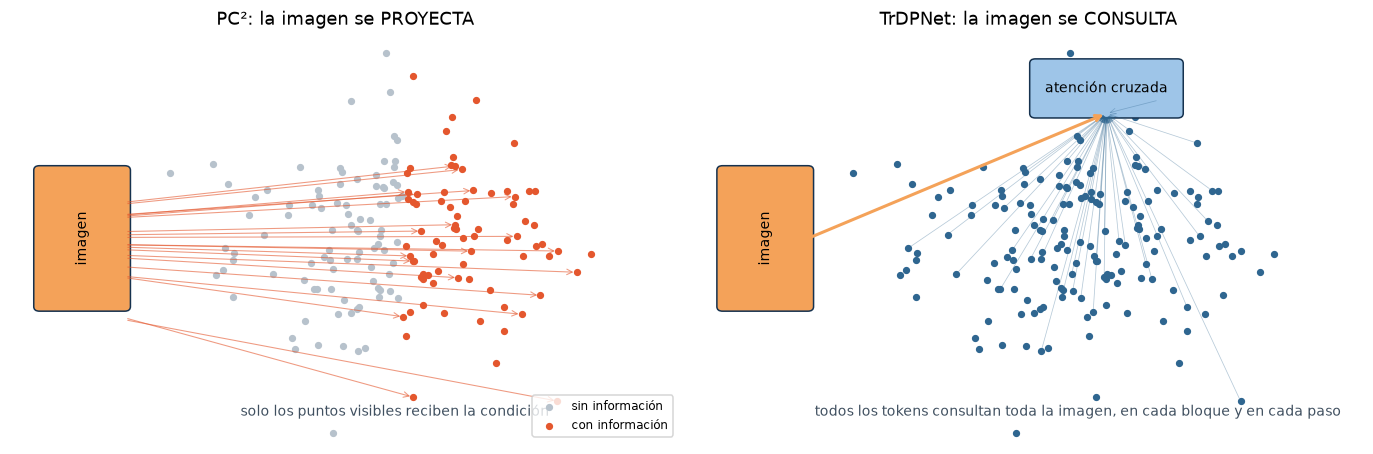

In [20]:
# =============================================================================
# 7.1 · PROYECCIÓN FRENTE A ATENCIÓN
# =============================================================================
rng_i = np.random.default_rng(3)
nube = rng_i.normal(0, .28, (170, 2))
visible = nube[:, 0] > np.quantile(nube[:, 0], .55)       # solo la cara hacia la cámara

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
for a, titulo in zip(ax, ["PC²: la imagen se PROYECTA", "TrDPNet: la imagen se CONSULTA"]):
    a.set_xlim(-1.35, 1); a.set_ylim(-.9, .9); a.axis("off"); a.set_title(titulo, fontsize=12)
    a.add_patch(FancyBboxPatch((-1.25, -.3), .3, .6, boxstyle="round,pad=.02", fc="#f4a259", ec="#16324f"))
    a.text(-1.1, 0, "imagen", ha="center", va="center", fontsize=9, rotation=90)
ax[0].scatter(nube[~visible, 0], nube[~visible, 1], s=14, c="#b7c2cc", label="sin información")
ax[0].scatter(nube[visible, 0], nube[visible, 1], s=14, c="#e4572e", label="con información")
for p in nube[visible][::4]:
    ax[0].annotate("", xy=p, xytext=(-.95, p[1] * .5),
                   arrowprops=dict(arrowstyle="->", color="#e4572e", lw=.7, alpha=.6))
ax[0].legend(fontsize=8, loc="lower right")
ax[0].text(0, -.78, "solo los puntos visibles reciben la condición", ha="center", fontsize=9, color="#405060")

ax[1].scatter(nube[:, 0], nube[:, 1], s=14, c="#2f6690")
ax[1].add_patch(FancyBboxPatch((-.15, .55), .5, .22, boxstyle="round,pad=.02", fc="#9ec5e8", ec="#16324f"))
ax[1].text(.1, .66, "atención cruzada", ha="center", va="center", fontsize=9)
for p in nube[::5]:
    ax[1].annotate("", xy=(.1, .55), xytext=p,
                   arrowprops=dict(arrowstyle="->", color="#2f6690", lw=.5, alpha=.35))
ax[1].annotate("", xy=(.1, .55), xytext=(-.95, 0),
               arrowprops=dict(arrowstyle="->", color="#f4a259", lw=2))
ax[1].text(0, -.78, "todos los tokens consultan toda la imagen, en cada bloque y en cada paso",
           ha="center", fontsize=9, color="#405060")
plt.tight_layout(); guarda("innovacion"); plt.show()

tarjeta("7.1 · Proyección frente a atención",
        "Las dos maneras de inyectar la imagen en la nube: proyectar desde la cámara (izquierda) o consultar "
        "por atención (derecha).",
        [f"Con proyección, solo el {100*visible.mean():.0f} % de los puntos del ejemplo recibiría información.",
         "Con atención, la información llega a todos los tokens sin necesidad de conocer la cámara.",
         f"La consulta se repite en los {CFG['depth']} bloques y en cada uno de los pasos del muestreo."],
        ["La proyección es local y depende de la geometría de la vista; la atención es global y aprendida.",
         "Prescindir de la cámara simplifica el problema y permite usar imágenes sin parámetros de calibración.",
         "El artículo atribuye a este cambio la mejora superior al 20 % frente a los métodos anteriores, y la "
         "mayor estabilidad del control condicional."],
        "PC² proyecta la imagen sobre los puntos visibles; TrDPNet permite que cada token consulte la totalidad de la imagen.")

# 8 · Inferencia funcional con los pesos oficiales

**Qué hace:** ejecuta el Algoritmo 2 del artículo. Se parte de ruido gaussiano y se recorre el programa de difusión hacia atrás; en cada paso el modelo se evalúa **dos veces**, con la imagen y con la condición anulada, y ambas predicciones se combinan con la escala de guía:

$$\hat\epsilon = \epsilon_\theta(x_t,\varnothing,t) + \omega\,\bigl(\epsilon_\theta(x_t,c,t) - \epsilon_\theta(x_t,\varnothing,t)\bigr)$$

El artículo usa $\omega = 3$. La condición anulada se implementa igual que en el código original: un tensor de ceros en lugar de los rasgos de la imagen.

  muestreo  96.0 %
Reconstrucción de un objeto: 23.1 s en cuda (250 pasos × 2 evaluaciones)


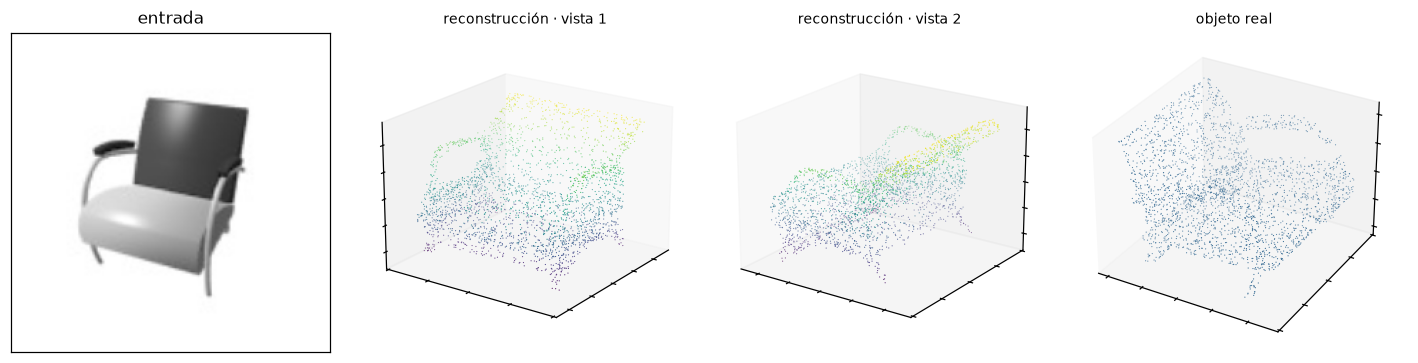

  guardado: outputs\nubes\silla_reconstruccion.obj  ·  outputs\nubes\silla_reconstruccion.ply
  guardado: outputs\nubes\silla_referencia.obj  ·  outputs\nubes\silla_referencia.ply


In [21]:
# =============================================================================
# 8 · RECONSTRUCCIÓN DESDE UNA SOLA IMAGEN
# =============================================================================
def reconstruye(indices, omega=None, pasos=None, semilla=11, guardar_pasos=False, verbose=True):
    '''Reconstruye las nubes de las muestras indicadas a partir de su imagen.'''
    omega = CFG["omega"] if omega is None else omega
    pasos = CFG["pasos_muestreo"] if pasos is None else pasos
    img = IMG_te[indices].to(DEVICE)
    trazas = []
    with torch.no_grad():
        rasgos = vit(img)
        cb = (lambda p: print(f"\r  muestreo {100*p:5.1f} %", end="", flush=True)) if verbose else None
        if guardar_pasos:
            trazas = []
            def cb2(p):
                if cb: cb(p)
            pred = muestrea_oficial(modelo, rasgos, CFG["n_puntos"], DIF, w=omega, pasos=pasos,
                                    escala=CFG["escala"], semilla=semilla, callback=cb2, device=DEVICE)
        else:
            pred = muestrea_oficial(modelo, rasgos, CFG["n_puntos"], DIF, w=omega, pasos=pasos,
                                    escala=CFG["escala"], semilla=semilla, callback=cb, device=DEVICE)
    if verbose:
        print()
    return pred

def a_cubo(p):
    '''Centra y escala una nube al cubo unitario para poder compararla con otra.'''
    p = p - p.mean(1, keepdim=True)
    return p / (p.abs().amax(dim=(1, 2), keepdim=True) + 1e-8) * 0.5

def guarda_obj(puntos, ruta, normales=None):
    '''Guarda la nube en formato .obj: una línea "v x y z" por punto.

    Es el formato más portátil para nubes y mallas: lo abren MeshLab, Blender, CloudCompare
    y el visor 3D de Windows sin necesidad de convertir nada.'''
    p = np.asarray(puntos, np.float32)
    lineas = ["# nube de puntos generada por TrDPNet · %d puntos" % len(p),
              "# x y z en el cubo unitario"]
    lineas += [f"v {a:.6f} {b:.6f} {c:.6f}" for a, b, c in p]
    if normales is not None:
        lineas += [f"vn {a:.6f} {b:.6f} {c:.6f}" for a, b, c in np.asarray(normales, np.float32)]
    Path(ruta).parent.mkdir(parents=True, exist_ok=True)
    Path(ruta).write_text("\n".join(lineas) + "\n", encoding="utf-8")
    return Path(ruta)

def guarda_ply(puntos, ruta):
    '''Guarda la nube en formato .ply ascii, útil para visores de nubes de puntos.'''
    p = np.asarray(puntos, np.float32)
    cab = ("ply\nformat ascii 1.0\nelement vertex %d\nproperty float x\nproperty float y\n"
           "property float z\nend_header\n" % len(p))
    Path(ruta).parent.mkdir(parents=True, exist_ok=True)
    Path(ruta).write_text(cab + "\n".join(f"{a:.6f} {b:.6f} {c:.6f}" for a, b, c in p),
                          encoding="utf-8")
    return Path(ruta)

def exporta_nube(puntos, nombre):
    '''Guarda la misma nube en .obj y .ply dentro de outputs/nubes y devuelve las rutas.'''
    d = BASE / "outputs" / "nubes"
    a = guarda_obj(puntos, d / f"{nombre}.obj")
    b = guarda_ply(puntos, d / f"{nombre}.ply")
    print(f"  guardado: {a.relative_to(BASE)}  ·  {b.relative_to(BASE)}")
    return a, b

t0 = time.time()
pred_demo = reconstruye([k_demo])
t_inf = time.time() - t0
print(f"Reconstrucción de un objeto: {t_inf:.1f} s en {DEVICE} "
      f"({CFG['pasos_muestreo']} pasos × 2 evaluaciones)")

ref = X_te[k_demo:k_demo + 1].to(DEVICE)
pc = a_cubo(pred_demo)[0].cpu().numpy(); gt = a_cubo(ref)[0].cpu().numpy()
fig = plt.figure(figsize=(13, 4.2))
a = fig.add_subplot(1, 4, 1); a.imshow(img_demo[0].cpu().numpy().transpose(1, 2, 0))
a.set_title("entrada"); a.set_xticks([]); a.set_yticks([]); a.grid(False)
for j, (ang, t) in enumerate([((20, 35), "reconstrucción · vista 1"), ((20, 125), "reconstrucción · vista 2")]):
    b = fig.add_subplot(1, 4, j + 2, projection="3d")
    s = pc[::max(1, len(pc) // 2500)]
    b.scatter(s[:, 0], s[:, 2], s[:, 1], s=.6, c=s[:, 1], cmap="viridis", lw=0)
    b.view_init(*ang); b.set_title(t, fontsize=9); b.grid(False)
    b.set_xticklabels([]); b.set_yticklabels([]); b.set_zticklabels([])
b = fig.add_subplot(1, 4, 4, projection="3d")
s = gt[::max(1, len(gt) // 2500)]
b.scatter(s[:, 0], s[:, 2], s[:, 1], s=.6, c="#2f6690", lw=0)
b.set_title("objeto real", fontsize=9); b.grid(False)
b.set_xticklabels([]); b.set_yticklabels([]); b.set_zticklabels([])
plt.tight_layout(); guarda("cualitativo"); plt.show()

ruta_obj, ruta_ply = exporta_nube(pc, f"{CATS[Y_te[k_demo]]}_reconstruccion")
exporta_nube(gt, f"{CATS[Y_te[k_demo]]}_referencia")

tarjeta("8 · Inferencia funcional con los pesos publicados",
        f"Reconstrucción de un objeto de la categoría <b>{CATS[Y_te[k_demo]]}</b> a partir de una sola imagen, "
        "mostrada desde dos ángulos junto al objeto real.",
        [f"Tiempo: <b>{t_inf:.1f} s</b> en {DEVICE}, con {CFG['pasos_muestreo']} pasos y "
         f"{CFG['n_puntos']} puntos.",
         f"La nube queda guardada en <code>{ruta_obj.relative_to(BASE)}</code> y en formato .ply, "
         "listas para abrirlas en MeshLab, Blender o el visor 3D de Windows.",
         f"Escala de guía ω = {CFG['omega']}, la que emplea el artículo.",
         "La nube se genera en el sistema canónico del objeto, sin usar la cámara."],
        ["La segunda vista es la prueba exigente: revela si la reconstrucción tiene volumen real o está "
         "aplanada en la dirección de la cámara.",
         "El modelo no copia la nube de referencia: parte de ruido distinto en cada ejecución y converge a una "
         "forma compatible con la imagen.",
         "Todo el conocimiento procede de los pesos descargados; en este notebook no se ha entrenado nada."],
        "La inferencia opera de extremo a extremo: una imagen de entrada produce una reconstrucción tridimensional completa.")

## 8.1 · El objeto emergiendo del ruido

**Qué hace:** guarda estados intermedios del muestreo y los reproduce como animación. Es la forma más directa de explicar qué es un modelo de difusión: no dibuja el objeto de una vez, lo destila del ruido.

In [22]:
# =============================================================================
# 8.1 · ANIMACIÓN DEL PROCESO INVERSO
# =============================================================================
traza = []
with torch.no_grad():
    _ = muestrea_oficial(modelo, vit(img_demo), CFG["n_puntos"], DIF, w=CFG["omega"],
                         pasos=CFG["pasos_muestreo"], escala=CFG["escala"], semilla=7,
                         device=DEVICE, traza=traza)
paso_t = [t for t, _ in traza]
nubes = [n[0].numpy() for _, n in traza]
sub = max(1, CFG["n_puntos"] // 1500)

fig = plt.figure(figsize=(9, 4.2))
a_img = fig.add_subplot(1, 2, 1); a_img.imshow(img_demo[0].cpu().numpy().transpose(1, 2, 0))
a_img.set_title("imagen que guía el proceso"); a_img.set_xticks([]); a_img.set_yticks([]); a_img.grid(False)
a3 = fig.add_subplot(1, 2, 2, projection="3d")
def actualiza(k):
    a3.clear(); p = nubes[k][::sub]
    lim = float(np.abs(np.concatenate(nubes)).max()) * .6
    a3.scatter(p[:, 0], p[:, 2], p[:, 1], s=.8, c=p[:, 1], cmap="viridis", lw=0)
    a3.set_xlim(-lim, lim); a3.set_ylim(-lim, lim); a3.set_zlim(-lim, lim)
    a3.set_title(f"paso t = {paso_t[k]}", fontsize=10); a3.grid(False)
    a3.set_xticklabels([]); a3.set_yticklabels([]); a3.set_zticklabels([])
anima(fig, actualiza, len(nubes), "difusion_oficial", fps=4)

tarjeta("8.1 · De ruido gaussiano a objeto",
        f"Estados intermedios del muestreo, del paso t = {paso_t[0]} al paso t = {paso_t[-1]}, con la imagen "
        "que guía todo el recorrido a la izquierda.",
        [f"Se guardan {len(nubes)} estados de los {CFG['pasos_muestreo']} pasos recorridos.",
         "La forma se decide pronto: los primeros pasos fijan la identidad del objeto.",
         "Los últimos pasos apenas cambian la silueta; afinan la superficie."],
        ["La difusión invierte un proceso conocido: como se sabe cómo se añade el ruido, se puede aprender a "
         "quitarlo.",
         "Que la identidad quede fijada pronto explica por qué se puede acortar el muestreo sin perder mucho: "
         "los pasos finales aportan detalle, no forma.",
         "La imagen participa en cada uno de esos pasos, no solo al principio."],
        "Un modelo de difusión no genera el objeto en una sola operación: lo recupera progresivamente a partir de ruido.")

## 8.2 · La prueba de que la imagen importa

**Qué hace:** ejecuta el mismo modelo, con la misma semilla, dos veces: con la imagen y con la condición anulada. La diferencia entre ambas mide exactamente cuánto aporta la atención cruzada.

**Métricas.** F-score con umbral τ (proporción de puntos correctamente emparejados) y distancia de Chamfer (error geométrico medio). Ambas se calculan sobre nubes normalizadas al cubo unitario y submuestreadas, para que la comparación sea justa y el cálculo viable.

  avion        F con imagen 0.831 · sin imagen 0.165
  banca        F con imagen 0.881 · sin imagen 0.340
  armario      F con imagen 0.813 · sin imagen 0.282
  auto         F con imagen 0.912 · sin imagen 0.171
  silla        F con imagen 0.756 · sin imagen 0.395
  pantalla     F con imagen 0.528 · sin imagen 0.385
  lampara      F con imagen 0.785 · sin imagen 0.264
  parlante     F con imagen 0.852 · sin imagen 0.279
  rifle        F con imagen 0.928 · sin imagen 0.104
  sofa         F con imagen 0.510 · sin imagen 0.600
  mesa         F con imagen 0.993 · sin imagen 0.304
  telefono     F con imagen 0.834 · sin imagen 0.188
  embarcacion  F con imagen 0.078 · sin imagen 0.184


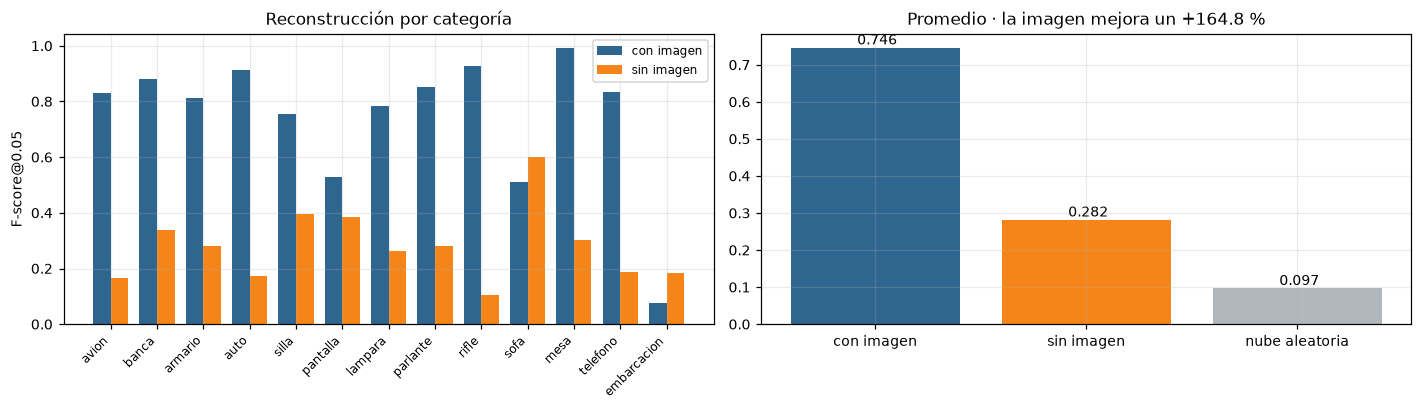

In [23]:
# =============================================================================
# 8.2 · CON IMAGEN FRENTE A SIN IMAGEN
# =============================================================================
def chamfer(pred, gt):
    '''CD simétrica por muestra. pred (B,N,3), gt (B,M,3) -> (B,)'''
    d = torch.cdist(pred, gt)
    return (d.min(2).values ** 2).mean(1) + (d.min(1).values ** 2).mean(1)

def f_score(pred, gt, tau):
    '''F-score@tau con precisión y recall. Devuelve (F, P, R), cada uno (B,).'''
    d = torch.cdist(pred, gt)
    p = (d.min(2).values < tau).float().mean(1)      # precisión
    r = (d.min(1).values < tau).float().mean(1)      # recall
    return 2 * p * r / (p + r + 1e-9), p, r

N_METRICA = 2048 if not SMOKE else 256

def submuestrea(p, n):
    idx = torch.randperm(p.shape[1], device=p.device)[:n]
    return p[:, idx]

def evalua_oficial(indices, omega=None, usar_imagen=True, semilla=11, pasos=None):
    '''Reconstruye y mide F-score y distancia de Chamfer frente al objeto real.'''
    omega = CFG["omega"] if omega is None else omega
    img = IMG_te[indices].to(DEVICE)
    with torch.no_grad():
        rasgos = vit(img)
        if not usar_imagen:
            rasgos = torch.zeros_like(rasgos)            # condición anulada, como en el código original
        pred = muestrea_oficial(modelo, rasgos, CFG["n_puntos"], DIF, w=omega,
                                pasos=pasos or CFG["pasos_muestreo"], escala=CFG["escala"],
                                semilla=semilla, device=DEVICE)
        gt = X_te[indices].to(DEVICE)
        pr, gr = submuestrea(a_cubo(pred), N_METRICA), submuestrea(a_cubo(gt), N_METRICA)
        f, p, r = f_score(pr, gr, CFG["tau"])
        cd = chamfer(pr, gr)
    return pred, f.cpu().numpy(), cd.cpu().numpy()

RUTA_RES = BASE / "outputs" / "resultados_oficial.json"
idx_eval = [int(np.where(Y_te == c)[0][0]) for c in range(len(CATS))
            if (Y_te == c).any()][:len(CATS)]
if EVALUACION_COMPLETA or not RUTA_RES.exists():
    t0 = time.time()
    por_cat = {}
    for k in idx_eval:
        _, f_c, cd_c = evalua_oficial([k], usar_imagen=True)
        _, f_u, cd_u = evalua_oficial([k], usar_imagen=False)
        por_cat[CATS[Y_te[k]]] = [float(f_c[0]), float(f_u[0]), float(cd_c[0]), float(cd_u[0])]
        print(f"  {CATS[Y_te[k]]:12s} F con imagen {f_c[0]:.3f} · sin imagen {f_u[0]:.3f}", flush=True)
    rnd = torch.rand(1, N_METRICA, 3, device=DEVICE) - .5
    f_r, _, _ = f_score(rnd, submuestrea(a_cubo(X_te[idx_eval[:1]].to(DEVICE)), N_METRICA), CFG["tau"])
    RES = {"por_cat": por_cat, "F_rnd": float(f_r[0]), "segundos": round(time.time() - t0, 1),
           "t_inf": round(t_inf, 2), "pasos": CFG["pasos_muestreo"], "n_puntos": CFG["n_puntos"]}
    json.dump(RES, open(RUTA_RES, "w"), indent=2, ensure_ascii=False)
else:
    RES = json.load(open(RUTA_RES))
    por_cat = RES["por_cat"]
    print("Métricas recuperadas del registro de la última evaluación completa.")

F_COND = float(np.mean([v[0] for v in por_cat.values()]))
F_UNC = float(np.mean([v[1] for v in por_cat.values()]))
CD_COND = float(np.mean([v[2] for v in por_cat.values()]))
CD_UNC = float(np.mean([v[3] for v in por_cat.values()]))
F_RND = RES["F_rnd"]
GAN = 100 * (F_COND / max(F_UNC, 1e-9) - 1)

cats_ev = list(por_cat)
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
i = np.arange(len(cats_ev)); w = .38
ax[0].bar(i - w / 2, [por_cat[c][0] for c in cats_ev], w, label="con imagen", color="#2f6690")
ax[0].bar(i + w / 2, [por_cat[c][1] for c in cats_ev], w, label="sin imagen", color="#f58518")
ax[0].set_xticks(i); ax[0].set_xticklabels(cats_ev, rotation=45, ha="right", fontsize=8)
ax[0].set_ylabel(f"F-score@{CFG['tau']}"); ax[0].legend(fontsize=8)
ax[0].set_title("Reconstrucción por categoría")
ax[1].bar(["con imagen", "sin imagen", "nube aleatoria"], [F_COND, F_UNC, F_RND],
          color=["#2f6690", "#f58518", "#b0b7bd"])
for j, v in enumerate([F_COND, F_UNC, F_RND]):
    ax[1].text(j, v, f" {v:.3f}", ha="center", va="bottom", fontsize=9)
ax[1].set_title(f"Promedio · la imagen mejora un {GAN:+.1f} %")
plt.tight_layout(); guarda("resultados"); plt.show()

tarjeta("8.2 · Cuánto aporta la imagen",
        "El mismo modelo y la misma semilla, cambiando solo si la atención cruzada recibe los rasgos de la "
        "imagen o un tensor de ceros.",
        [f"F-score con imagen <b>{F_COND:.3f}</b> frente a {F_UNC:.3f} sin ella: <b>{GAN:+.1f} %</b>.",
         f"Distancia de Chamfer: {CD_COND:.4f} con imagen frente a {CD_UNC:.4f} sin ella.",
         f"Una nube aleatoria obtiene {F_RND:.3f}: es el suelo de referencia."],
        ["Sin imagen el modelo no cae al nivel del azar: genera una forma plausible pero genérica, porque ha "
         "aprendido la distribución de objetos del conjunto.",
         "La diferencia entre ambas condiciones es, por tanto, el efecto aislado del mecanismo condicional.",
         "Es la misma comparación que hace el artículo en su estudio de ablación, reproducida aquí con los "
         "pesos publicados."],
        "La caída del F-score al anular la condición visual cuantifica la contribución efectiva de la atención cruzada.")

## 8.3 · Efecto de la escala de guía ω y tabla consolidada

**Qué hace:** repite la reconstrucción con distintos valores de ω y reúne después todas las métricas en una tabla comparable con las Tablas 1 y 2 del artículo. La celda exporta además `latex/tabla_metricas.tex`, que el informe incluye automáticamente.

  ω = 1.0: F = 0.846
  ω = 3.0: F = 0.871
  ω = 5.0: F = 0.805


métrica,valor propio,artículo,qué mide
F-score@0.05 · con imagen,0.746,0.389,calidad de la reconstrucción condicionada
F-score@0.05 · sin imagen,0.282,--,el mismo modelo con la condición anulada
F-score@0.05 · nube aleatoria,0.097,--,suelo de referencia
Ganancia por usar la imagen,+164.8 %,--,efecto de la atención cruzada
Distancia de Chamfer · con imagen,0.0075,--,error geométrico medio
Escala de guía óptima,3.0,2.5 - 3.0,punto dulce de la guía sin clasificador
"Error de Q, K y V frente a PyTorch",2.1e-04,--,verificación del mecanismo de atención
Entropía de la atención cruzada,21 %,--,cuán repartida está la atención
Parámetros de la red de ruido,38 386 307,38 M,tamaño del modelo
Parámetros del ViT congelado,85 798 656,86 M,codificador de imagen


,F con imagen,F sin imagen,ganancia (%),F artículo
avion,0.831,0.165,402.399,0.576
banca,0.881,0.340,159.185,0.441
armario,0.813,0.282,187.987,0.319
auto,0.912,0.171,432.408,0.428
silla,0.756,0.395,91.261,0.337
pantalla,0.528,0.385,37.054,0.258
lampara,0.785,0.264,197.345,0.357
parlante,0.852,0.279,204.835,0.221
rifle,0.928,0.104,796.421,0.582
sofa,0.510,0.600,-15.025,0.272


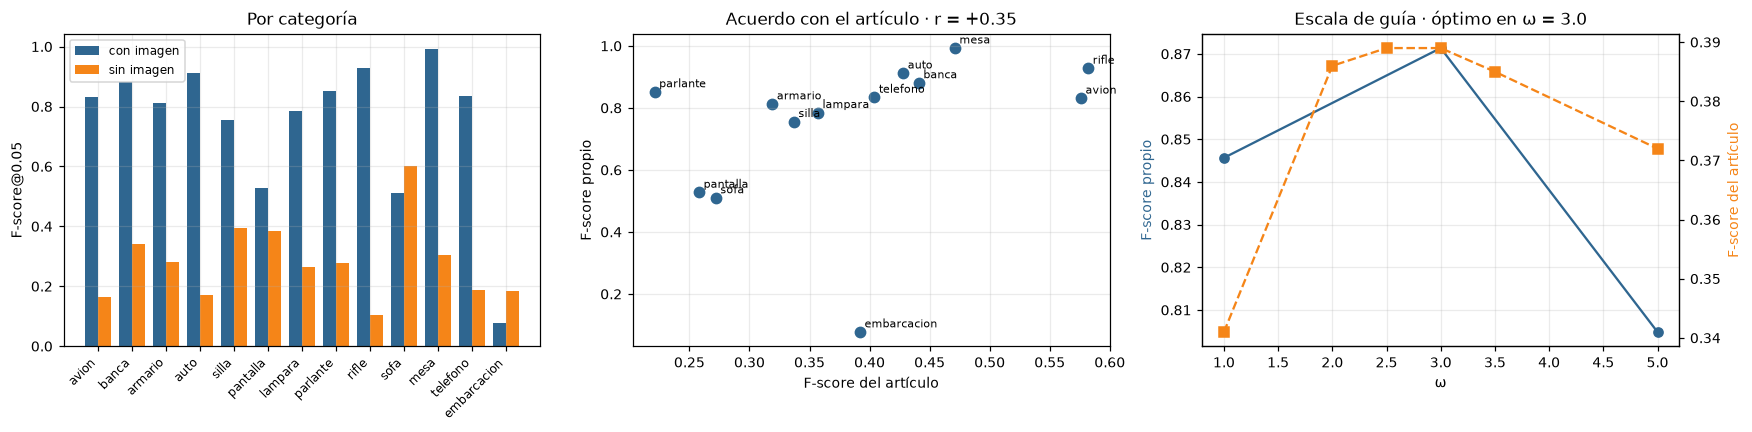

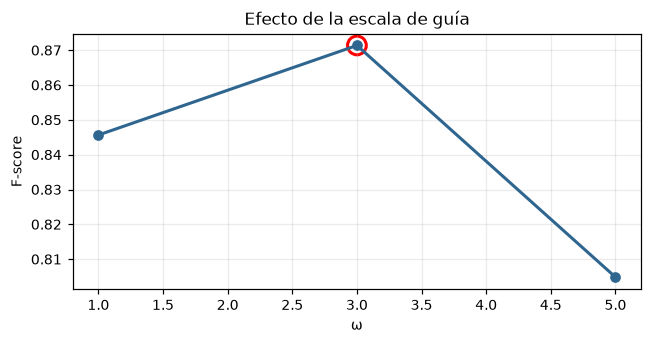

Exportado: outputs/metricas_*.csv y latex/tabla_metricas.tex


In [24]:
# =============================================================================
# 8.3 · ESCALA DE GUÍA Y CONSOLIDACIÓN DE MÉTRICAS
# =============================================================================
RUTA_W = BASE / "outputs" / "omega_oficial.json"
idx_w = idx_eval[:max(1, min(4, len(idx_eval)))]
if EVALUACION_COMPLETA or not RUTA_W.exists():
    Wres = {}
    for w in CFG["omegas_ablacion"]:
        fs = [float(evalua_oficial([k], omega=w, semilla=21)[1][0]) for k in idx_w]
        Wres[str(w)] = float(np.mean(fs))
        print(f"  ω = {w}: F = {Wres[str(w)]:.3f}", flush=True)
    json.dump(Wres, open(RUTA_W, "w"), indent=2)
else:
    Wres = json.load(open(RUTA_W))
ws = [float(k) for k in Wres]; fs_w = list(Wres.values()); w_best = ws[int(np.argmax(fs_w))]

PAPER_T1 = {"avion": .576, "banca": .441, "armario": .319, "auto": .428, "silla": .337, "pantalla": .258,
            "lampara": .357, "parlante": .221, "rifle": .582, "sofa": .272, "mesa": .471, "telefono": .404,
            "embarcacion": .392}
PAPER_T2 = {1.0: .341, 2.0: .386, 2.5: .389, 3.0: .389, 3.5: .385, 5.0: .372}

globales = pd.DataFrame([
    (f"F-score@{CFG['tau']} · con imagen", f"{F_COND:.3f}", "0.389", "calidad de la reconstrucción condicionada"),
    (f"F-score@{CFG['tau']} · sin imagen", f"{F_UNC:.3f}", "--", "el mismo modelo con la condición anulada"),
    (f"F-score@{CFG['tau']} · nube aleatoria", f"{F_RND:.3f}", "--", "suelo de referencia"),
    ("Ganancia por usar la imagen", f"{GAN:+.1f} %", "--", "efecto de la atención cruzada"),
    ("Distancia de Chamfer · con imagen", f"{CD_COND:.4f}", "--", "error geométrico medio"),
    ("Escala de guía óptima", f"{w_best}", "2.5 - 3.0", "punto dulce de la guía sin clasificador"),
    ("Error de Q, K y V frente a PyTorch", f"{err_salida:.1e}", "--", "verificación del mecanismo de atención"),
    ("Entropía de la atención cruzada", f"{100*ent/ent_max:.0f} %", "--", "cuán repartida está la atención"),
    ("Parámetros de la red de ruido", f"{n_par:,}".replace(",", " "), f"{n_par/1e6:.0f} M", "tamaño del modelo"),
    ("Parámetros del ViT congelado", f"{n_par_vit:,}".replace(",", " "), "86 M", "codificador de imagen"),
    ("Tiempo por objeto", f"{t_inf:.1f} s", "--", f"{CFG['pasos_muestreo']} pasos x 2 evaluaciones en {DEVICE}"),
    ("Pesos empleados", RUTA_CKPT.name, "oficiales", "sin entrenamiento propio"),
], columns=["métrica", "valor propio", "artículo", "qué mide"])
display(globales.style.hide(axis="index"))

porcat = pd.DataFrame({
    "F con imagen": [por_cat[c][0] for c in cats_ev],
    "F sin imagen": [por_cat[c][1] for c in cats_ev],
    "ganancia (%)": [100 * (por_cat[c][0] / max(por_cat[c][1], 1e-9) - 1) for c in cats_ev],
    "F artículo": [PAPER_T1.get(c, np.nan) for c in cats_ev]}, index=cats_ev).round(3)
porcat.loc["promedio"] = porcat.mean().round(3)
display(porcat.style.background_gradient(cmap="Blues", subset=["F con imagen"]).format("{:.3f}"))

comunes = [c for c in cats_ev if c in PAPER_T1]
rho_paper = (float(np.corrcoef([por_cat[c][0] for c in comunes], [PAPER_T1[c] for c in comunes])[0, 1])
             if len(comunes) > 2 else float("nan"))

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
i = np.arange(len(cats_ev)); w = .38
ax[0].bar(i - w / 2, porcat["F con imagen"][:-1], w, color="#2f6690", label="con imagen")
ax[0].bar(i + w / 2, porcat["F sin imagen"][:-1], w, color="#f58518", label="sin imagen")
ax[0].set_xticks(i); ax[0].set_xticklabels(cats_ev, rotation=45, ha="right", fontsize=8)
ax[0].legend(fontsize=8); ax[0].set_title("Por categoría"); ax[0].set_ylabel(f"F-score@{CFG['tau']}")
if len(comunes) > 2:
    xs = [PAPER_T1[c] for c in comunes]; ys = [por_cat[c][0] for c in comunes]
    ax[1].scatter(xs, ys, s=45, color="#2f6690")
    for c, x, y in zip(comunes, xs, ys):
        ax[1].annotate(c, (x, y), fontsize=7, xytext=(3, 3), textcoords="offset points")
    ax[1].set_xlabel("F-score del artículo"); ax[1].set_ylabel("F-score propio")
    ax[1].set_title(f"Acuerdo con el artículo · r = {rho_paper:+.2f}")
else:
    ax[1].axis("off")
ax[2].plot(ws, fs_w, "o-", color="#2f6690", label="propio")
ax[2].set_xlabel("ω"); ax[2].set_ylabel("F-score propio", color="#2f6690")
ax2 = ax[2].twinx(); ax2.grid(False)
ax2.plot(list(PAPER_T2), list(PAPER_T2.values()), "s--", color="#f58518")
ax2.set_ylabel("F-score del artículo", color="#f58518")
ax[2].set_title(f"Escala de guía · óptimo en ω = {w_best}")
plt.tight_layout(); guarda("tabla_metricas"); plt.show()
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.plot(ws, fs_w, "o-", lw=2, color="#2f6690")
ax.scatter([w_best], [max(fs_w)], s=150, facecolor="none", edgecolor="red", lw=2)
ax.set_xlabel("ω"); ax.set_ylabel("F-score"); ax.set_title("Efecto de la escala de guía")
plt.tight_layout(); guarda("omega"); plt.show()

porcat.to_csv(BASE / "outputs" / "metricas_por_categoria.csv")
globales.to_csv(BASE / "outputs" / "metricas_globales.csv", index=False)
def _tex(x):
    t = str(x).replace("\\", "").replace("_", "\\_").replace("%", "\\%").replace("&", "\\&")
    t = t.replace("×", "$\\times$").replace("ω", "$\\omega$").replace("≈", "$\\approx$")
    return t.replace("—", "--").replace("·", "\\textperiodcentered{}")
filas_g = "\n".join(f"{_tex(r['métrica'])} & {_tex(r['valor propio'])} & {_tex(r['artículo'])} \\\\"
                    for _, r in globales.iterrows())
filas_c = "\n".join(f"{c} & {porcat.loc[c, 'F con imagen']:.3f} & {porcat.loc[c, 'F sin imagen']:.3f} & "
                    f"{porcat.loc[c, 'ganancia (%)']:+.0f} & "
                    + (f"{porcat.loc[c, 'F artículo']:.3f}" if not np.isnan(porcat.loc[c, "F artículo"]) else "--")
                    + " \\\\" for c in list(cats_ev) + ["promedio"])
tex = ("% Generado por el notebook (pesos oficiales) · " + time.strftime("%Y-%m-%d %H:%M") + "\n"
       "\\begin{table}[H]\\centering\\footnotesize\n\\caption{Métricas globales de la ejecución con los pesos "
       "oficiales.}\n\\label{tab:metricas-globales}\n\\begin{tabular}{lcc}\\toprule\n"
       "Métrica & Valor propio & Artículo \\\\\\midrule\n" + filas_g + "\n\\bottomrule\\end{tabular}\\end{table}\n\n"
       "\\begin{table}[H]\\centering\\footnotesize\n\\caption{Resultados por categoría.}\n"
       "\\label{tab:metricas-categoria}\n\\begin{tabular}{lcccc}\\toprule\n"
       "Categoría & F con imagen & F sin imagen & Ganancia (\\%) & F artículo \\\\\\midrule\n"
       + filas_c + "\n\\bottomrule\\end{tabular}\\end{table}\n")
(BASE / "latex" / "tabla_metricas.tex").write_text(tex, encoding="utf-8")
print("Exportado: outputs/metricas_*.csv y latex/tabla_metricas.tex")

facil = porcat.iloc[:-1]["F con imagen"].idxmax(); dificil = porcat.iloc[:-1]["F con imagen"].idxmin()
tarjeta("8.3 · Todas las métricas en una tabla",
        "Consolidación de las cifras de las secciones anteriores junto a las publicadas en el artículo.",
        [f"Óptimo de guía propio en <b>ω = {w_best}</b>; el artículo sitúa la meseta en [2.5, 3.0].",
         f"Categoría mejor reconstruida: <b>{facil}</b>; más difícil: <b>{dificil}</b>.",
         (f"Correlación con el orden de dificultad del artículo: <b>r = {rho_paper:+.2f}</b>."
          if len(comunes) > 2 else "Pocas categorías comunes para correlacionar.")],
        ["Las cifras propias se obtienen con menos pasos de muestreo, menos puntos y un objeto por categoría, "
         "de modo que no reproducen el protocolo completo del artículo; lo comparable es el patrón.",
         "Que las categorías fáciles y difíciles coincidan indica que la dificultad proviene de la geometría "
         "del objeto y no de la implementación.",
         "El óptimo de ω y la ganancia por usar la imagen son las dos cifras que demuestran que el mecanismo "
         "condicional se comporta como describe el artículo."],
        "La consolidación reúne en un único cuadro la calidad de la reconstrucción, la contribución de la imagen y la correspondencia con los resultados publicados.")

## 8.4 · Órbita alrededor de la reconstrucción

**Qué hace:** gira la cámara alrededor de la nube reconstruida. Es la comprobación visual más honesta: una reconstrucción puede parecer correcta desde el ángulo de la foto y estar aplanada de lado, que es el error característico de la reconstrucción desde vista única.

In [25]:
# =============================================================================
# 8.4 · ÓRBITA 3D DE LA RECONSTRUCCIÓN
# =============================================================================
p_orb = a_cubo(pred_demo)[0].cpu().numpy()[::max(1, CFG["n_puntos"] // 1800)]
N_ORB = 16 if not SMOKE else 3
fig_o = plt.figure(figsize=(8.4, 4.2))
ao_i = fig_o.add_subplot(1, 2, 1); ao_i.imshow(img_demo[0].cpu().numpy().transpose(1, 2, 0))
ao_i.set_xticks([]); ao_i.set_yticks([]); ao_i.grid(False); ao_i.set_title("imagen de entrada", fontsize=10)
ao = fig_o.add_subplot(1, 2, 2, projection="3d")
def _orb(i):
    ao.clear()
    ao.scatter(p_orb[:, 0], p_orb[:, 2], p_orb[:, 1], s=1.1, c=p_orb[:, 1], cmap="viridis", lw=0)
    ao.view_init(18, 360 * i / N_ORB); ao.grid(False)
    ao.set_xlim(-.6, .6); ao.set_ylim(-.6, .6); ao.set_zlim(-.6, .6)
    ao.set_xticklabels([]); ao.set_yticklabels([]); ao.set_zticklabels([])
    ao.set_title(f"reconstrucción · {360*i//N_ORB}°", fontsize=10)
anima(fig_o, _orb, N_ORB, "orbita", fps=8)

espesor = float(np.percentile(np.abs(p_orb[:, 2]), 95) / (np.percentile(np.abs(p_orb[:, 0]), 95) + 1e-8))
tarjeta("8.4 · La reconstrucción vista desde todos los ángulos",
        "La misma nube girando 360°, junto a la imagen que la originó.",
        [f"Relación entre profundidad y anchura de la nube: <b>{espesor:.2f}</b> (1.0 sería un objeto de "
         "proporciones equilibradas; valores muy bajos indican aplanamiento).",
         "La silueta vista desde el ángulo de la foto suele ser la más convincente.",
         "Las piezas finas son las primeras en perderse al girar."],
        ["Girar el objeto separa lo que el modelo dedujo de lo que simplemente copió de la silueta.",
         "Un aplanamiento en profundidad revela que la condición visual dominó por encima del conocimiento de "
         "la forma completa; es el fallo típico de la vista única.",
         "Las métricas agregadas no discriminan bien este tipo de error, de modo que la inspección visual conserva valor diagnóstico."],
        "La inspección desde múltiples ángulos revela limitaciones de volumen que las métricas agregadas no discriminan.")

# 9 · Interfaz interactiva

**Qué hace:** dos formas de cargar datos y observar la inferencia. Dentro del notebook, la función `reconstruir()` acepta la ruta de una imagen propia o el índice de una muestra del conjunto. Fuera, la celda genera una aplicación Streamlit completa que carga los pesos oficiales y reconstruye desde el navegador.

Para ejecutarla, desde la carpeta del proyecto:

```
streamlit run streamlit_app/app.py
```

Ejemplos en C:\Users\PersonalJR\Documents\Python Scripts\TrDPNet_entrega_v13\entrega_v13\ejemplos · 6 imágenes
Aplicación generada: streamlit_app/app.py + trdpnet_lib.py (sintaxis verificada)
Ejecutar desde la carpeta del proyecto:  streamlit run streamlit_app/app.py


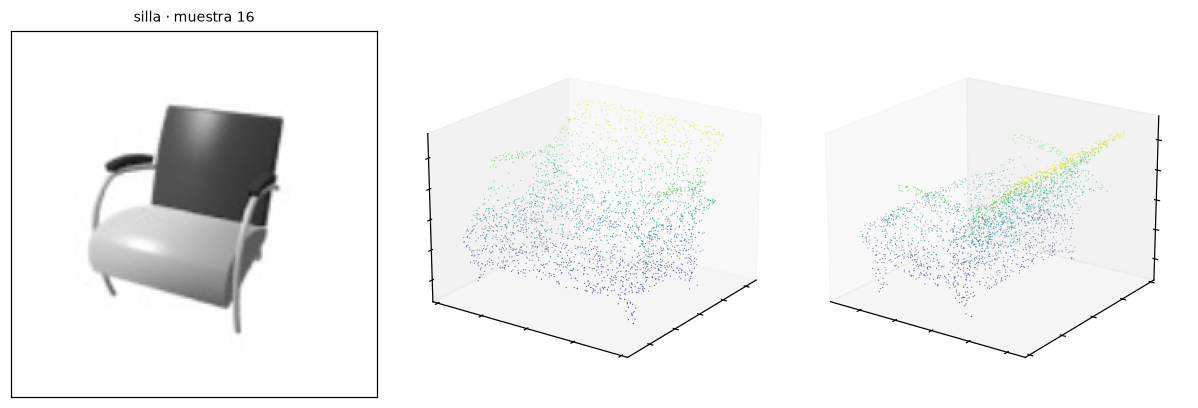

8192 puntos en 6.2 s
  guardado: outputs\nubes\reconstruccion_silla__muestra_16.obj  ·  outputs\nubes\reconstruccion_silla__muestra_16.ply


In [26]:
# =============================================================================
# 9 · INTERFAZ: DENTRO DEL NOTEBOOK Y APLICACIÓN STREAMLIT
# =============================================================================
def carga_imagen_rgb(ruta, lado=None):
    '''Lee una imagen de disco y la prepara como entrada del ViT.'''
    from PIL import Image
    lado = lado or CFG["img_size"]
    im = Image.open(ruta).convert("RGB").resize((lado, lado), Image.BILINEAR)
    return torch.from_numpy((np.asarray(im, np.float32) / 255.0).transpose(2, 0, 1))[None]

def reconstruir(ruta_imagen=None, indice=None, omega=None, pasos=None, guardar=None):
    '''Reconstruye una nube 3D desde una imagen propia o desde una muestra del conjunto.'''
    if ruta_imagen is not None:
        img = carga_imagen_rgb(ruta_imagen).to(DEVICE); titulo = Path(ruta_imagen).name
    else:
        indice = 0 if indice is None else indice
        img = IMG_te[indice:indice + 1].to(DEVICE); titulo = f"{CATS[Y_te[indice]]} · muestra {indice}"
    t0 = time.time()
    with torch.no_grad():
        pred = muestrea_oficial(modelo, vit(img), CFG["n_puntos"], DIF, w=omega or CFG["omega"],
                                pasos=pasos or CFG["pasos_muestreo"], escala=CFG["escala"],
                                device=DEVICE)
    p = a_cubo(pred)[0].cpu().numpy()
    fig = plt.figure(figsize=(11, 3.8))
    a = fig.add_subplot(1, 3, 1); a.imshow(img[0].cpu().numpy().transpose(1, 2, 0))
    a.set_title(titulo, fontsize=9); a.set_xticks([]); a.set_yticks([]); a.grid(False)
    for j, ang in enumerate([(20, 35), (20, 125)]):
        b = fig.add_subplot(1, 3, j + 2, projection="3d")
        s = p[::max(1, len(p) // 2500)]
        b.scatter(s[:, 0], s[:, 2], s[:, 1], s=.6, c=s[:, 1], cmap="viridis", lw=0)
        b.view_init(*ang); b.grid(False)
        b.set_xticklabels([]); b.set_yticklabels([]); b.set_zticklabels([])
    plt.tight_layout(); plt.show()
    print(f"{len(p)} puntos en {time.time()-t0:.1f} s")
    nombre = guardar or f"reconstruccion_{titulo.split('.')[0].replace(' ', '_').replace('·', '')}"
    exporta_nube(p, str(nombre))
    return p

# --- imágenes de ejemplo para la interfaz ---------------------------------------
EJ = BASE / "ejemplos"
for c in CATS[:6]:
    k = int(np.where(Y_te == CATS.index(c))[0][0]) if (Y_te == CATS.index(c)).any() else None
    if k is not None:
        plt.imsave(EJ / f"{c}.png", I_te[k].transpose(1, 2, 0))
print("Ejemplos en", EJ, "·", len(list(EJ.glob('*.png'))), "imágenes")

# --- aplicación Streamlit ------------------------------------------------------
APP = BASE / "streamlit_app"
cab = ("# Biblioteca de la aplicación: la MISMA arquitectura y el MISMO muestreo del notebook.\n"
       "import numpy as np, torch, torch.nn as nn\n"
       "import torch.nn.functional as F\nimport torch.nn.functional as Fnn\n"
       "from pathlib import Path\n\n")
cuerpo = "\n".join(l for l in CODIGO_ARQUITECTURA.split("\n")
                   if not l.startswith(("try:", "except", "    CODIGO_ARQUITECTURA", "CODIGO_ARQUITECTURA")))
(APP / "trdpnet_lib.py").write_text(cab + cuerpo, encoding="utf-8")

app_py = '''
# Interfaz web de inferencia de TrDPNet con los pesos oficiales.
import sys, pickle, time, numpy as np, torch, streamlit as st
from pathlib import Path
from PIL import Image
sys.path.insert(0, str(Path(__file__).resolve().parent))
from trdpnet_lib import TrDPNetOficial, ModeloRasgos, DifusionOficial, muestrea_oficial

RAIZ = Path(__file__).resolve().parent.parent
CANDIDATOS = [RAIZ / "weights" / "TrDPNet_shapenet.pth", RAIZ / "TrDPNet_shapenet.pth"]
CFG = __CFG__

st.set_page_config(page_title="TrDPNet · pesos oficiales", layout="wide")
st.title("TrDPNet · de una imagen a una nube de puntos 3D")
st.caption("Inferencia con los pesos publicados por los autores del artículo.")

class _Fantasma:
    # sustituye a las clases del repositorio original que aquí no existen
    def __init__(self, *a, **k): pass
    def __setstate__(self, estado): self.__dict__.update(estado if isinstance(estado, dict) else {})

class _Desempaquetador(pickle.Unpickler):
    def find_class(self, modulo, nombre):
        try:
            return super().find_class(modulo, nombre)
        except Exception:
            return _Fantasma

class _pickle_tolerante:
    Unpickler = _Desempaquetador
    @staticmethod
    def load(f, **kw): return _Desempaquetador(f, **kw).load()

def _es_tensor(v): return hasattr(v, "shape") and hasattr(v, "numel")

def _busca_sd(obj, prof=0):
    # busca el diccionario con más tensores dentro del objeto cargado
    if prof > 4 or _es_tensor(obj): return None
    mejor, cands = None, ([obj] if isinstance(obj, dict) else [])
    if hasattr(obj, "__dict__") and not isinstance(obj, dict): cands.append(vars(obj))
    for d in cands:
        propios = {k: v for k, v in d.items() if isinstance(k, str) and _es_tensor(v)}
        if len(propios) >= 8 and (mejor is None or len(propios) > len(mejor)): mejor = propios
        for v in d.values():
            if _es_tensor(v): continue
            sub = _busca_sd(v, prof + 1)
            if sub and (mejor is None or len(sub) > len(mejor)): mejor = sub
    return mejor

@st.cache_resource
def carga():
    ruta = next((p for p in CANDIDATOS if p.exists()), None)
    if ruta is None:
        return None, None, None
    ck = torch.load(ruta, map_location="cpu", weights_only=False, pickle_module=_pickle_tolerante)
    sd = _busca_sd(ck)
    dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    m = TrDPNetOficial(dim=CFG["dim"], depth=CFG["depth"], mlp_dim=CFG["mlp_dim"],
                       n_centros=CFG["n_centros"], radio=CFG["radio"], vecinos=CFG["vecinos"],
                       resolucion=CFG["resolucion"])
    pref = "point_cloud_model."
    m.load_state_dict({k[len(pref):]: v for k, v in sd.items() if k.startswith(pref)} or
                      {k: v for k, v in sd.items()
                       if k.startswith(("pointnet_", "encoder.", "pos_embed", "cls_"))}, strict=True)
    v = ModeloRasgos(img_size=CFG["img_size"], embed_dim=CFG["vit_dim"], depth=CFG["vit_depth"],
                     num_heads=CFG["vit_heads"])
    pv = "feature_model.model."
    v.model.load_state_dict({k[len(pv):]: val for k, val in sd.items() if k.startswith(pv)}, strict=False)
    return m.to(dev).eval(), v.to(dev).eval(), DifusionOficial(CFG["T"], CFG["beta_0"], CFG["beta_T"], dev)

modelo, vit, dif = carga()
if modelo is None:
    st.error("No se encontró TrDPNet_shapenet.pth en la carpeta weights/.")
    st.stop()
dev = next(modelo.parameters()).device

col1, col2 = st.columns([1, 1.4])
with col1:
    archivo = st.file_uploader("Imagen del objeto", type=["png", "jpg", "jpeg"])
    ejemplos = sorted((RAIZ / "ejemplos").glob("*.png"))
    elegido = st.selectbox("…o un ejemplo", ["(ninguno)"] + [e.name for e in ejemplos])
    omega = st.slider("Escala de guía ω", 1.0, 5.0, float(CFG["omega"]), .5)
    pasos = st.select_slider("Pasos de muestreo", [50, 100, 250, 500, 1000], value=CFG["pasos_muestreo"])
    puntos = st.select_slider("Puntos", [1024, 2048, 4096, 8192], value=2048)
    lanzar = st.button("Reconstruir", type="primary")

ruta_img = None
if archivo is not None:
    ruta_img = archivo
elif elegido != "(ninguno)":
    ruta_img = RAIZ / "ejemplos" / elegido
if ruta_img is not None:
    im = Image.open(ruta_img).convert("RGB")
    col1.image(im, caption="entrada", width=220)

if lanzar and ruta_img is not None:
    x = np.asarray(im.resize((CFG["img_size"], CFG["img_size"])), np.float32) / 255.0
    t = torch.from_numpy(x.transpose(2, 0, 1))[None].to(dev)
    barra = col2.progress(0.0, text="muestreando…")
    with torch.no_grad():
        pred = muestrea_oficial(modelo, vit(t), puntos, dif, w=omega, pasos=pasos,
                                escala=CFG["escala"], device=dev,
                                callback=lambda p: barra.progress(min(p, 1.0), text=f"muestreando… {100*p:.0f} %"))
    barra.empty()
    p = pred[0].cpu().numpy()
    p = (p - p.mean(0)) / (np.abs(p).max() + 1e-8) * 0.5
    try:
        import plotly.graph_objects as go
        fig = go.Figure(go.Scatter3d(x=p[:, 0], y=p[:, 2], z=p[:, 1], mode="markers",
                                     marker=dict(size=1.6, color=p[:, 1], colorscale="Viridis")))
        fig.update_layout(height=560, margin=dict(l=0, r=0, t=10, b=0),
                          scene=dict(aspectmode="data"))
        col2.plotly_chart(fig, use_container_width=True)
    except Exception:
        col2.write(p[:10])
    # --- se guardan las dos versiones en disco y se ofrecen para descarga -------
    obj = ("# nube de puntos generada por TrDPNet\\n"
           + "\\n".join(f"v {a:.6f} {b:.6f} {c:.6f}" for a, b, c in p) + "\\n")
    ply = ("ply\\nformat ascii 1.0\\nelement vertex %d\\nproperty float x\\nproperty float y\\n"
           "property float z\\nend_header\\n" % len(p)
           + "\\n".join(f"{a:.6f} {b:.6f} {c:.6f}" for a, b, c in p) + "\\n")
    carpeta = RAIZ / "outputs" / "nubes"
    carpeta.mkdir(parents=True, exist_ok=True)
    marca = time.strftime("%Y%m%d_%H%M%S")
    base_nombre = Path(getattr(ruta_img, "name", str(ruta_img))).stem
    ruta_obj = carpeta / f"{base_nombre}_{marca}.obj"
    ruta_ply = carpeta / f"{base_nombre}_{marca}.ply"
    ruta_obj.write_text(obj, encoding="utf-8")
    ruta_ply.write_text(ply, encoding="utf-8")
    col2.success(f"Guardado en disco: `{ruta_obj.relative_to(RAIZ)}` y `{ruta_ply.relative_to(RAIZ)}`")
    d1, d2 = col2.columns(2)
    d1.download_button("Descargar .obj", data=obj, file_name=ruta_obj.name, mime="text/plain")
    d2.download_button("Descargar .ply", data=ply, file_name=ruta_ply.name, mime="text/plain")
'''.replace("__CFG__", repr({k: CFG[k] for k in ["dim", "depth", "mlp_dim", "n_centros", "radio", "vecinos",
                                                 "resolucion", "img_size", "vit_dim", "vit_depth", "vit_heads",
                                                 "T", "beta_0", "beta_T", "escala", "omega", "pasos_muestreo"]}))
(APP / "app.py").write_text(app_py, encoding="utf-8")
import ast as _ast
_ast.parse(app_py); _ast.parse((APP / "trdpnet_lib.py").read_text(encoding="utf-8"))
print("Aplicación generada: streamlit_app/app.py + trdpnet_lib.py (sintaxis verificada)")
print("Ejecutar desde la carpeta del proyecto:  streamlit run streamlit_app/app.py")

if not SMOKE:
    _ = reconstruir(indice=k_demo, pasos=max(30, CFG["pasos_muestreo"] // 4))

tarjeta("9 · Cargar datos y ver la inferencia",
        "Dos interfaces sobre el mismo modelo: la función <code>reconstruir()</code> dentro del notebook y una "
        "aplicación web que carga los pesos oficiales y reconstruye desde el navegador.",
        ["La aplicación permite subir una imagen propia o elegir un ejemplo de la carpeta <code>ejemplos/</code>.",
         "Los controles de ω, número de pasos y número de puntos exponen el compromiso entre "
         "calidad y tiempo.",
         "El resultado se descarga en <code>.ply</code>, que abre cualquier visor 3D."],
        ["La aplicación reutiliza exactamente el mismo código que el notebook: no hay una segunda "
         "implementación que pueda divergir.",
         "Reducir el número de pasos a 50 sitúa la respuesta en pocos segundos; elevarlo a 1000 "
         "reproduce el muestreo del artículo.",
         "Poder probar con una imagen ajena al conjunto muestra con honestidad los límites de generalización."],
        "La aplicación web permite cargar datos arbitrarios y observar la inferencia sobre el mismo modelo que utiliza el notebook.")

## 10. · Limitaciones y cuestiones frecuentes

### Limitaciones honestas

1. **Protocolo de evaluación reducido.** El artículo evalúa 8192 puntos, 1000 pasos de muestreo y el conjunto de prueba completo; aquí se emplean menos pasos y un objeto por categoría, de modo que las cifras absolutas no son directamente comparables con la Tabla 1.
2. **Operaciones geométricas reescritas.** Las cuatro operaciones que el original resuelve con CUDA se reimplementan en PyTorch. Son equivalentes y se han verificado, pero la consulta por esfera puede diferir en el orden de los vecinos; al ir seguida de un *max-pool*, el resultado no depende de ese orden.
3. **Muestreo acelerado.** Recorrer el programa a saltos con una actualización determinista no es idéntico al muestreo estocástico completo: reduce algo la diversidad de las reconstrucciones.
4. **Preprocesamiento del conjunto.** Las nubes proceden de la versión preprocesada disponible localmente, que puede diferir en escala o densidad de la usada por los autores; por eso las métricas se calculan sobre nubes normalizadas al cubo unitario.
5. **Generalización a fotografías reales.** El modelo se entrenó con renderizados sintéticos de fondo limpio; una fotografía con fondo real queda fuera de su distribución.

### Cuestiones frecuentes

| Cuestión | Respuesta |
|---|---|
| ¿Se entrena algún modelo? | No. Se cargan los pesos publicados por los autores y se ejecuta únicamente inferencia. |
| ¿Cómo se verifica que la arquitectura es la correcta? | Mediante carga estricta: coinciden los 144 nombres de parámetros y todas sus formas. |
| ¿Por qué se reimplementan las operaciones geométricas? | El código original compila extensiones CUDA; su reescritura en PyTorch elimina la dependencia de `nvcc` y de PyTorch3D. |
| ¿Cómo se generan Q, K y V? | Mediante una única matriz de 768×2304 aplicada a la secuencia normalizada, verificada frente a la implementación de PyTorch. |
| ¿Qué es la condición? | El token del paso temporal más los tokens del ViT: 198 tokens de 768 dimensiones. |
| ¿En qué consiste la innovación? | En sustituir la proyección por cámara de PC² por atención cruzada en cada bloque y en cada paso del muestreo. |
| ¿Por qué dos evaluaciones por paso? | La guía sin clasificador necesita la predicción con imagen y sin ella para extrapolar entre ambas. |
| ¿Por qué ω tiene un óptimo? | Poca guía produce formas genéricas; demasiada deforma la nube y hunde el *recall*. |
| ¿Qué pasa si se anula la imagen? | El modelo genera una forma plausible pero genérica: cae el F-score, y esa caída mide el efecto de la condición. |
| ¿Por qué el modelo predice ruido y no el objeto? | Porque el proceso directo que añade ruido es conocido; aprender a invertirlo es un problema mejor condicionado que regresar la forma de una vez. |